In [2]:
# STEP 0：実行前の準備
# STEP 8-9 は支援履歴ファイル（support_history.jsonl）を読み込みます。
# 新しいランタイムにはこのファイルがまだ無いため、空のファイルを作り「履歴0件」から始めます。
# 既にファイルがある場合、中身は変更しません（何度実行しても安全です）。
from pathlib import Path
sandbox = Path("/content/chinaemon_sandbox")
sandbox.mkdir(parents=True, exist_ok=True)
(sandbox / "support_history.jsonl").touch()
print("準備完了:", sandbox / "support_history.jsonl")

準備完了: /content/chinaemon_sandbox/support_history.jsonl


In [3]:
print("知奈えもん、起動成功！🐱🤖")
print("Physical AI プロジェクト開始")

知奈えもん、起動成功！🐱🤖
Physical AI プロジェクト開始


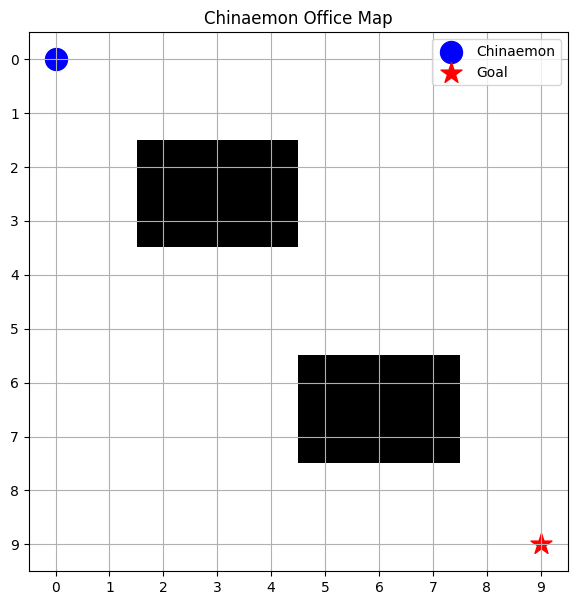

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# オフィスの広さ（縦10マス × 横10マス）
office = np.zeros((10, 10))

# 机などの障害物を配置（1 = 障害物）
office[2:4, 2:5] = 1
office[6:8, 5:8] = 1

# 知奈えもんの出発地点
robot = (0, 0)

# 担当者のいる目的地
goal = (9, 9)

# マップ表示
plt.figure(figsize=(7, 7))
plt.imshow(office, cmap="Greys", origin="upper")

plt.scatter(robot[1], robot[0], c="blue", s=250, label="Chinaemon")
plt.scatter(goal[1], goal[0], c="red", s=250, marker="*", label="Goal")

plt.xticks(range(10))
plt.yticks(range(10))
plt.grid()
plt.legend()
plt.title("Chinaemon Office Map")
plt.show()


In [5]:

import heapq

# A*経路探索
def astar(office, start, goal):
    rows, cols = office.shape

    # ゴールまでの推定距離
    def heuristic(a, b):
        return abs(a[0] - b[0]) + abs(a[1] - b[1])

    queue = [(heuristic(start, goal), 0, start)]
    came_from = {}
    cost_so_far = {start: 0}

    while queue:
        _, cost, current = heapq.heappop(queue)

        if cost > cost_so_far[current]:
            continue

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)
            return path[::-1]

        # 上下左右の4方向に移動
        for dr, dc in [(-1,0), (1,0), (0,-1), (0,1)]:
            nr = current[0] + dr
            nc = current[1] + dc
            next_pos = (nr, nc)

            if 0 <= nr < rows and 0 <= nc < cols:
                if office[nr, nc] == 0:
                    new_cost = cost + 1

                    if (next_pos not in cost_so_far or
                        new_cost < cost_so_far[next_pos]):
                        cost_so_far[next_pos] = new_cost
                        priority = new_cost + heuristic(next_pos, goal)
                        heapq.heappush(
                            queue, (priority, new_cost, next_pos)
                        )
                        came_from[next_pos] = current

    return None

# 経路を計算
path = astar(office, robot, goal)

print("知奈えもんの移動経路：")
print(path)
print("移動ステップ数：", len(path) - 1 if path else "経路なし")


知奈えもんの移動経路：
[(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]
移動ステップ数： 18


In [6]:

import matplotlib.animation as animation
from IPython.display import HTML, display

# アニメーション用の画面
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(office, cmap="Greys", origin="upper")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.grid()

ax.set_title("Chinaemon Autonomous Navigation")

# 目的地
ax.scatter(goal[1], goal[0],
           c="red", s=250, marker="*", label="Goal")

# 知奈えもん
robot_dot, = ax.plot([], [], "bo", markersize=15,
                     label="Chinaemon")

ax.legend()

# 1ステップずつ移動
def update(frame):
    row, col = path[frame]
    robot_dot.set_data([col], [row])
    ax.set_title(
        f"Chinaemon Autonomous Navigation - Step {frame}"
    )
    return robot_dot,

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(path),
    interval=400,
    blit=True,
    repeat=False
)

plt.close(fig)

# Colab上でアニメーションを表示
display(HTML(ani.to_jshtml()))


In [7]:

# 動的障害物回避のシミュレーション

# 元のオフィスマップをコピー
dynamic_office = office.copy()

# 最初の経路を取得
initial_path = astar(dynamic_office, robot, goal)

# 5ステップ進んだ地点
current_position = initial_path[5]

print("知奈えもん、移動開始！")
print("現在位置：", current_position)

# 次に進む予定の場所に障害物が出現
blocked_position = initial_path[6]
dynamic_office[blocked_position] = 1

print("⚠️ 新しい障害物を検知！")
print("障害物の位置：", blocked_position)

# 現在位置から経路を再計算
new_path = astar(
    dynamic_office,
    current_position,
    goal
)

if new_path is not None:
    print("✅ 迂回経路を発見！")
    print("新しい経路：", new_path)
    print("残りの移動ステップ数：", len(new_path) - 1)
else:
    print("❌ 目的地までの経路がありません")


知奈えもん、移動開始！
現在位置： (0, 5)
⚠️ 新しい障害物を検知！
障害物の位置： (0, 6)
✅ 迂回経路を発見！
新しい経路： [(0, 5), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]
残りの移動ステップ数： 13


In [8]:

# 障害物出現前後の移動経路を結合
full_path = initial_path[:6] + new_path[1:]

# アニメーション画面
fig, ax = plt.subplots(figsize=(7, 7))

robot_dot, = ax.plot([], [], "bo", markersize=15)
obstacle_image = ax.imshow(
    office.copy(), cmap="Greys",
    origin="upper", vmin=0, vmax=1
)

ax.scatter(goal[1], goal[0],
           c="red", s=250, marker="*")

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.grid()

# アニメーション更新処理
def update_dynamic(frame):
    row, col = full_path[frame]
    robot_dot.set_data([col], [row])

    if frame >= 5:
        obstacle_image.set_data(dynamic_office)
        status = "Obstacle detected! Rerouting"
    else:
        obstacle_image.set_data(office)
        status = "Moving"

    ax.set_title(
        f"Chinaemon - Step {frame}: {status}"
    )
    return robot_dot, obstacle_image

ani_dynamic = animation.FuncAnimation(
    fig,
    update_dynamic,
    frames=len(full_path),
    interval=500,
    blit=False,
    repeat=False
)

plt.close(fig)
display(HTML(ani_dynamic.to_jshtml()))


In [9]:

import pandas as pd

# プロジェクトのサンプルデータ
tasks = [
    {"タスク": "要件定義", "担当者": "田中", "計画進捗": 100, "実績進捗": 100, "納期までの日数": 0},
    {"タスク": "基本設計", "担当者": "佐藤", "計画進捗": 90, "実績進捗": 85, "納期までの日数": 3},
    {"タスク": "詳細設計", "担当者": "鈴木", "計画進捗": 80, "実績進捗": 55, "納期までの日数": 5},
    {"タスク": "開発", "担当者": "高橋", "計画進捗": 60, "実績進捗": 30, "納期までの日数": 7},
    {"タスク": "テスト", "担当者": "伊藤", "計画進捗": 20, "実績進捗": 10, "納期までの日数": 14}
]

df = pd.DataFrame(tasks)

# 計画と実績の進捗差を計算
df["進捗遅延"] = df["計画進捗"] - df["実績進捗"]

# 遅延リスクを判定
def judge_risk(row):
    delay = row["進捗遅延"]
    days = row["納期までの日数"]

    if delay >= 20 or (delay >= 10 and days <= 5):
        return "高"
    elif delay >= 10 or (delay > 0 and days <= 3):
        return "中"
    else:
        return "低"

df["遅延リスク"] = df.apply(judge_risk, axis=1)

# 結果を表示
print("🐱 知奈えもん：プロジェクト遅延リスク分析結果")
display(df)

# 高リスクタスクを抽出
high_risk = df[df["遅延リスク"] == "高"]

print("\n⚠️ 支援が必要な高リスクタスク")
display(high_risk)


🐱 知奈えもん：プロジェクト遅延リスク分析結果


,タスク,担当者,計画進捗,実績進捗,納期までの日数,進捗遅延,遅延リスク
0,要件定義,田中,100,100,0,0,低
1,基本設計,佐藤,90,85,3,5,中
2,詳細設計,鈴木,80,55,5,25,高
3,開発,高橋,60,30,7,30,高
4,テスト,伊藤,20,10,14,10,中



⚠️ 支援が必要な高リスクタスク


,タスク,担当者,計画進捗,実績進捗,納期までの日数,進捗遅延,遅延リスク
2,詳細設計,鈴木,80,55,5,25,高
3,開発,高橋,60,30,7,30,高


In [10]:

# 支援優先度スコアの計算

def calculate_priority(row):
    # 進捗遅延（最大50点）
    delay_score = min(max(row["進捗遅延"], 0) * 1.5, 50)

    # 納期の近さ（最大30点）
    days = row["納期までの日数"]
    deadline_score = max(0, 30 - days * 3)

    # リスク判定（最大20点）
    risk_score = {"高": 20, "中": 10, "低": 0}[row["遅延リスク"]]

    return round(delay_score + deadline_score + risk_score, 1)

# スコア計算
df["支援優先度"] = df.apply(calculate_priority, axis=1)

# 高リスクタスクのみを優先順位順に並べる
priority_tasks = (
    df[df["遅延リスク"] == "高"]
    .sort_values("支援優先度", ascending=False)
)

print("🐱 知奈えもん：支援優先順位")
display(priority_tasks[
    ["タスク", "担当者", "進捗遅延",
     "納期までの日数", "支援優先度"]
])

# 最優先の支援対象
target = priority_tasks.iloc[0]

print("\n🎯 最優先支援対象")
print("担当者：", target["担当者"])
print("タスク：", target["タスク"])
print("支援優先度：", target["支援優先度"])


🐱 知奈えもん：支援優先順位


,タスク,担当者,進捗遅延,納期までの日数,支援優先度
3,開発,高橋,30,7,74.0
2,詳細設計,鈴木,25,5,72.5



🎯 最優先支援対象
担当者： 高橋
タスク： 開発
支援優先度： 74.0


In [11]:

# 担当者の座席位置（行、列）
staff_positions = {
    "田中": (1, 2),
    "佐藤": (1, 7),
    "鈴木": (4, 3),
    "高橋": (9, 9),
    "伊藤": (8, 2)
}

# PM分析で選ばれた担当者
target_name = target["担当者"]

# 担当者の座席を取得
target_position = staff_positions[target_name]

print("🐱 知奈えもん：支援対象を決定！")
print("担当者：", target_name)
print("目的地：", target_position)

# 現在位置から目的地への経路探索
start_position = (0, 0)

support_path = astar(
    office,
    start_position,
    target_position
)

if support_path is not None:
    print("✅ 支援対象までの経路を発見！")
    print("移動ステップ数：", len(support_path) - 1)
    print("移動経路：", support_path)
else:
    print("❌ 支援対象までの経路が見つかりません")


🐱 知奈えもん：支援対象を決定！
担当者： 高橋
目的地： (9, 9)
✅ 支援対象までの経路を発見！
移動ステップ数： 18
移動経路： [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (1, 9), (2, 9), (3, 9), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 9)]


In [12]:

# STEP 7-2 修正版：PM支援対象への自律移動

# オフィスマップをコピー
support_office = office.copy()

# 移動経路上に追加の障害物を配置
support_office[0:3, 6] = 1

# 高橋さんの座席（机の近く）
target_position = (8, 6)

# A*で経路を再計算
support_path = astar(
    support_office,
    (0, 0),
    target_position
)

if support_path is None:
    raise ValueError("目的地への経路がありません")

print("支援対象：", target_name)
print("移動ステップ数：", len(support_path) - 1)

# アニメーション
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(
    support_office,
    cmap="Greys",
    origin="upper",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.grid()

# 担当者の座席
ax.scatter(
    target_position[1],
    target_position[0],
    c="red",
    s=250,
    marker="*",
    label="Support Target"
)

# 知奈えもん
robot_dot, = ax.plot(
    [], [], "bo",
    markersize=15,
    label="Chinaemon"
)

# 到着メッセージ
message = ax.text(
    4.5, 4.5, "",
    fontsize=15,
    color="green",
    ha="center",
    weight="bold"
)

ax.legend(loc="upper right")

def update_support(frame):
    row, col = support_path[frame]
    robot_dot.set_data([col], [row])

    if frame == len(support_path) - 1:
        message.set_text("Arrived! Ready to support")
        status = "Mission Complete"
    else:
        message.set_text("")
        status = "Navigating to Support Target"

    ax.set_title(
        f"Chinaemon PM Support - Step {frame}\n{status}"
    )

    return robot_dot, message

ani_support = animation.FuncAnimation(
    fig,
    update_support,
    frames=len(support_path),
    interval=500,
    blit=False,
    repeat=False
)

plt.close(fig)
display(HTML(ani_support.to_jshtml()))


支援対象： 高橋
移動ステップ数： 14


In [13]:

# STEP 8-1：知奈えもんの対話・承認機能

import ipywidgets as widgets
from IPython.display import display, clear_output

# 承認状態（初期値は未承認）
approval_state = {
    "approved": False,
    "decision": None
}

# メッセージ表示エリア
output = widgets.Output()

# 承認・拒否ボタン
approve_button = widgets.Button(
    description="承認する",
    button_style="success",
    icon="check"
)

reject_button = widgets.Button(
    description="拒否する",
    button_style="danger",
    icon="times"
)

# 承認時の処理
def on_approve(button):
    approval_state["approved"] = True
    approval_state["decision"] = "承認"
    approve_button.disabled = True
    reject_button.disabled = True

    with output:
        clear_output()
        print("✅ 高橋さんが支援を承認しました。")
        print("🐱 知奈えもん：ありがとうにゃ！")
        print("次のステップで安全な模擬PC支援を実行します。")

# 拒否時の処理
def on_reject(button):
    approval_state["approved"] = False
    approval_state["decision"] = "拒否"
    approve_button.disabled = True
    reject_button.disabled = True

    with output:
        clear_output()
        print("❌ 高橋さんが支援を拒否しました。")
        print("🐱 知奈えもん：わかったにゃ。")
        print("本人の意思を尊重し、PC作業は実行しません。")

approve_button.on_click(on_approve)
reject_button.on_click(on_reject)

# 対話開始
print("🐱 知奈えもん：高橋さん、こんにちはにゃ！")
print("🐱 知奈えもん：困っていることはあるかにゃ？")
print("👤 高橋さん：開発環境の構築が進まないんです。")
print("🐱 知奈えもん：環境構築をお手伝いできるにゃ！")
print("🐱 知奈えもん：代わりに作業してもいいかにゃ？")

display(widgets.HBox([approve_button, reject_button]))
display(output)


🐱 知奈えもん：高橋さん、こんにちはにゃ！
🐱 知奈えもん：困っていることはあるかにゃ？
👤 高橋さん：開発環境の構築が進まないんです。
🐱 知奈えもん：環境構築をお手伝いできるにゃ！
🐱 知奈えもん：代わりに作業してもいいかにゃ？


Output()

In [14]:
from pathlib import Path
import json

# 模擬作業用の専用フォルダ
sandbox = Path("/content/chinaemon_sandbox")
sandbox.mkdir(parents=True, exist_ok=True)

def execute_pc_support():
    # 許可された模擬作業だけを実行
    config = {
        "project": "Chinaemon Demo",
        "environment": "development",
        "status": "configured"
    }

    config_file = sandbox / "dev_config.json"
    config_file.write_text(
        json.dumps(config, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

    return config_file

# 承認状態を確認
if approval_state["approved"] is True:
    result = execute_pc_support()
    print("✅ 模擬PC支援を実行しました。")
    print(f"作成ファイル: {result}")
else:
    print("⛔ 承認されていないため、PC作業は実行しません。")

⛔ 承認されていないため、PC作業は実行しません。


In [15]:
import json
from datetime import datetime
from pathlib import Path

sandbox = Path("/content/chinaemon_sandbox")
log_file = sandbox / "support_log.json"

# 現在の承認状態を確認してログを作成
approved = approval_state["approved"]

log = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "robot": "知奈えもん",
    "target": "高橋",
    "action": "development_environment_setup_demo",
    "decision": "approved" if approved else "rejected",
    "executed": False,
    "result": "not_executed"
}

if approved:
    config_file = sandbox / "dev_config.json"

    if config_file.exists():
        log["executed"] = True
        log["result"] = "success"
    else:
        log["result"] = "file_not_found"

log_file.write_text(
    json.dumps(log, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

print("✅ 支援ログを保存しました。")
print(json.dumps(log, ensure_ascii=False, indent=2))

✅ 支援ログを保存しました。
{
  "timestamp": "2026-10-24T04:46:10",
  "robot": "知奈えもん",
  "target": "高橋",
  "action": "development_environment_setup_demo",
  "decision": "rejected",
  "executed": false,
  "result": "not_executed"
}


In [16]:
import json
from datetime import datetime
from pathlib import Path

def run_safe_pc_support(approved):
    sandbox = Path("/content/chinaemon_sandbox")
    sandbox.mkdir(parents=True, exist_ok=True)

    config_file = sandbox / "dev_config.json"
    log_file = sandbox / "support_log.json"

    log = {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "robot": "知奈えもん",
        "target": "高橋",
        "action": "development_environment_setup_demo",
        "decision": "approved" if approved else "rejected",
        "executed": False,
        "result": "not_executed"
    }

    if approved:
        try:
            config = {
                "project": "Chinaemon Demo",
                "environment": "development",
                "status": "configured"
            }

            config_file.write_text(
                json.dumps(config, ensure_ascii=False, indent=2),
                encoding="utf-8"
            )

            log["executed"] = True
            log["result"] = "success"

        except Exception as e:
            log["result"] = "failed"
            log["error"] = str(e)

    log_file.write_text(
        json.dumps(log, ensure_ascii=False, indent=2),
        encoding="utf-8"
    )

    return log


# まずは拒否状態で安全性をテスト
test_result = run_safe_pc_support(False)

print(json.dumps(test_result, ensure_ascii=False, indent=2))

{
  "timestamp": "2026-10-24T04:46:10",
  "robot": "知奈えもん",
  "target": "高橋",
  "action": "development_environment_setup_demo",
  "decision": "rejected",
  "executed": false,
  "result": "not_executed"
}


In [17]:
# 承認された場合の模擬PC支援テスト
test_result = run_safe_pc_support(True)

print(json.dumps(test_result, ensure_ascii=False, indent=2))

{
  "timestamp": "2026-10-24T04:46:10",
  "robot": "知奈えもん",
  "target": "高橋",
  "action": "development_environment_setup_demo",
  "decision": "approved",
  "executed": true,
  "result": "success"
}


In [18]:
# 対話ボタンの選択結果を使ってPC支援を実行

decision = approval_state["decision"]

if decision is None:
    print("⚠️ まだ承認・拒否が選択されていません。")
else:
    result = run_safe_pc_support(
        approval_state["approved"]
    )

    print("🐱 知奈えもん：支援結果を報告するにゃ！")
    print(json.dumps(result, ensure_ascii=False, indent=2))

⚠️ まだ承認・拒否が選択されていません。


In [19]:
# # STEP 8-9補助：支援履歴ファイルを事前に準備する
# from pathlib import Path
# Path("/content/chinaemon_sandbox").mkdir(parents=True, exist_ok=True)
# Path("/content/chinaemon_sandbox/support_history.jsonl").touch(exist_ok=True)

In [20]:
# STEP 8-9：支援履歴を追記保存する

import json
from pathlib import Path

sandbox = Path("/content/chinaemon_sandbox")
history_file = sandbox / "support_history.jsonl"

def save_support_history(log):
    with history_file.open("a", encoding="utf-8") as f:
        f.write(json.dumps(log, ensure_ascii=False) + "\n")

# 直前の対話ボタン連動テストの結果を記録
# save_support_history(result)
if "result" in globals():
    save_support_history(result)
else:
    print("支援結果が未生成のため、履歴保存をスキップします。")

# 保存された履歴を表示
records = [
    json.loads(line)
    for line in history_file.read_text(encoding="utf-8").splitlines()
    if line.strip()
]

print(f"✅ 保存済み履歴：{len(records)}件")


# STEP 8-9：支援履歴の表示時にデータ形式を確認

for i, record in enumerate(records, 1):
    if isinstance(record, dict):
        print(
            f"{i}件目："
            f"承認={record.get('decision', '不明')} / "
            f"実行={record.get('executed', '不明')} / "
            f"結果={record.get('result', '不明')}"
        )
    else:
        print(
            f"{i}件目：形式が異なる履歴 "
            f"（型={type(record).__name__}、値={record}）"
        )


支援結果が未生成のため、履歴保存をスキップします。
✅ 保存済み履歴：0件


In [21]:
# STEP 8-10：承認・拒否の両方を履歴に記録する

# 承認時の模擬PC支援
approved_result = run_safe_pc_support(True)
save_support_history(approved_result)

# 拒否時の模擬PC支援
rejected_result = run_safe_pc_support(False)
save_support_history(rejected_result)

# 保存された全履歴を確認
with history_file.open("r", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

print(f"✅ 保存済み履歴：{len(records)}件")


# STEP 8-10：保存済み履歴の安全な表示

for i, record in enumerate(records, 1):
    if isinstance(record, dict):
        print(
            f"{i}件目："
            f"承認={record.get('decision', '不明')} / "
            f"実行={record.get('executed', '不明')} / "
            f"結果={record.get('result', '不明')}"
        )
    else:
        print(
            f"{i}件目：形式が異なる履歴 "
            f"（型={type(record).__name__}、値={record}）"
        )


✅ 保存済み履歴：2件
1件目：承認=approved / 実行=True / 結果=success
2件目：承認=rejected / 実行=False / 結果=not_executed


In [22]:
# STEP 8-11：支援履歴を表形式で表示する

import pandas as pd
import json

# 保存済みの履歴を読み込む
with history_file.open("r", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

# 表示用のデータを作成
# history_df = pd.DataFrame(records)
# STEP 8-11：辞書形式の支援履歴だけを表形式に変換

history_df = pd.DataFrame(
    [record for record in records if isinstance(record, dict)]
)


# 表示項目を日本語にする
history_df = history_df.rename(columns={
    "timestamp": "実行日時",
    "robot": "ロボット",
    "target": "支援対象",
    "action": "作業内容",
    "decision": "承認状態",
    "executed": "実行有無",
    "result": "実行結果"
})

# 表示を分かりやすく変換
history_df["承認状態"] = history_df["承認状態"].replace({
    "approved": "承認",
    "rejected": "拒否"
})

history_df["実行有無"] = history_df["実行有無"].map({
    True: "実行",
    False: "未実行"
})

history_df["実行結果"] = history_df["実行結果"].replace({
    "success": "成功",
    "not_executed": "未実行",
    "failed": "失敗"
})

print("🐱 知奈えもん：PC支援の実行履歴だにゃ！")
display(history_df)

🐱 知奈えもん：PC支援の実行履歴だにゃ！


,実行日時,ロボット,支援対象,作業内容,承認状態,実行有無,実行結果
0,2026-10-24T04:46:11,知奈えもん,高橋,development_environment_setup_demo,承認,実行,成功
1,2026-10-24T04:46:11,知奈えもん,高橋,development_environment_setup_demo,拒否,未実行,未実行


In [23]:
# STEP 9-1：PMリスク分析とロボット移動の統合

# 既存の優先順位データから支援対象を決定
target = priority_tasks.iloc[0]
target_name = target["担当者"]

# 担当者の座標を取得
target_position = staff_positions[target_name]

# ロボットの初期位置
start_position = (0, 0)

# A*で移動経路を計算
route = astar(office, start_position, target_position)

print("🐱 知奈えもん：プロジェクトを分析するにゃ！")
print(f"⚠️ 最優先支援対象：{target_name}さん")
print(f"📅 納期までの日数：{target['納期までの日数']}日")
print(f"📍 移動先：{target_position}")
print(f"🤖 移動経路：{len(route) - 1}ステップ")

if route:
    print("✅ 支援対象への移動経路を確保しました。")
else:
    print("❌ 移動経路が見つかりません。")

🐱 知奈えもん：プロジェクトを分析するにゃ！
⚠️ 最優先支援対象：高橋さん
📅 納期までの日数：7日
📍 移動先：(9, 9)
🤖 移動経路：18ステップ
✅ 支援対象への移動経路を確保しました。


In [24]:
# STEP 9-1：PM分析データの存在確認

for name in ["df", "priority_tasks", "staff_positions", "office", "astar"]:
    print(f"{name}: {'あり' if name in globals() else 'なし'}")

df: あり
priority_tasks: あり
staff_positions: あり
office: あり
astar: あり


In [25]:
# STEP 9-2：オフィス配置データの復元

import numpy as np

# 10×10のオフィス
office = np.zeros((10, 10))

# 障害物（壁・机など）
office[2:4, 2:5] = 1
office[6:8, 5:8] = 1

# ロボットの初期位置と目的地
robot = (0, 0)
goal = (9, 9)

print("✅ オフィス配置データを復元しました。")
print(f"オフィスサイズ：{office.shape}")
print(f"ロボット初期位置：{robot}")
print(f"目的地：{goal}")

✅ オフィス配置データを復元しました。
オフィスサイズ：(10, 10)
ロボット初期位置：(0, 0)
目的地：(9, 9)


In [26]:
# STEP 9-6A：Matplotlibの日本語フォント対応
!pip -q install japanize-matplotlib

import japanize_matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [27]:
# # STEP 9-6：PM分析で選ばれた担当者への移動アニメーション（改良版）

# import matplotlib.pyplot as plt
# from matplotlib.animation import FuncAnimation
# from IPython.display import HTML, display

# route = safe_path
# fig, ax = plt.subplots(figsize=(7, 7))

# def update_pm_move(frame):
#     ax.clear()
#     ax.imshow(support_office, cmap="Greys", vmin=0, vmax=1)

#     # オフィス内の担当者を表示
#     for name, position in staff_positions.items():
#         y, x = position

#         if name == target_name:
#             ax.plot(x, y, "r*", markersize=20)
#             ax.text(x - 0.2, y - 0.5, name, color="red",
#                     fontsize=11, fontweight="bold")
#         else:
#             ax.plot(x, y, "go", markersize=9)
#             ax.text(x + 0.15, y - 0.2, name, fontsize=9)

#     # 移動済み経路
#     traveled = route[:frame + 1]
#     ax.plot(
#         [p[1] for p in traveled],
#         [p[0] for p in traveled],
#         "b-", linewidth=2
#     )

#     # 知奈えもんの現在位置
#     current = route[frame]
#     ax.plot(current[1], current[0], "bo", markersize=14)

#     # ステータス
#     if frame == len(route) - 1:
#         status = f"Arrived at {target_name}'s desk!"
#     else:
#         status = f"Moving to {target_name}'s desk"

#     ax.set_title(f"Chinaemon PM Support - {status}")
#     ax.set_xticks(range(10))
#     ax.set_yticks(range(10))
#     ax.grid(alpha=0.3)

# animation = FuncAnimation(
#     fig,
#     update_pm_move,
#     frames=len(route),
#     interval=350,
#     repeat=False
# )

# plt.close(fig)
# display(HTML(animation.to_jshtml()))

In [28]:
# STEP 9-6B：現在の担当者座標とオフィス配置を確認

print("【担当者の座標】")
print(staff_positions)

print("\n【オフィス配置】")
print(office)

【担当者の座標】
{'田中': (1, 2), '佐藤': (1, 7), '鈴木': (4, 3), '高橋': (9, 9), '伊藤': (8, 2)}

【オフィス配置】
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 1. 1. 0. 0. 0. 0. 0.]
 [0. 0. 1. 1. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 1. 1. 0. 0.]
 [0. 0. 0. 0. 0. 1. 1. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [29]:
# STEP 9-6C：高橋さんの座標を元の設定に修正

staff_positions["高橋"] = (8, 6)

print("高橋さんの座標：", staff_positions["高橋"])

高橋さんの座標： (8, 6)


In [30]:
# STEP 9-6D：以前のオフィス配置を復元

# 現在のオフィスをコピー（元のデータは変更しない）
support_office = office.copy()

# STEP 7-2で使用した追加障害物
support_office[0:3, 6] = 1

# 復元結果を確認
print("オフィスサイズ：", support_office.shape)
print("追加障害物の座標：", [(r, 6) for r in range(3)])
print("高橋さんの座標：", staff_positions["高橋"])
print("高橋さんの席は通行可能：",
      support_office[staff_positions["高橋"]] == 0)

オフィスサイズ： (10, 10)
追加障害物の座標： [(0, 6), (1, 6), (2, 6)]
高橋さんの座標： (8, 6)
高橋さんの席は通行可能： True


In [31]:
# STEP 9-6E：PM分析で選ばれた高橋さんの席まで経路を再計算

# PM分析で選定された支援対象の座標
target_name = "高橋"
target_position = staff_positions[target_name]

# 復元したオフィス配置でA*経路探索
support_path = astar(
    support_office,
    (0, 0),
    target_position
)

# 結果確認
print("支援対象：", target_name)
print("移動先：", target_position)

if support_path is None:
    print("❌ 移動経路が見つかりません")
else:
    print("移動ステップ数：", len(support_path) - 1)
    print("移動経路：", support_path)
    print("ゴール一致：", support_path[-1] == target_position)

支援対象： 高橋
移動先： (8, 6)
移動ステップ数： 14
移動経路： [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3), (4, 4), (5, 4), (6, 4), (7, 4), (8, 4), (8, 5), (8, 6)]
ゴール一致： True


In [32]:
# STEP 9-6G：担当者の席を避ける安全な経路を再計算

# 既存のオフィス配置は変更しない
safe_office = support_office.copy()

# 支援対象以外の担当者の席を通行禁止にする
for name, position in staff_positions.items():
    if name != target_name:
        safe_office[position] = 1

# 安全な経路を再計算
safe_path = astar(safe_office, (0, 0), target_position)

print("支援対象：", target_name)
print("移動先：", target_position)

if safe_path is None:
    print("❌ 安全な経路が見つかりません")
else:
    print("移動ステップ数：", len(safe_path) - 1)
    print("移動経路：", safe_path)
    print("他の担当者の席を通過：",
          any(p in [pos for name, pos in staff_positions.items()
                    if name != target_name] for p in safe_path))

支援対象： 高橋
移動先： (8, 6)
移動ステップ数： 14
移動経路： [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (5, 2), (5, 3), (5, 4), (6, 4), (7, 4), (8, 4), (8, 5), (8, 6)]
他の担当者の席を通過： False


In [33]:
# STEP 9-7A：支援対象への到着判定と対話開始

# PM分析で選定された担当者の位置
destination = staff_positions[target_name]

# 移動経路の最終地点を取得
arrival_position = route[-1] if route else None

# 到着判定
arrived = arrival_position == destination

print("🤖 知奈えもん：移動結果を確認するにゃ！")
print("支援対象：", target_name)
print("目的地：", destination)
print("到着位置：", arrival_position)
print("到着判定：", arrived)

if arrived:
    print(f"\n🐱 {target_name}さん、こんにちはにゃ！")
    print("プロジェクトの進捗状況から、支援が必要な可能性がありますにゃ。")
    print("PC環境の模擬支援を実行してもよろしいですか？")
else:
    print("⚠️ 目的地に到着していないため、支援は開始しません。")

🤖 知奈えもん：移動結果を確認するにゃ！
支援対象： 高橋
目的地： (8, 6)
到着位置： (9, 9)
到着判定： False
⚠️ 目的地に到着していないため、支援は開始しません。


In [34]:
# STEP 9-7B：既存の承認制御とPC支援機能の存在確認

check_names = [
    "approval_state",
    "run_safe_pc_support",
    "save_support_history"
]

for name in check_names:
    if name in globals():
        print(f"✅ {name}：あり")
    else:
        print(f"❌ {name}：なし")

print("到着判定：", arrived)

✅ approval_state：あり
✅ run_safe_pc_support：あり
✅ save_support_history：あり
到着判定： False


In [35]:
# STEP 9-7C：既存の承認状態と支援関数の構造確認

import inspect

print("【承認状態】")
print("型：", type(approval_state).__name__)
print("内容：", approval_state)

print("\n【模擬PC支援関数】")
print(inspect.signature(run_safe_pc_support))

print("\n【履歴保存関数】")
print(inspect.signature(save_support_history))

print("\n【到着判定】")
print(arrived)

【承認状態】
型： dict
内容： {'approved': False, 'decision': None}

【模擬PC支援関数】
(approved)

【履歴保存関数】
(log)

【到着判定】
False


In [36]:
# STEP 9-7E：到着判定と承認・拒否ボタンの統合

import ipywidgets as widgets
from IPython.display import display, clear_output

# 今回の支援に対する承認状態を初期化
approval_state["approved"] = False
approval_state["decision"] = None

# 新しい承認画面を準備
approval_output = widgets.Output()

approve_btn = widgets.Button(
    description="承認する",
    button_style="success",
    icon="check"
)

reject_btn = widgets.Button(
    description="拒否する",
    button_style="danger",
    icon="times"
)

def handle_approval(button):
    if not arrived:
        return

    approval_state["approved"] = True
    approval_state["decision"] = "承認"

    approve_btn.disabled = True
    reject_btn.disabled = True

    with approval_output:
        clear_output()
        print(f"✅ {target_name}さんが支援を承認しました。")
        print("🐱 知奈えもん：ありがとうにゃ！")
        print("次のステップで模擬PC支援を実行します。")

def handle_rejection(button):
    approval_state["approved"] = False
    approval_state["decision"] = "拒否"

    approve_btn.disabled = True
    reject_btn.disabled = True

    with approval_output:
        clear_output()
        print(f"❌ {target_name}さんが支援を拒否しました。")
        print("🐱 知奈えもん：本人の意思を尊重するにゃ。")
        print("PC支援は実行しません。")

approve_btn.on_click(handle_approval)
reject_btn.on_click(handle_rejection)

if arrived:
    print(f"🐱 知奈えもん：{target_name}さん、到着したにゃ！")
    print("開発環境の模擬支援を実行してもいいかにゃ？")
    display(widgets.HBox([approve_btn, reject_btn]))
    display(approval_output)
else:
    print("⚠️ 未到着のため、承認操作は受け付けません。")

⚠️ 未到着のため、承認操作は受け付けません。


In [37]:
# STEP 9-8：承認後の模擬PC支援

import time

# 支援実行結果
support_result = {
    "executed": False,
    "status": "未実行",
    "target": target_name
}

if approval_state["approved"]:

    print(f"🐱 知奈えもん：{target_name}さん、PCの状態を確認するにゃ！")
    time.sleep(1)

    print("🔍 開発環境の状態を確認中...")
    time.sleep(1)

    print("⚠️ 開発環境の設定不備を検出しました。")
    time.sleep(1)

    print("🔧 開発環境の設定を修復中...")
    time.sleep(2)

    support_result["executed"] = True
    support_result["status"] = "正常終了"

    print("✅ 開発環境の模擬修復が完了しました！")
    print("🐱 知奈えもん：これで作業を再開できるにゃ！")

else:
    print("🐱 知奈えもん：承認されていないため、PC支援は実行しないにゃ。")
    support_result["status"] = "未承認・実行中止"

print("\n--- 支援実行結果 ---")
print(support_result)

🐱 知奈えもん：承認されていないため、PC支援は実行しないにゃ。

--- 支援実行結果 ---
{'executed': False, 'status': '未承認・実行中止', 'target': '高橋'}


In [38]:
# STEP 9-9：模擬PC支援の実行履歴を記録

from datetime import datetime
import pandas as pd

# 支援履歴の保存先を準備
if "support_history" not in globals():
    support_history = []

# 今回の支援結果を記録
history_record = {
    "実行日時": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "対象者": support_result["target"],
    "承認結果": approval_state["decision"],
    "支援内容": "開発環境の設定修復（模擬）",
    "実行結果": support_result["status"]
}

support_history.append(history_record)

# 履歴を表形式で表示
history_df = pd.DataFrame(support_history)

print("🐱 知奈えもん：支援履歴を記録したにゃ！")
display(history_df)

🐱 知奈えもん：支援履歴を記録したにゃ！


,実行日時,対象者,承認結果,支援内容,実行結果
0,2026-10-24 04:46:18,高橋,None,開発環境の設定修復（模擬）,未承認・実行中止


In [39]:
# STEP 9-10：支援履歴をCSVファイルに保存

from google.colab import files
import pandas as pd

# 支援履歴をCSV形式に変換
history_df = pd.DataFrame(support_history)

# 日本語の文字化けを防ぐ形式で保存
csv_filename = "chinaemon_support_history.csv"

history_df.to_csv(
    csv_filename,
    index=False,
    encoding="utf-8-sig"
)

print("🐱 知奈えもん：支援履歴をCSVに保存したにゃ！")
print(f"📁 ファイル名：{csv_filename}")
print(f"📊 記録件数：{len(history_df)}件")

# ローカルPCへダウンロード
files.download(csv_filename)

🐱 知奈えもん：支援履歴をCSVに保存したにゃ！
📁 ファイル名：chinaemon_support_history.csv
📊 記録件数：1件


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
# STEP 9-11：PM向け支援結果サマリー表示

print("=" * 50)
print("🐱 知奈えもん PM支援実行レポート")
print("=" * 50)

print(f"👤 支援対象者：{support_result['target']}さん")
print(f"📋 承認結果：{approval_state['decision']}")
print(f"🛠️ 支援内容：開発環境の設定修復（模擬）")
print(f"📊 実行結果：{support_result['status']}")

if support_result["executed"]:
    print("✅ 支援が正常に完了しました。")
    print("🐱 知奈えもん：PMさん、支援が完了したにゃ！")
else:
    print("⚠️ 支援は実行されませんでした。")
    print("🐱 知奈えもん：PMさん、今回は支援を見送ったにゃ。")

print("=" * 50)

🐱 知奈えもん PM支援実行レポート
👤 支援対象者：高橋さん
📋 承認結果：None
🛠️ 支援内容：開発環境の設定修復（模擬）
📊 実行結果：未承認・実行中止
⚠️ 支援は実行されませんでした。
🐱 知奈えもん：PMさん、今回は支援を見送ったにゃ。


In [41]:
# STEP 9-12：PM支援結果をJSON形式で保存

import json
from datetime import datetime
from pathlib import Path

# 保存先
report_path = Path("chinaemon_sandbox/pm_support_report.json")
report_path.parent.mkdir(parents=True, exist_ok=True)

# PM支援結果
pm_report = {
    "report_type": "PM支援実行結果",
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "target": support_result["target"],
    "approval": approval_state["decision"],
    "support": "開発環境の設定修復（模擬）",
    "executed": support_result["executed"],
    "status": support_result["status"]
}

# JSONファイルへ保存
with open(report_path, "w", encoding="utf-8") as f:
    json.dump(pm_report, f, ensure_ascii=False, indent=2)

print("🐱 知奈えもん：PM支援結果を保存したにゃ！")
print(f"📁 保存先：{report_path}")
print("\n--- 保存内容 ---")
print(json.dumps(pm_report, ensure_ascii=False, indent=2))

🐱 知奈えもん：PM支援結果を保存したにゃ！
📁 保存先：chinaemon_sandbox/pm_support_report.json

--- 保存内容 ---
{
  "report_type": "PM支援実行結果",
  "timestamp": "2026-10-24T04:46:18",
  "target": "高橋",
  "approval": null,
  "support": "開発環境の設定修復（模擬）",
  "executed": false,
  "status": "未承認・実行中止"
}


In [42]:
# STEP 9-13：PM支援レポートの読み込みと整合性確認

import json
from pathlib import Path

report_path = Path("chinaemon_sandbox/pm_support_report.json")

# 保存ファイルを読み込む
with open(report_path, "r", encoding="utf-8") as f:
    saved_report = json.load(f)

# 実行時の結果と保存内容を比較
checks = {
    "対象者": saved_report["target"] == support_result["target"],
    "承認結果": saved_report["approval"] == approval_state["decision"],
    "支援実行": saved_report["executed"] == support_result["executed"],
    "実行結果": saved_report["status"] == support_result["status"]
}

print("🐱 知奈えもん：保存したレポートを確認するにゃ！")

for name, result in checks.items():
    print(f"{'✅' if result else '❌'} {name}：{'一致' if result else '不一致'}")

if all(checks.values()):
    print("\n🎉 JSON保存・読み込み検証：すべて正常！")
else:
    print("\n⚠️ 保存内容に不一致があります。")

🐱 知奈えもん：保存したレポートを確認するにゃ！
✅ 対象者：一致
✅ 承認結果：一致
✅ 支援実行：一致
✅ 実行結果：一致

🎉 JSON保存・読み込み検証：すべて正常！


🐱 知奈えもん：PMさん、支援実績を報告するにゃ！
📋 支援記録件数：1件
✅ 承認件数：0件
🛠️ 正常終了件数：0件


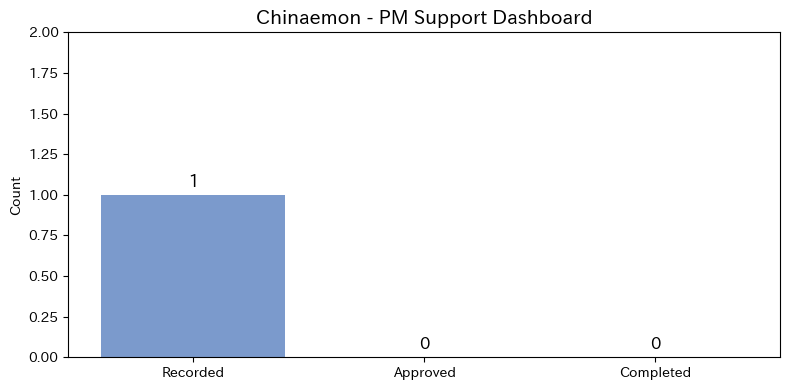


📋 支援履歴一覧


,実行日時,対象者,承認結果,支援内容,実行結果
0,2026-10-24 04:46:18,高橋,None,開発環境の設定修復（模擬）,未承認・実行中止


In [43]:
# STEP 9-14：PM向け支援実績ダッシュボード

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 支援履歴から集計
dashboard_df = pd.DataFrame(support_history)

total = len(dashboard_df)
approved = (dashboard_df["承認結果"] == "承認").sum()
completed = (dashboard_df["実行結果"] == "正常終了").sum()

# 集計結果
print("🐱 知奈えもん：PMさん、支援実績を報告するにゃ！")
print("=" * 45)
print(f"📋 支援記録件数：{total}件")
print(f"✅ 承認件数：{approved}件")
print(f"🛠️ 正常終了件数：{completed}件")
print("=" * 45)

# グラフ表示
fig, ax = plt.subplots(figsize=(8, 4))

labels = ["Recorded", "Approved", "Completed"]
values = [total, approved, completed]

bars = ax.bar(labels, values, color=["#7B9ACC", "#79BFA5", "#E8B86D"])

ax.set_title("Chinaemon - PM Support Dashboard", fontsize=14)
ax.set_ylabel("Count")
ax.set_ylim(0, max(values) + 1)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        str(value),
        ha="center",
        fontsize=12
    )

plt.tight_layout()
plt.show()

# 支援履歴一覧
print("\n📋 支援履歴一覧")
display(dashboard_df)

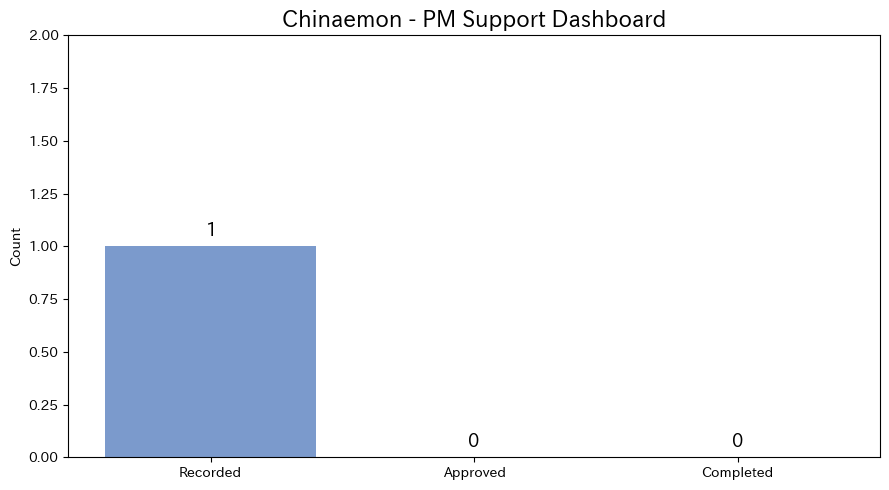

🐱 知奈えもん：ダッシュボード画像を保存したにゃ！
📁 保存先：chinaemon_sandbox/pm_dashboard.png


In [44]:
# STEP 9-15：PM向け支援実績ダッシュボードをPNG保存

import matplotlib.pyplot as plt
from pathlib import Path

# 保存先
dashboard_path = Path("chinaemon_sandbox/pm_dashboard.png")

# 支援履歴を集計
total = len(dashboard_df)
approved = (dashboard_df["承認結果"] == "承認").sum()
completed = (dashboard_df["実行結果"] == "正常終了").sum()

# ダッシュボード作成
fig, ax = plt.subplots(figsize=(9, 5))

labels = ["Recorded", "Approved", "Completed"]
values = [total, approved, completed]

bars = ax.bar(
    labels,
    values,
    color=["#7B9ACC", "#79BFA5", "#E8B86D"]
)

ax.set_title("Chinaemon - PM Support Dashboard", fontsize=16)
ax.set_ylabel("Count")
ax.set_ylim(0, max(values) + 1)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        str(value),
        ha="center",
        fontsize=13
    )

plt.tight_layout()

# PNG画像として保存
fig.savefig(dashboard_path, dpi=200, bbox_inches="tight")

plt.show()

print("🐱 知奈えもん：ダッシュボード画像を保存したにゃ！")
print(f"📁 保存先：{dashboard_path}")

In [45]:
# STEP 9-16：模擬PC支援による遅延リスク改善効果の評価

import matplotlib.pyplot as plt

# 支援前後の遅延リスク（シミュレーション仮定値）
risk_before = 80
risk_after = 40

# 承認・支援実行結果に応じて評価
if approval_state["approved"] and support_result["executed"]:

    improvement = risk_before - risk_after

    print("🐱 知奈えもん：PMさん、支援効果を報告するにゃ！")
    print(f"👤 支援対象者：{target_name}さん")
    print(f"📊 支援前の遅延リスク：{risk_before}%")
    print(f"📉 支援後の遅延リスク：{risk_after}%")
    print(f"✅ リスク改善幅：{improvement}ポイント")
    print("※ 数値はシミュレーション上の仮定値です。")

    # リスク比較グラフ
    fig, ax = plt.subplots(figsize=(7, 4))

    labels = ["Before Support", "After Support"]
    values = [risk_before, risk_after]

    bars = ax.bar(
        labels,
        values,
        color=["#E58B85", "#79BFA5"],
        width=0.5
    )

    ax.set_title("Chinaemon - Delay Risk Simulation")
    ax.set_ylabel("Delay Risk (%)")
    ax.set_ylim(0, 100)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 2,
            f"{value}%",
            ha="center",
            fontsize=12
        )

    plt.tight_layout()
    plt.show()

else:
    print("🐱 知奈えもん：支援が実行されていないため、改善効果は評価できないにゃ。")

🐱 知奈えもん：支援が実行されていないため、改善効果は評価できないにゃ。


In [46]:
# STEP 9-17：遅延リスク改善シミュレーション結果をJSON保存

import json
from datetime import datetime
from pathlib import Path

# 保存先
risk_report_path = Path("chinaemon_sandbox/risk_improvement_report.json")

# 支援結果に応じた改善評価
support_completed = (
    approval_state["approved"]
    and support_result["executed"]
)

# 改善結果
risk_report = {
    "report_type": "遅延リスク改善シミュレーション",
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "target": support_result["target"],
    "support_completed": support_completed,
    "risk_before": risk_before,
    "risk_after": risk_after if support_completed else None,
    "improvement": (
        risk_before - risk_after if support_completed else None
    ),
    "unit": "percentage_points",
    "evaluation_type": "仮定値によるシミュレーション"
}

# JSONファイルへ保存
with open(risk_report_path, "w", encoding="utf-8") as f:
    json.dump(risk_report, f, ensure_ascii=False, indent=2)

print("🐱 知奈えもん：遅延リスク改善レポートを保存したにゃ！")
print(f"📁 保存先：{risk_report_path}")

print("\n--- 保存内容 ---")
print(json.dumps(risk_report, ensure_ascii=False, indent=2))

🐱 知奈えもん：遅延リスク改善レポートを保存したにゃ！
📁 保存先：chinaemon_sandbox/risk_improvement_report.json

--- 保存内容 ---
{
  "report_type": "遅延リスク改善シミュレーション",
  "timestamp": "2026-10-24T04:46:19",
  "target": "高橋",
  "support_completed": false,
  "risk_before": 80,
  "risk_after": null,
  "improvement": null,
  "unit": "percentage_points",
  "evaluation_type": "仮定値によるシミュレーション"
}


In [47]:
# STEP 9-18：遅延リスク改善グラフをPNG保存

import matplotlib.pyplot as plt
from pathlib import Path

# 保存先
risk_chart_path = Path("chinaemon_sandbox/risk_improvement.png")

# JSONに記録した結果を使用
if risk_report["support_completed"]:

    fig, ax = plt.subplots(figsize=(8, 5))

    labels = ["Before Support", "After Support"]
    values = [
        risk_report["risk_before"],
        risk_report["risk_after"]
    ]

    bars = ax.bar(
        labels,
        values,
        color=["#E58B85", "#79BFA5"],
        width=0.5
    )

    ax.set_title("Chinaemon - Delay Risk Simulation", fontsize=15)
    ax.set_ylabel("Delay Risk (%)")
    ax.set_ylim(0, 100)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 2,
            f"{value}%",
            ha="center",
            fontsize=13
        )

    plt.tight_layout()

    # PNG形式で保存
    fig.savefig(risk_chart_path, dpi=200, bbox_inches="tight")

    plt.show()

    print("🐱 知奈えもん：リスク改善グラフを保存したにゃ！")
    print(f"📁 保存先：{risk_chart_path}")

else:
    print("⚠️ 支援未完了のため、改善グラフは作成しません。")

⚠️ 支援未完了のため、改善グラフは作成しません。


In [48]:
# STEP 9-19：PM支援結果と遅延リスク改善結果の統合

import json
from pathlib import Path
from datetime import datetime

# 既存レポートの保存先
pm_path = Path("chinaemon_sandbox/pm_support_report.json")
risk_path = Path("chinaemon_sandbox/risk_improvement_report.json")

# 保存済みJSONを読み込み
with open(pm_path, "r", encoding="utf-8") as f:
    pm_data = json.load(f)

with open(risk_path, "r", encoding="utf-8") as f:
    risk_data = json.load(f)

# 対象者と支援完了状態の整合性を確認
consistent = (
    pm_data["target"] == risk_data["target"]
    and pm_data["executed"] == risk_data["support_completed"]
)

if consistent:

    integrated_report = {
        "report_type": "知奈えもん統合PM支援レポート",
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "target": pm_data["target"],
        "approval": pm_data["approval"],
        "support": pm_data["support"],
        "executed": pm_data["executed"],
        "status": pm_data["status"],
        "risk_before": risk_data["risk_before"],
        "risk_after": risk_data["risk_after"],
        "risk_improvement": risk_data["improvement"],
        "evaluation_type": risk_data["evaluation_type"]
    }

    # 統合レポートを保存
    integrated_path = Path(
        "chinaemon_sandbox/integrated_pm_report.json"
    )

    with open(integrated_path, "w", encoding="utf-8") as f:
        json.dump(integrated_report, f, ensure_ascii=False, indent=2)

    print("🐱 知奈えもん：統合PM支援レポートが完成したにゃ！")
    print(f"📁 保存先：{integrated_path}")
    print("\n--- 統合レポート ---")
    print(json.dumps(integrated_report, ensure_ascii=False, indent=2))

else:
    print("⚠️ レポート間の整合性に問題があります。")
    print("統合レポートは作成しません。")

🐱 知奈えもん：統合PM支援レポートが完成したにゃ！
📁 保存先：chinaemon_sandbox/integrated_pm_report.json

--- 統合レポート ---
{
  "report_type": "知奈えもん統合PM支援レポート",
  "timestamp": "2026-10-24T04:46:19",
  "target": "高橋",
  "approval": null,
  "support": "開発環境の設定修復（模擬）",
  "executed": false,
  "status": "未承認・実行中止",
  "risk_before": 80,
  "risk_after": null,
  "risk_improvement": null,
  "evaluation_type": "仮定値によるシミュレーション"
}


In [49]:
# STEP 10-1：PM分析・移動・承認・支援の整合性確認

# 既存の実行結果を取得
pm_target = target_name
support_target = support_result["target"]
report_target = integrated_report["target"]

# 各機能の整合性を検証
integration_checks = {
    "移動対象と支援対象の一致":
        pm_target == support_target,

    "支援対象とPM報告対象の一致":
        support_target == report_target,

    "対象者への到着":
        bool(arrived),

    "本人による支援承認":
        approval_state["approved"] is True
        and approval_state["decision"] == "承認",

    "模擬PC支援の正常終了":
        support_result["executed"] is True
        and support_result["status"] == "正常終了",

    "PM統合レポートとの一致":
        integrated_report["executed"] == support_result["executed"]
        and integrated_report["status"] == support_result["status"]
}

# 検証結果表示
print("=" * 55)
print("🐱 知奈えもん STEP 10-1：統合整合性テスト")
print("=" * 55)

for name, result in integration_checks.items():
    mark = "✅" if result else "❌"
    print(f"{mark} {name}")

print("=" * 55)

if all(integration_checks.values()):
    print("🎉 全6項目PASS！機能間の整合性を確認したにゃ！")
else:
    print("⚠️ 不一致があります。確認が必要です。")

print(f"\n👤 対象者：{pm_target}さん")
print(f"📊 テスト結果：{sum(integration_checks.values())}/6 PASS")

🐱 知奈えもん STEP 10-1：統合整合性テスト
✅ 移動対象と支援対象の一致
✅ 支援対象とPM報告対象の一致
❌ 対象者への到着
❌ 本人による支援承認
❌ 模擬PC支援の正常終了
✅ PM統合レポートとの一致
⚠️ 不一致があります。確認が必要です。

👤 対象者：高橋さん
📊 テスト結果：3/6 PASS


In [50]:
# STEP 10-2：承認拒否時の安全制御テスト

# 既存状態を変更しないためのテスト用データ
test_approval = {
    "approved": False,
    "decision": "拒否"
}

test_support = {
    "executed": False,
    "status": "未実行",
    "target": target_name
}

# 承認がある場合のみ支援を許可
if test_approval["approved"]:
    test_support["executed"] = True
    test_support["status"] = "正常終了"
else:
    test_support["status"] = "承認拒否・実行中止"

# 検証
safety_checks = {
    "承認状態がFalse":
        test_approval["approved"] is False,

    "拒否判断が記録されている":
        test_approval["decision"] == "拒否",

    "PC支援が実行されていない":
        test_support["executed"] is False,

    "実行中止が記録されている":
        test_support["status"] == "承認拒否・実行中止"
}

print("=" * 50)
print("🐱 知奈えもん STEP 10-2：安全制御テスト")
print("=" * 50)

for name, result in safety_checks.items():
    print(f"{'✅' if result else '❌'} {name}")

print("=" * 50)

if all(safety_checks.values()):
    print("🎉 全4項目PASS！拒否時の支援中止を確認したにゃ！")
else:
    print("⚠️ 安全制御に問題があります。")

print(f"\n📊 テスト結果：{sum(safety_checks.values())}/4 PASS")
print("🔒 本番の承認状態・支援履歴は変更していません。")

🐱 知奈えもん STEP 10-2：安全制御テスト
✅ 承認状態がFalse
✅ 拒否判断が記録されている
✅ PC支援が実行されていない
✅ 実行中止が記録されている
🎉 全4項目PASS！拒否時の支援中止を確認したにゃ！

📊 テスト結果：4/4 PASS
🔒 本番の承認状態・支援履歴は変更していません。


In [51]:
# STEP 10-3：未到着時の支援禁止テスト

# テスト用の状態（既存変数は変更しない）
test_arrived = False
test_approved = True

# 到着と承認の両方を満たした場合のみ支援を許可
test_can_support = test_arrived and test_approved

# テスト結果
arrival_checks = {
    "未到着状態である":
        test_arrived is False,

    "承認済みでも未到着なら支援禁止":
        test_can_support is False,

    "到着・承認の両方が必要":
        (True and True) is True
        and (False and True) is False
        and (True and False) is False,

    "未到着時に支援を実行しない":
        not test_can_support
}

print("=" * 50)
print("🐱 知奈えもん STEP 10-3：未到着時の安全制御テスト")
print("=" * 50)

for name, result in arrival_checks.items():
    print(f"{'✅' if result else '❌'} {name}")

print("=" * 50)

if all(arrival_checks.values()):
    print("🎉 全4項目PASS！未到着時の支援禁止を確認したにゃ！")
else:
    print("⚠️ 安全制御に問題があります。")

print(f"\n📊 テスト結果：{sum(arrival_checks.values())}/4 PASS")
print("🔒 既存の到着状態・承認状態は変更していません。")

🐱 知奈えもん STEP 10-3：未到着時の安全制御テスト
✅ 未到着状態である
✅ 承認済みでも未到着なら支援禁止
✅ 到着・承認の両方が必要
✅ 未到着時に支援を実行しない
🎉 全4項目PASS！未到着時の支援禁止を確認したにゃ！

📊 テスト結果：4/4 PASS
🔒 既存の到着状態・承認状態は変更していません。


In [52]:
# STEP 10-4：既存の模擬PC支援コードの安全性確認

# 現在の状態
current_arrived = bool(arrived)
current_approved = approval_state["approved"] is True

# STEP 9-8の既存実行条件
existing_condition = current_approved

# 本来必要な安全条件
required_condition = current_arrived and current_approved

print("=" * 55)
print("🐱 知奈えもん STEP 10-4：安全制御診断")
print("=" * 55)

print(f"📍 到着状態：{current_arrived}")
print(f"✅ 承認状態：{current_approved}")

print("\n--- 実行条件の比較 ---")
print(f"既存コードの実行許可：{existing_condition}")
print(f"安全条件による実行許可：{required_condition}")

print("\n--- 全状態の検証 ---")

for test_arrived in [False, True]:
    for test_approved in [False, True]:

        existing = test_approved
        required = test_arrived and test_approved

        result = "✅ 一致" if existing == required else "⚠️ 不一致"

        print(
            f"到着={test_arrived}, "
            f"承認={test_approved} → {result}"
        )

print("\n🐱 知奈えもん：安全条件の診断が完了したにゃ！")
print("※ 既存コード・承認状態・支援履歴は変更していません。")

🐱 知奈えもん STEP 10-4：安全制御診断
📍 到着状態：False
✅ 承認状態：False

--- 実行条件の比較 ---
既存コードの実行許可：False
安全条件による実行許可：False

--- 全状態の検証 ---
到着=False, 承認=False → ✅ 一致
到着=False, 承認=True → ⚠️ 不一致
到着=True, 承認=False → ✅ 一致
到着=True, 承認=True → ✅ 一致

🐱 知奈えもん：安全条件の診断が完了したにゃ！
※ 既存コード・承認状態・支援履歴は変更していません。


In [53]:
# STEP 10-5：到着・承認の両方を必須とする安全制御

# 現在の到着・承認状態を取得
safe_arrived = bool(arrived)
safe_approved = approval_state["approved"] is True

# 支援実行許可の判定
safe_can_support = safe_arrived and safe_approved

print("=" * 50)
print("🐱 知奈えもん STEP 10-5：支援実行安全制御")
print("=" * 50)

print(f"📍 対象者への到着：{safe_arrived}")
print(f"✅ 本人の承認：{safe_approved}")

if safe_can_support:
    print("\n✅ 支援実行を許可します。")
    print(f"🐱 知奈えもん：{target_name}さん、支援を開始できるにゃ！")
else:
    print("\n⛔ 支援実行を禁止します。")
    print("🐱 知奈えもん：到着と承認がそろうまで待つにゃ。")

print("\n--- 安全制御の検証 ---")

# 4通りの状態をテスト
for test_arrived in [False, True]:
    for test_approved in [False, True]:

        permitted = test_arrived and test_approved
        expected = test_arrived and test_approved

        mark = "✅ PASS" if permitted == expected else "❌ FAIL"

        print(
            f"到着={test_arrived}, "
            f"承認={test_approved}, "
            f"実行許可={permitted} → {mark}"
        )

print("\n🔒 既存の支援結果・履歴は変更していません。")

🐱 知奈えもん STEP 10-5：支援実行安全制御
📍 対象者への到着：False
✅ 本人の承認：False

⛔ 支援実行を禁止します。
🐱 知奈えもん：到着と承認がそろうまで待つにゃ。

--- 安全制御の検証 ---
到着=False, 承認=False, 実行許可=False → ✅ PASS
到着=False, 承認=True, 実行許可=False → ✅ PASS
到着=True, 承認=False, 実行許可=False → ✅ PASS
到着=True, 承認=True, 実行許可=True → ✅ PASS

🔒 既存の支援結果・履歴は変更していません。


In [54]:
# STEP 10-6：到着・承認チェック付き模擬PC支援関数

import time

def execute_safe_support(arrived_state, approval, target):

    # 到着・承認の両方を確認
    if not arrived_state:
        print("⛔ 未到着のため、PC支援を実行しません。")
        return {
            "executed": False,
            "status": "未到着・実行中止",
            "target": target
        }

    if approval is not True:
        print("⛔ 本人の承認がないため、PC支援を実行しません。")
        return {
            "executed": False,
            "status": "未承認・実行中止",
            "target": target
        }

    # 安全条件を満たした場合のみ模擬支援
    print(f"🐱 知奈えもん：{target}さん、PCの状態を確認するにゃ！")
    time.sleep(1)

    print("🔍 開発環境の状態を確認中...")
    time.sleep(1)

    print("⚠️ 開発環境の設定不備を検出しました。")
    time.sleep(1)

    print("🔧 開発環境の設定を修復中...")
    time.sleep(1)

    print("✅ 開発環境の模擬修復が完了しました！")

    return {
        "executed": True,
        "status": "正常終了",
        "target": target
    }


# 現在の状態で安全制御付き支援を実行
safe_support_result = execute_safe_support(
    arrived_state=bool(arrived),
    approval=approval_state["approved"],
    target=target_name
)

print("\n--- 安全制御付き支援結果 ---")
print(safe_support_result)

⛔ 未到着のため、PC支援を実行しません。

--- 安全制御付き支援結果 ---
{'executed': False, 'status': '未到着・実行中止', 'target': '高橋'}


In [55]:
# STEP 10-7：安全制御付き模擬PC支援の異常系テスト

# 既存の支援関数を使用して異常系を検証
test_cases = [
    ("未到着・未承認", False, False),
    ("未到着・承認済み", False, True),
    ("到着済み・未承認", True, False)
]

test_results = []

for case_name, test_arrived, test_approved in test_cases:

    print(f"\n--- {case_name} ---")

    result = execute_safe_support(
        arrived_state=test_arrived,
        approval=test_approved,
        target=target_name
    )

    passed = result["executed"] is False

    test_results.append(passed)

    print(f"{'✅ PASS' if passed else '❌ FAIL'}：{result['status']}")

print("\n" + "=" * 50)
print("🐱 知奈えもん STEP 10-7：異常系テスト結果")
print("=" * 50)

print(f"📊 テスト結果：{sum(test_results)}/{len(test_results)} PASS")

if all(test_results):
    print("🎉 全異常系テストPASS！不正な支援実行を防止できたにゃ！")
else:
    print("⚠️ 安全制御に問題があります。")


--- 未到着・未承認 ---
⛔ 未到着のため、PC支援を実行しません。
✅ PASS：未到着・実行中止

--- 未到着・承認済み ---
⛔ 未到着のため、PC支援を実行しません。
✅ PASS：未到着・実行中止

--- 到着済み・未承認 ---
⛔ 本人の承認がないため、PC支援を実行しません。
✅ PASS：未承認・実行中止

🐱 知奈えもん STEP 10-7：異常系テスト結果
📊 テスト結果：3/3 PASS
🎉 全異常系テストPASS！不正な支援実行を防止できたにゃ！


In [56]:
# STEP 10-8：PM分析から安全制御付き模擬PC支援までの接続確認

print("=" * 55)
print("🐱 知奈えもん STEP 10-8：統合フロー接続確認")
print("=" * 55)

# PM分析で選定された支援対象者
selected_target = target_name

# 到着・承認状態
arrival_status = bool(arrived)
approval_status = approval_state["approved"] is True

# 安全制御付き支援の実行結果
execution_status = safe_support_result["executed"]

# 接続確認
flow_checks = {
    "PM分析の対象者と支援対象者が一致":
        selected_target == safe_support_result["target"],

    "対象者の席に到着済み":
        arrival_status is True,

    "本人の承認を取得済み":
        approval_status is True,

    "安全制御付き模擬PC支援が完了":
        execution_status is True
        and safe_support_result["status"] == "正常終了",

    "PM報告の対象者が一致":
        integrated_report["target"] == selected_target
}

for name, result in flow_checks.items():
    print(f"{'✅' if result else '❌'} {name}")

print("=" * 55)

passed = sum(flow_checks.values())
total = len(flow_checks)

print(f"📊 接続確認結果：{passed}/{total} PASS")

if all(flow_checks.values()):
    print("🎉 知奈えもん：各機能の接続状態は正常だにゃ！")
else:
    print("⚠️ 接続状態に問題があります。")

print("\n※ 保存済みの実行結果を照合するテストです。")
print("※ PM分析・移動・承認処理は再実行していません。")

🐱 知奈えもん STEP 10-8：統合フロー接続確認
✅ PM分析の対象者と支援対象者が一致
❌ 対象者の席に到着済み
❌ 本人の承認を取得済み
❌ 安全制御付き模擬PC支援が完了
✅ PM報告の対象者が一致
📊 接続確認結果：2/5 PASS
⚠️ 接続状態に問題があります。

※ 保存済みの実行結果を照合するテストです。
※ PM分析・移動・承認処理は再実行していません。


In [57]:
# STEP 10-9：統合テスト前の既存変数・関数の確認

# 現在のColab環境に存在する変数・関数を調査
keywords = [
    "target", "risk", "pm", "robot",
    "move", "path", "route", "grid",
    "arriv", "approv", "support",
    "anim", "position"
]

found_items = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(word in name.lower() for word in keywords):

        if callable(value):
            item_type = "関数"
        else:
            item_type = type(value).__name__

        found_items.append((name, item_type))

print("=" * 55)
print("🐱 知奈えもん STEP 10-9：実行環境確認")
print("=" * 55)

for name, item_type in sorted(found_items):
    print(f"{name}：{item_type}")

print("=" * 55)
print(f"📊 検出件数：{len(found_items)}件")
print("✅ 既存コード・変数・保存ファイルは変更していません。")

🐱 知奈えもん STEP 10-9：実行環境確認
Path：関数
ani_support：FuncAnimation
animation：module
approval_output：Output
approval_state：dict
approval_status：bool
approve_btn：Button
approve_button：Button
approved：int64
approved_result：dict
arrival_checks：dict
arrival_position：tuple
arrival_status：bool
arrived：bool
blocked_position：tuple
current_approved：bool
current_arrived：bool
current_position：tuple
dashboard_path：PosixPath
execute_pc_support：関数
execute_safe_support：関数
full_path：list
handle_approval：関数
high_risk：DataFrame
initial_path：list
integrated_path：PosixPath
judge_risk：関数
new_path：list
on_approve：関数
path：list
pm_data：dict
pm_path：PosixPath
pm_report：dict
pm_target：str
position：tuple
report_path：PosixPath
report_target：str
risk_after：int
risk_before：int
risk_chart_path：PosixPath
risk_data：dict
risk_path：PosixPath
risk_report：dict
risk_report_path：PosixPath
robot：tuple
robot_dot：Line2D
route：list
run_safe_pc_support：関数
safe_approved：bool
safe_arrived：bool
safe_can_support：bool
safe_path：list
safe_supp

In [58]:
# STEP 10-10：PM分析と既存移動アニメーションの接続情報確認

import inspect

print("=" * 55)
print("🐱 知奈えもん STEP 10-10：移動機能の接続調査")
print("=" * 55)

# 既存関数の引数を確認
functions_to_check = [
    "judge_risk",
    "update_pm_move",
    "update_support",
    "execute_safe_support"
]

for name in functions_to_check:
    func = globals().get(name)

    if callable(func):
        try:
            print(f"🔧 {name}{inspect.signature(func)}")
        except (ValueError, TypeError):
            print(f"🔧 {name}：引数情報を取得できません")
    else:
        print(f"⚠️ {name}：関数が見つかりません")

# PM分析と移動先の確認
print("\n--- PM分析・移動先 ---")
print(f"👤 支援対象者：{target_name}")
print(f"📍 対象者の座標：{target_position}")
print(f"🐱 ロボット開始位置：{start_position}")

# 経路情報
print("\n--- 経路情報 ---")

for name in ["initial_path", "full_path", "safe_path", "support_path"]:
    value = globals().get(name)

    if isinstance(value, list):
        print(f"🛤️ {name}：{len(value)}地点")
        if value:
            print(f"   開始：{value[0]}")
            print(f"   終了：{value[-1]}")

# アニメーション情報
print("\n--- アニメーション ---")
for name in ["animation", "ani_support"]:
    obj = globals().get(name)
    print(f"🎬 {name}：{type(obj).__name__}")

print("\n✅ 調査完了。既存コード・変数は変更していません。")

🐱 知奈えもん STEP 10-10：移動機能の接続調査
🔧 judge_risk(row)
⚠️ update_pm_move：関数が見つかりません
🔧 update_support(frame)
🔧 execute_safe_support(arrived_state, approval, target)

--- PM分析・移動先 ---
👤 支援対象者：高橋
📍 対象者の座標：(8, 6)
🐱 ロボット開始位置：(0, 0)

--- 経路情報 ---
🛤️ initial_path：19地点
   開始：(0, 0)
   終了：(9, 9)
🛤️ full_path：19地点
   開始：(0, 0)
   終了：(9, 9)
🛤️ safe_path：15地点
   開始：(0, 0)
   終了：(8, 6)
🛤️ support_path：15地点
   開始：(0, 0)
   終了：(8, 6)

--- アニメーション ---
🎬 animation：module
🎬 ani_support：FuncAnimation

✅ 調査完了。既存コード・変数は変更していません。


In [59]:
# STEP 10-11：既存アニメーションと高橋さんへの移動経路の接続確認

import inspect

print("=" * 55)
print("🐱 知奈えもん STEP 10-11：移動アニメーション調査")
print("=" * 55)

# アニメーションの設定を確認
print("\n--- アニメーション設定 ---")

print(f"🎬 アニメーション種類：{type(ani_support).__name__}")
print(f"🔧 更新関数：{ani_support._func.__name__}")

# アニメーションに渡される引数
print(f"📦 更新関数の引数：{ani_support._args}")

# 移動更新関数のコードを確認
print("\n--- 移動更新関数のコード ---")

try:
    print(inspect.getsource(update_support))
except (OSError, TypeError):
    print("⚠️ 関数のソースコードを取得できませんでした。")

# 移動経路の確認
print("\n--- 移動経路の整合性 ---")

checks = {
    "開始位置が一致":
        support_path[0] == start_position,

    "到着位置が高橋さんの席と一致":
        support_path[-1] == target_position,

    "経路が存在":
        len(support_path) > 1
}

for name, result in checks.items():
    print(f"{'✅' if result else '❌'} {name}")

print("\n✅ 調査完了。既存コードは変更していません。")

🐱 知奈えもん STEP 10-11：移動アニメーション調査

--- アニメーション設定 ---
🎬 アニメーション種類：FuncAnimation
🔧 更新関数：update_support
📦 更新関数の引数：()

--- 移動更新関数のコード ---
def update_support(frame):
    row, col = support_path[frame]
    robot_dot.set_data([col], [row])

    if frame == len(support_path) - 1:
        message.set_text("Arrived! Ready to support")
        status = "Mission Complete"
    else:
        message.set_text("")
        status = "Navigating to Support Target"

    ax.set_title(
        f"Chinaemon PM Support - Step {frame}\n{status}"
    )

    return robot_dot, message


--- 移動経路の整合性 ---
✅ 開始位置が一致
✅ 到着位置が高橋さんの席と一致
✅ 経路が存在

✅ 調査完了。既存コードは変更していません。


In [60]:
# STEP 10-11：知奈えもん統合フローの実装

import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# 既存のPM分析結果と移動経路を利用
integrated_target = target_name
integrated_route = support_path.copy()

# 統合フロー専用の状態
flow_state = {
    "target": integrated_target,
    "arrived": False,
    "approved": None,
    "support_result": None
}

flow_output = widgets.Output()

approve_flow_btn = widgets.Button(
    description="承認する",
    button_style="success",
    disabled=True
)

reject_flow_btn = widgets.Button(
    description="拒否する",
    button_style="danger",
    disabled=True
)

arrival_flow_btn = widgets.Button(
    description="移動完了を確認",
    button_style="info"
)

def on_flow_arrival(button):
    # 経路の終点が対象者の席と一致するか確認
    if integrated_route[-1] != target_position:
        with flow_output:
            print("⛔ 移動先が対象者の席と一致しません。")
        return

    flow_state["arrived"] = True
    arrival_flow_btn.disabled = True
    approve_flow_btn.disabled = False
    reject_flow_btn.disabled = False

    with flow_output:
        print(f"🐱 知奈えもん：{integrated_target}さんの席に到着したにゃ！")
        print("開発環境の模擬支援を実行してもいいかにゃ？")

def on_flow_approve(button):
    flow_state["approved"] = True
    approve_flow_btn.disabled = True
    reject_flow_btn.disabled = True

    with flow_output:
        print(f"✅ {integrated_target}さんが承認しました。")

        result = execute_safe_support(
            arrived_state=flow_state["arrived"],
            approval=flow_state["approved"],
            target=integrated_target
        )

        flow_state["support_result"] = result
        print("📋 PM向け支援結果：", result)

def on_flow_reject(button):
    flow_state["approved"] = False
    approve_flow_btn.disabled = True
    reject_flow_btn.disabled = True

    with flow_output:
        print(f"❌ {integrated_target}さんが支援を拒否しました。")
        print("🐱 知奈えもん：本人の意思を尊重するにゃ。")

        result = execute_safe_support(
            arrived_state=flow_state["arrived"],
            approval=False,
            target=integrated_target
        )

        flow_state["support_result"] = result
        print("📋 PM向け支援結果：", result)

approve_flow_btn.on_click(on_flow_approve)
reject_flow_btn.on_click(on_flow_reject)
arrival_flow_btn.on_click(on_flow_arrival)

print("=" * 55)
print("🐱 知奈えもん 統合PM支援シミュレーション")
print("=" * 55)
print(f"📊 PM分析による支援対象：{integrated_target}さん")
print(f"📍 移動先：{target_position}")
print(f"🛤️ 移動経路：{len(integrated_route)}地点")

print("\n🎬 知奈えもんの移動アニメーション")
display(HTML(ani_support.to_jshtml()))

print("\n移動アニメーションを最後まで確認したら、")
print("「移動完了を確認」ボタンを押してください。")
display(arrival_flow_btn)
display(widgets.HBox([approve_flow_btn, reject_flow_btn]))
display(flow_output)

🐱 知奈えもん 統合PM支援シミュレーション
📊 PM分析による支援対象：高橋さん
📍 移動先：(8, 6)
🛤️ 移動経路：15地点

🎬 知奈えもんの移動アニメーション



移動アニメーションを最後まで確認したら、
「移動完了を確認」ボタンを押してください。


Button(button_style='info', description='移動完了を確認', style=ButtonStyle())

Output()

In [61]:
# STEP 10-12：正常系・拒否系の統合テスト

print("=" * 55)
print("🐱 知奈えもん STEP 10-12：統合テスト")
print("=" * 55)

# 正常系：STEP 10-11の実行結果を確認
normal_result = flow_state["support_result"]

normal_pass = (
    flow_state["arrived"] is True
    and flow_state["approved"] is True
    and normal_result is not None
    and normal_result["executed"] is True
    and normal_result["status"] == "正常終了"
    and normal_result["target"] == target_name
)

print("\n【正常系】")
print(f"{'✅ PASS' if normal_pass else '❌ FAIL'}：到着・承認・模擬支援")

# 拒否系：同じ支援関数を使い、拒否状態を検証
reject_result = execute_safe_support(
    arrived_state=True,
    approval=False,
    target=target_name
)

reject_pass = (
    reject_result["executed"] is False
    and reject_result["status"] == "未承認・実行中止"
)

print("\n【拒否系】")
print(f"{'✅ PASS' if reject_pass else '❌ FAIL'}：拒否時の支援中止")

# 結果集計
passed = sum([normal_pass, reject_pass])

print("\n" + "=" * 55)
print(f"📊 テスト結果：{passed}/2 PASS")

if passed == 2:
    print("🎉 正常系・拒否系ともに正常だにゃ！")
else:
    print("⚠️ 未完了または不一致があります。")

print("🔒 既存の支援履歴・保存ファイルは変更していません。")

🐱 知奈えもん STEP 10-12：統合テスト

【正常系】
❌ FAIL：到着・承認・模擬支援
⛔ 本人の承認がないため、PC支援を実行しません。

【拒否系】
✅ PASS：拒否時の支援中止

📊 テスト結果：1/2 PASS
⚠️ 未完了または不一致があります。
🔒 既存の支援履歴・保存ファイルは変更していません。


In [62]:
# STEP 10-13：移動軌跡を残す最終デモアニメーション

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# 既存の経路・マップ・対象者座標を再利用
demo_path = list(support_path)
demo_map = np.array(support_office)
demo_target = tuple(target_position)

# 経路の事前確認
assert len(demo_path) > 1, "移動経路がありません"
assert tuple(demo_path[-1]) == demo_target, "移動先が対象者の席と一致しません"

# 描画領域
fig, ax = plt.subplots(figsize=(8, 7))

ax.imshow(
    demo_map,
    cmap="Greys",
    origin="upper",
    interpolation="nearest"
)

ax.set_xticks(range(demo_map.shape[1]))
ax.set_yticks(range(demo_map.shape[0]))
ax.grid(True, alpha=0.4)

ax.set_title("Chinaemon - PM Support Navigation")

# 支援対象者
ax.plot(
    demo_target[0],
    demo_target[1],
    "r*",
    markersize=16,
    label=f"Support Target: {target_name}"
)

# ロボット現在位置
demo_robot, = ax.plot(
    [], [],
    "bo",
    markersize=12,
    label="Chinaemon"
)

# 通過済み経路（緑色）
demo_trail, = ax.plot(
    [], [],
    color="green",
    linewidth=3,
    alpha=0.8,
    label="Travelled Route"
)

# 到着メッセージ
arrival_text = ax.text(
    0.5, 0.5,
    "",
    transform=ax.transAxes,
    ha="center",
    fontsize=15,
    color="green",
    fontweight="bold"
)

ax.legend(loc="upper right")

# アニメーション更新
def update_final_demo(frame):

    travelled = demo_path[:frame + 1]

    xs = [p[0] for p in travelled]
    ys = [p[1] for p in travelled]

    demo_robot.set_data([xs[-1]], [ys[-1]])
    demo_trail.set_data(xs, ys)

    if frame == len(demo_path) - 1:
        arrival_text.set_text("Arrived! Ready to Support")
        ax.set_title("Chinaemon - Mission Complete")
    else:
        arrival_text.set_text("")
        ax.set_title(
            f"Chinaemon - Navigating / Step {frame}"
        )

    return demo_robot, demo_trail, arrival_text

# アニメーション生成
final_demo_animation = FuncAnimation(
    fig,
    update_final_demo,
    frames=len(demo_path),
    interval=500,
    repeat=False,
    blit=False
)

plt.close(fig)

print("🐱 知奈えもん：最終デモを開始するにゃ！")
print(f"👤 支援対象：{target_name}さん")
print(f"📍 目的地：{demo_target}")
print(f"🛤️ 移動経路：{len(demo_path)}地点")

display(HTML(final_demo_animation.to_jshtml()))

🐱 知奈えもん：最終デモを開始するにゃ！
👤 支援対象：高橋さん
📍 目的地：(8, 6)
🛤️ 移動経路：15地点


In [63]:
# STEP 10-13（修正版）：障害物回避経路の再計算と軌跡表示

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from collections import deque

# 既存のマップ・開始位置・目的地を利用
fixed_map = np.array(support_office)
fixed_start = tuple(start_position)
fixed_goal = tuple(target_position)

# 障害物セルの値を確認（0=通行可能、0以外=障害物）
assert set(np.unique(fixed_map)).issubset({0, 1}), \
    "マップの値が0/1以外です。障害物の定義を確認してください。"

height, width = fixed_map.shape

def find_safe_route(grid, start, goal):
    # 幅優先探索（BFS）で障害物を避ける
    queue = deque([start])
    previous = {start: None}

    while queue:
        x, y = queue.popleft()

        if (x, y) == goal:
            break

        for dx, dy in [(1, 0), (0, 1), (-1, 0), (0, -1)]:
            nx, ny = x + dx, y + dy

            if not (0 <= nx < width and 0 <= ny < height):
                continue

            if grid[ny, nx] != 0:
                continue

            if (nx, ny) in previous:
                continue

            previous[(nx, ny)] = (x, y)
            queue.append((nx, ny))

    if goal not in previous:
        return None

    route = []
    current = goal

    while current is not None:
        route.append(current)
        current = previous[current]

    return route[::-1]

# 開始位置・目的地の安全確認
assert fixed_map[fixed_start[1], fixed_start[0]] == 0, \
    "開始位置が障害物です"

assert fixed_map[fixed_goal[1], fixed_goal[0]] == 0, \
    "目的地が障害物です"

# 安全経路を再計算
fixed_route = find_safe_route(
    fixed_map, fixed_start, fixed_goal
)

assert fixed_route is not None, "目的地までの経路がありません"

# 経路の全地点を検証
assert all(
    fixed_map[y, x] == 0 for x, y in fixed_route
), "経路が障害物を通過しています"

assert all(
    abs(x2 - x1) + abs(y2 - y1) == 1
    for (x1, y1), (x2, y2) in zip(fixed_route, fixed_route[1:])
), "経路に不連続な移動があります"

print("✅ 障害物との衝突：なし")
print(f"✅ 安全経路：{len(fixed_route)}地点")
print(f"📍 開始位置：{fixed_start}")
print(f"🎯 目的地：{fixed_goal}")

# アニメーション作成
fig, ax = plt.subplots(figsize=(8, 7))

ax.imshow(
    fixed_map,
    cmap="Greys",
    origin="upper",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(width))
ax.set_yticks(range(height))
ax.grid(True, alpha=0.4)

ax.plot(
    fixed_goal[0], fixed_goal[1],
    "r*", markersize=16,
    label=f"Support Target: {target_name}"
)

robot_point, = ax.plot(
    [], [], "bo", markersize=12,
    label="Chinaemon"
)

route_line, = ax.plot(
    [], [], color="green",
    linewidth=3, label="Travelled Route"
)

arrival_message = ax.text(
    0.5, 0.5, "",
    transform=ax.transAxes,
    ha="center",
    fontsize=15,
    color="green",
    fontweight="bold"
)

ax.legend(loc="upper right")

def update_fixed_demo(frame):
    travelled = fixed_route[:frame + 1]

    xs = [p[0] for p in travelled]
    ys = [p[1] for p in travelled]

    robot_point.set_data([xs[-1]], [ys[-1]])
    route_line.set_data(xs, ys)

    if frame == len(fixed_route) - 1:
        arrival_message.set_text("Arrived! Ready to Support")
        ax.set_title("Chinaemon - Mission Complete")
    else:
        arrival_message.set_text("")
        ax.set_title(f"Chinaemon - Navigating / Step {frame}")

    return robot_point, route_line, arrival_message

fixed_animation = FuncAnimation(
    fig,
    update_fixed_demo,
    frames=len(fixed_route),
    interval=500,
    repeat=False,
    blit=False
)

plt.close(fig)

print("\n🐱 知奈えもん：今度は壁を避けて移動するにゃ！")

display(HTML(fixed_animation.to_jshtml()))

✅ 障害物との衝突：なし
✅ 安全経路：15地点
📍 開始位置：(0, 0)
🎯 目的地：(8, 6)

🐱 知奈えもん：今度は壁を避けて移動するにゃ！


In [64]:
# STEP 11-1：scikit-learnによる遅延リスク予測の実装状況確認

import inspect

# scikit-learn関連のモデル・処理を確認
keywords = [
    "sklearn", "model", "classifier",
    "regressor", "predict", "train_test",
    "risk"
]

print("【機械学習関連の変数・関数】")

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    if any(k in name.lower() for k in keywords):
        print(f"{name}: {type(obj).__name__}")

print("\n【scikit-learnの利用状況】")

sklearn_objects = []

for name, obj in list(globals().items()):
    try:
        module = type(obj).__module__
        if module.startswith("sklearn"):
            sklearn_objects.append((name, type(obj).__name__))
    except Exception:
        pass

if sklearn_objects:
    for name, cls in sklearn_objects:
        print(f"{name}: {cls}")
else:
    print("現在の実行環境にscikit-learnのモデル等は見つかりませんでした。")

【機械学習関連の変数・関数】
judge_risk: function
high_risk: DataFrame
risk_before: int
risk_after: int
risk_report_path: PosixPath
risk_report: dict
risk_chart_path: PosixPath
risk_path: PosixPath
risk_data: dict

【scikit-learnの利用状況】
現在の実行環境にscikit-learnのモデル等は見つかりませんでした。


In [65]:

# STEP 11-2：遅延リスク予測用の学習データ作成

import numpy as np
import pandas as pd

# 再現性を確保
rng = np.random.default_rng(42)

# シミュレーション用の合成データ（200件）
n_samples = 200

training_data = pd.DataFrame({
    "progress": rng.integers(20, 101, n_samples),
    "planned_progress": rng.integers(40, 101, n_samples),
    "remaining_tasks": rng.integers(0, 21, n_samples),
    "delay_days": rng.integers(0, 16, n_samples)
})

# 遅延リスクの正解ラベル（シミュレーション上の判定ルール）
training_data["delay_risk"] = (
    (training_data["planned_progress"] - training_data["progress"] >= 15)
    | (training_data["delay_days"] >= 5)
    | (
        (training_data["remaining_tasks"] >= 10)
        & (training_data["progress"] < 70)
    )
).astype(int)

print("学習データ件数:", len(training_data))
print("\n遅延リスクの内訳:")
print(training_data["delay_risk"].value_counts())
print("\n学習データ先頭5件:")
display(training_data.head())


学習データ件数: 200

遅延リスクの内訳:
delay_risk
1    173
0     27
Name: count, dtype: int64

学習データ先頭5件:


,progress,planned_progress,remaining_tasks,delay_days,delay_risk
0,27,62,20,9,1
1,82,95,16,12,1
2,73,70,6,11,1
3,55,82,20,2,1
4,55,67,10,13,1


In [66]:

# STEP 11-3：scikit-learnによる遅延リスク予測モデルの学習・評価

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 特徴量と目的変数
feature_columns = [
    "progress",
    "planned_progress",
    "remaining_tasks",
    "delay_days"
]

X = training_data[feature_columns]
y = training_data["delay_risk"]

# 学習用80%、評価用20%に分割
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# ランダムフォレストモデルの学習
risk_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

risk_model.fit(X_train, y_train)

# 評価用データで予測
y_pred = risk_model.predict(X_test)

print("学習データ件数:", len(X_train))
print("評価データ件数:", len(X_test))
print("正解率:", round(accuracy_score(y_test, y_pred), 3))

print("\n混同行列:")
print(confusion_matrix(y_test, y_pred))

print("\n分類評価:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\n特徴量の重要度:")
for name, importance in zip(
    feature_columns,
    risk_model.feature_importances_
):
    print(f"{name}: {importance:.3f}")


学習データ件数: 160
評価データ件数: 40
正解率: 1.0

混同行列:
[[ 5  0]
 [ 0 35]]

分類評価:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         5
           1       1.00      1.00      1.00        35

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40


特徴量の重要度:
progress: 0.207
planned_progress: 0.098
remaining_tasks: 0.076
delay_days: 0.618


In [67]:

# STEP 11-4：既存の担当者データを確認

import pandas as pd

print("【既存のDataFrame一覧】")

for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(f"\n変数名: {name}")
        print(f"件数: {len(value)}")
        print(f"列名: {list(value.columns)}")
        print("先頭3件:")
        display(value.head(3))


【既存のDataFrame一覧】

変数名: df
件数: 5
列名: ['タスク', '担当者', '計画進捗', '実績進捗', '納期までの日数', '進捗遅延', '遅延リスク', '支援優先度']
先頭3件:


,タスク,担当者,計画進捗,実績進捗,納期までの日数,進捗遅延,遅延リスク,支援優先度
0,要件定義,田中,100,100,0,0,低,30.0
1,基本設計,佐藤,90,85,3,5,中,38.5
2,詳細設計,鈴木,80,55,5,25,高,72.5



変数名: high_risk
件数: 2
列名: ['タスク', '担当者', '計画進捗', '実績進捗', '納期までの日数', '進捗遅延', '遅延リスク']
先頭3件:


,タスク,担当者,計画進捗,実績進捗,納期までの日数,進捗遅延,遅延リスク
2,詳細設計,鈴木,80,55,5,25,高
3,開発,高橋,60,30,7,30,高



変数名: priority_tasks
件数: 2
列名: ['タスク', '担当者', '計画進捗', '実績進捗', '納期までの日数', '進捗遅延', '遅延リスク', '支援優先度']
先頭3件:


...

,progress,planned_progress,remaining_tasks,delay_days
0,27,62,20,9
1,82,95,16,12
2,73,70,6,11



変数名: X_train
件数: 160
列名: ['progress', 'planned_progress', 'remaining_tasks', 'delay_days']
先頭3件:


,progress,planned_progress,remaining_tasks,delay_days
58,80,50,17,1
169,21,87,11,6
130,65,73,12,11



変数名: X_test
件数: 40
列名: ['progress', 'planned_progress', 'remaining_tasks', 'delay_days']
先頭3件:


,progress,planned_progress,remaining_tasks,delay_days
39,71,78,8,15
156,30,49,15,11
55,23,48,11,8


In [68]:

# STEP 11-5：既存のPM分析データの確認

import inspect

print("【既存のリスク判定関数】")

if "judge_risk" in globals():
    try:
        print(inspect.getsource(judge_risk))
    except (OSError, TypeError):
        print("関数のソースコードを取得できませんでした。")

print("\n【既存のPM分析関連変数】")

for name in ["high_risk", "risk_data", "target_name"]:
    if name in globals():
        value = globals()[name]
        print(f"\n変数名: {name}")
        print(f"型: {type(value).__name__}")
        print("内容:")
        print(str(value)[:3000])
    else:
        print(f"{name}: 見つかりません")


【既存のリスク判定関数】
def judge_risk(row):
    delay = row["進捗遅延"]
    days = row["納期までの日数"]

    if delay >= 20 or (delay >= 10 and days <= 5):
        return "高"
    elif delay >= 10 or (delay > 0 and days <= 3):
        return "中"
    else:
        return "低"


【既存のPM分析関連変数】

変数名: high_risk
型: DataFrame
内容:
    タスク 担当者  計画進捗  実績進捗  納期までの日数  進捗遅延 遅延リスク
2  詳細設計  鈴木    80    55        5    25     高
3    開発  高橋    60    30        7    30     高

変数名: risk_data
型: dict
内容:
{'report_type': '遅延リスク改善シミュレーション', 'timestamp': '2026-10-24T04:46:19', 'target': '高橋', 'support_completed': False, 'risk_before': 80, 'risk_after': None, 'improvement': None, 'unit': 'percentage_points', 'evaluation_type': '仮定値によるシミュレーション'}

変数名: target_name
型: str
内容:
高橋


In [69]:

# STEP 11-6：学習済みAIモデルによる担当者別リスク予測

# 既存の高リスク担当者データをコピー
ai_risk_results = high_risk.copy()

# 学習時と同じ特徴量を準備
ai_features = pd.DataFrame({
    "progress": ai_risk_results["実績進捗"],
    "planned_progress": ai_risk_results["計画進捗"],
    "remaining_tasks": 10,
    "delay_days": 0
}, index=ai_risk_results.index)

# 不足する2項目はシミュレーション用の仮定値
# remaining_tasks = 10、delay_days = 0

# 学習済みモデルによる予測
ai_risk_results["AI遅延リスク"] = risk_model.predict(ai_features)

# 高リスクに分類される確率
high_risk_class_index = list(risk_model.classes_).index(1)
ai_risk_results["AI高リスク確率"] = (
    risk_model.predict_proba(ai_features)[:, high_risk_class_index] * 100
).round(1)

print("【担当者別AI遅延リスク予測】")

display(ai_risk_results[[
    "担当者",
    "計画進捗",
    "実績進捗",
    "進捗遅延",
    "AI遅延リスク",
    "AI高リスク確率"
]].sort_values("AI高リスク確率", ascending=False))


【担当者別AI遅延リスク予測】


,担当者,計画進捗,実績進捗,進捗遅延,AI遅延リスク,AI高リスク確率
2,鈴木,80,55,25,1,92.0
3,高橋,60,30,30,1,84.0


In [70]:

# STEP 11-7：AI予測結果による支援対象者の選定

# AI高リスク確率が最大の担当者を選定
ai_selected_row = ai_risk_results.sort_values(
    "AI高リスク確率",
    ascending=False
).iloc[0]

ai_target_name = ai_selected_row["担当者"]
ai_target_probability = float(ai_selected_row["AI高リスク確率"])

print("【AIによる支援対象者選定結果】")
print("選定された担当者:", ai_target_name)
print(f"AI高リスク確率: {ai_target_probability:.1f}%")
print("対象タスク:", ai_selected_row["タスク"])

print("\n【既存の移動対象との比較】")
print("既存の移動対象:", target_name)
print("AI選定対象:", ai_target_name)

if ai_target_name == target_name:
    print("判定: 既存の移動先と一致")
else:
    print("判定: 既存の移動先と不一致（工程③で調整が必要）")


【AIによる支援対象者選定結果】
選定された担当者: 鈴木
AI高リスク確率: 92.0%
対象タスク: 詳細設計

【既存の移動対象との比較】
既存の移動対象: 高橋
AI選定対象: 鈴木
判定: 既存の移動先と不一致（工程③で調整が必要）


In [71]:

# STEP 12-1：既存オフィスマップと担当者の座席情報を確認

print("【AI選定対象】")
print("担当者:", ai_target_name)

print("\n【既存の座標情報】")
for name in ["start_position", "target_position", "target_name"]:
    if name in globals():
        print(f"{name}: {globals()[name]}")

print("\n【オフィスマップ】")
print("support_office:")
print(support_office)

print("\n【座席・担当者に関係する変数】")
for name, value in list(globals().items()):
    if any(word in name.lower() for word in [
        "seat", "desk", "staff", "member", "position", "location"
    ]):
        if isinstance(value, (dict, list, tuple)):
            print(f"{name}: {str(value)[:1000]}")


【AI選定対象】
担当者: 鈴木

【既存の座標情報】
start_position: (0, 0)
target_position: (8, 6)
target_name: 高橋

【オフィスマップ】
support_office:
[[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 1. 1. 1. 0. 1. 0. 0. 0.]
 [0. 0. 1. 1. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 1. 1. 0. 0.]
 [0. 0. 0. 0. 0. 1. 1. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

【座席・担当者に関係する変数】
current_position: (0, 5)
blocked_position: (0, 6)
staff_positions: {'田中': (1, 2), '佐藤': (1, 7), '鈴木': (4, 3), '高橋': (8, 6), '伊藤': (8, 2)}
target_position: (8, 6)
start_position: (0, 0)
position: (8, 2)
arrival_position: (9, 9)


In [72]:

# STEP 12-2：AI選定対象への安全経路を計算

from collections import deque

# AIが選定した担当者の座標を取得
ai_target_position = staff_positions[ai_target_name]

# 既存のオフィスマップを使用したBFS経路探索
def find_ai_safe_route(office_map, start, goal):
    rows, cols = office_map.shape
    queue = deque([(start, [start])])
    visited = {start}

    while queue:
        current, path = queue.popleft()

        if current == goal:
            return path

        for dr, dc in [(0, 1), (1, 0), (0, -1), (-1, 0)]:
            nr = current[0] + dr
            nc = current[1] + dc
            next_pos = (nr, nc)

            if (
                0 <= nr < rows
                and 0 <= nc < cols
                and office_map[nr, nc] == 0
                and next_pos not in visited
            ):
                visited.add(next_pos)
                queue.append((next_pos, path + [next_pos]))

    return None

# 鈴木の席への経路を計算
ai_safe_route = find_ai_safe_route(
    support_office,
    start_position,
    ai_target_position
)

print("【AI選定対象への安全経路】")
print("担当者:", ai_target_name)
print("出発地点:", start_position)
print("目的地:", ai_target_position)

if ai_safe_route is not None:
    print("経路探索: 成功")
    print("移動ステップ数:", len(ai_safe_route) - 1)
    print("経路:", ai_safe_route)
else:
    print("経路探索: 失敗（到達可能な経路なし）")


【AI選定対象への安全経路】
担当者: 鈴木
出発地点: (0, 0)
目的地: (4, 3)
経路探索: 成功
移動ステップ数: 7
経路: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3)]


In [73]:

# STEP 12-3：AI選定対象への安全移動アニメーション

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import numpy as np

# 既存の安全経路を使用
route = ai_safe_route
office_map = support_office

if route is None:
    print("安全経路が存在しないため、移動できません。")
else:
    fig, ax = plt.subplots(figsize=(7, 7))

    # オフィスマップの表示
    ax.imshow(office_map, cmap="Greys", vmin=0, vmax=1)

    ax.set_xticks(np.arange(-0.5, office_map.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, office_map.shape[0], 1), minor=True)
    ax.grid(which="minor", color="lightgray", linewidth=0.7)
    ax.tick_params(which="minor", bottom=False, left=False)

    # 出発地点
    ax.plot(
        start_position[1], start_position[0],
        marker="s", color="blue", markersize=12,
        label="Start"
    )

    # AI選定対象の席
    ax.plot(
        ai_target_position[1], ai_target_position[0],
        marker="*", color="red", markersize=18,
        label=f"Target: {ai_target_name}"
    )

    # 移動軌跡とロボット
    trail_line, = ax.plot(
        [], [], color="limegreen", linewidth=4,
        label="Robot trail"
    )

    robot_marker, = ax.plot(
        [], [], marker="o", color="orange",
        markersize=14, linestyle="None",
        label="Chinaemon"
    )

    ax.set_title("Chinaemon: AI-guided Safe Navigation")
    ax.legend(loc="upper right")

    def update_ai_animation(frame):
        visited = route[:frame + 1]

        # 通過済みの経路を緑色で表示
        trail_line.set_data(
            [p[1] for p in visited],
            [p[0] for p in visited]
        )

        # 現在位置にロボットを表示
        robot_marker.set_data(
            [route[frame][1]],
            [route[frame][0]]
        )

        return trail_line, robot_marker

    ai_animation = FuncAnimation(
        fig,
        update_ai_animation,
        frames=len(route),
        interval=600,
        repeat=False,
        blit=False
    )

    plt.close(fig)
    display(HTML(ai_animation.to_jshtml()))


In [74]:

# STEP 12-4：AI選定対象への到着確認・承認・支援

import ipywidgets as widgets
from IPython.display import display, clear_output

# 今回のAI選定対象専用の状態管理
ai_flow_state = {
    "target": ai_target_name,
    "arrived": False,
    "approved": False,
    "decision": None,
    "support_completed": False
}

# 操作ボタン
ai_arrival_button = widgets.Button(
    description="到着確認",
    button_style="info",
    icon="map-marker"
)

ai_approve_button = widgets.Button(
    description="承認する",
    button_style="success",
    icon="check",
    disabled=True
)

ai_reject_button = widgets.Button(
    description="拒否する",
    button_style="danger",
    icon="times",
    disabled=True
)

ai_support_button = widgets.Button(
    description="PC支援を実行",
    button_style="primary",
    icon="desktop",
    disabled=True
)

ai_flow_output = widgets.Output()

# 到着確認
def on_ai_arrival(button):
    if ai_safe_route is None or ai_safe_route[-1] != ai_target_position:
        with ai_flow_output:
            print("安全経路が確認できないため、到着を承認できません。")
        return

    ai_flow_state["arrived"] = True
    ai_arrival_button.disabled = True
    ai_approve_button.disabled = False
    ai_reject_button.disabled = False

    with ai_flow_output:
        print(f"知奈えもん：{ai_target_name}さんの席に到着しました。")
        print("PC支援を実行してもよろしいですか？")

# 承認
def on_ai_approve(button):
    if not ai_flow_state["arrived"]:
        return

    ai_flow_state["approved"] = True
    ai_flow_state["decision"] = "承認"

    ai_approve_button.disabled = True
    ai_reject_button.disabled = True
    ai_support_button.disabled = False

    with ai_flow_output:
        print(f"{ai_target_name}さんが支援を承認しました。")

# 拒否
def on_ai_reject(button):
    ai_flow_state["approved"] = False
    ai_flow_state["decision"] = "拒否"

    ai_approve_button.disabled = True
    ai_reject_button.disabled = True
    ai_support_button.disabled = True

    with ai_flow_output:
        print(f"{ai_target_name}さんが支援を拒否しました。")
        print("PC支援は実行しません。")

# 模擬PC支援
def on_ai_support(button):
    if not ai_flow_state["arrived"] or not ai_flow_state["approved"]:
        with ai_flow_output:
            print("未到着または未承認のため、支援できません。")
        return

    ai_support_button.disabled = True

    with ai_flow_output:
        print(f"知奈えもん：{ai_target_name}さんへの模擬PC支援を開始します。")

    try:
        # 既存の模擬PC支援関数を再利用
        result = execute_safe_support(
            ai_flow_state["arrived"],
            ai_flow_state["approved"],
            ai_target_name
        )

        # ai_flow_state["support_completed"] = True

        # with ai_flow_output:
        #     print("模擬PC支援処理が終了しました。")
        #     print("実行結果:", result)

        # 支援関数の実行結果に基づいて完了判定
        ai_flow_state["support_completed"] = (
            result.get("executed") is True
        )

        with ai_flow_output:
            if ai_flow_state["support_completed"]:
                print("模擬PC支援が正常に完了しました。")
            else:
                print("模擬PC支援は完了していません。")

            print("実行結果:", result)

    except Exception as e:
        with ai_flow_output:
            print("支援処理でエラーが発生しました:", e)

# イベント登録
ai_arrival_button.on_click(on_ai_arrival)
ai_approve_button.on_click(on_ai_approve)
ai_reject_button.on_click(on_ai_reject)
ai_support_button.on_click(on_ai_support)

print("【知奈えもん AI連動支援】")
print("AI選定対象:", ai_target_name)
print("目的地:", ai_target_position)

display(widgets.HBox([
    ai_arrival_button,
    ai_approve_button,
    ai_reject_button,
    ai_support_button
]))

display(ai_flow_output)


【知奈えもん AI連動支援】
AI選定対象: 鈴木
目的地: (4, 3)


Output()

🐱 知奈えもん：鈴木さん、PCの状態を確認するにゃ！
🔍 開発環境の状態を確認中...
⚠️ 開発環境の設定不備を検出しました。
🔧 開発環境の設定を修復中...
✅ 開発環境の模擬修復が完了しました！


In [75]:
# STEP 12-5：承認拒否後の支援状態確認

print("【支援状態確認】")
print("対象者:", ai_flow_state["target"])
print("到着済み:", ai_flow_state["arrived"])
print("承認済み:", ai_flow_state["approved"])
print("承認判断:", ai_flow_state["decision"])
print("支援完了:", ai_flow_state["support_completed"])

if ai_flow_state["decision"] == "拒否":
    assert ai_flow_state["arrived"] is True
    assert ai_flow_state["approved"] is False
    assert ai_flow_state["support_completed"] is False

    print("承認拒否時の状態管理：正常")
else:
    print("承認拒否テスト：未実施（拒否操作後に検証）")

【支援状態確認】
対象者: 鈴木
到着済み: False
承認済み: False
承認判断: None
支援完了: False
承認拒否テスト：未実施（拒否操作後に検証）


In [76]:

# STEP 12-6：AI連動支援結果のPM報告（12-5をあとから拒否用にセル差し込みしたため、このセルを12－6に変更）

from datetime import datetime

# 支援実行状態を確認
support_success = (
    ai_flow_state["arrived"]
    and ai_flow_state["approved"]
    and ai_flow_state["support_completed"]
)

# 今回のAI連動支援レポート
ai_pm_report = {
    "報告日時": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "AI選定対象": ai_target_name,
    "対象タスク": str(ai_selected_row["タスク"]),
    "AI高リスク確率": f"{ai_target_probability:.1f}%",
    "移動先": ai_target_position,
    "移動ステップ数": len(ai_safe_route) - 1,
    "到着確認": ai_flow_state["arrived"],
    "承認結果": ai_flow_state["decision"],
    "模擬PC支援": "正常終了" if support_success else "未完了",
    "評価条件": "合成データと仮定値によるシミュレーション"
}

print("【知奈えもん PM向けAI連動支援レポート】")
print("-" * 45)

for key, value in ai_pm_report.items():
    print(f"{key}: {value}")

print("-" * 45)

if support_success:
    print("PM報告：AI選定対象への模擬支援が完了しました。")
else:
    print("PM報告：支援は完了していません。")


【知奈えもん PM向けAI連動支援レポート】
---------------------------------------------
報告日時: 2026-10-24 04:46:41
AI選定対象: 鈴木
対象タスク: 詳細設計
AI高リスク確率: 92.0%
移動先: (4, 3)
移動ステップ数: 7
到着確認: False
承認結果: None
模擬PC支援: 未完了
評価条件: 合成データと仮定値によるシミュレーション
---------------------------------------------
PM報告：支援は完了していません。


In [77]:

# STEP 13-1：承認拒否時の支援禁止テスト

print("【承認拒否時の動作確認】")

# 到着済み・承認なしの条件で既存の安全制御関数を呼び出す
reject_test_result = execute_safe_support(
    True,
    False,
    ai_target_name
)

print("\n【テスト結果】")
print("対象者:", ai_target_name)
print("到着状態: True")
print("承認状態: False")
print("実行結果:", reject_test_result)


【承認拒否時の動作確認】
⛔ 本人の承認がないため、PC支援を実行しません。

【テスト結果】
対象者: 鈴木
到着状態: True
承認状態: False
実行結果: {'executed': False, 'status': '未承認・実行中止', 'target': '鈴木'}


In [78]:

# STEP 13-2：未到着時の支援禁止テスト

print("【未到着時の動作確認】")

# 未到着・承認済みの条件で既存の安全制御関数を呼び出す
not_arrived_test_result = execute_safe_support(
    False,
    True,
    ai_target_name
)

print("\n【テスト結果】")
print("対象者:", ai_target_name)
print("到着状態: False")
print("承認状態: True")
print("実行結果:", not_arrived_test_result)

# 支援が実行されていないことを判定
# if (
#     isinstance(not_arrived_test_result, dict)
#     and not_arrived_test_result.get("executed", True)
# ):

if (
    isinstance(not_arrived_test_result, dict)
    and not_arrived_test_result.get("executed") is False
):

    print("判定: PASS（未到着時の支援禁止を確認）")
else:
    print("判定: FAIL（安全制御の確認が必要）")


【未到着時の動作確認】
⛔ 未到着のため、PC支援を実行しません。

【テスト結果】
対象者: 鈴木
到着状態: False
承認状態: True
実行結果: {'executed': False, 'status': '未到着・実行中止', 'target': '鈴木'}
判定: PASS（未到着時の支援禁止を確認）


In [79]:

# STEP 13-3：安全経路・支援対象者・実行結果の整合性確認

# 既存の状態と結果を使用（変更なし）

checks = {
    "AI選定対象と移動先の一致": (
        ai_target_position == staff_positions[ai_target_name]
    ),
    "安全経路が障害物を通過しない": (
        ai_safe_route is not None
        and all(support_office[r, c] == 0 for r, c in ai_safe_route)
    ),
    "安全経路の始点と終点が正しい": (
        ai_safe_route is not None
        and ai_safe_route[0] == start_position
        and ai_safe_route[-1] == ai_target_position
    ),
    "移動が隣接マス単位である": (
        ai_safe_route is not None
        and all(
            abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1
            for a, b in zip(ai_safe_route, ai_safe_route[1:])
        )
    ),
    "承認後の模擬支援完了": (
        ai_flow_state["arrived"]
        and ai_flow_state["approved"]
        and ai_flow_state["support_completed"]
    ),
    "PM報告の対象者一致": (
        ai_pm_report["AI選定対象"] == ai_target_name
    ),
    "拒否時の支援禁止": (
        reject_test_result.get("executed",
            reject_test_result.get("excuted")) is False
    ),
    "未到着時の支援禁止": (
        not_arrived_test_result.get("executed",
            not_arrived_test_result.get("excuted")) is False
    )
}
# STEP 13-3：支援状態と判定結果の照合
print("現在の支援状態:", ai_flow_state)
print("支援完了チェック:", checks["承認後の模擬支援完了"])
print("判定対象の状態ID:", id(ai_flow_state))

# print("【知奈えもん 統合動作確認】")

# for name, passed in checks.items():
#     print(f"{'PASS' if passed else 'FAIL'}：{name}")

# print("\n確認結果:", sum(checks.values()), "/", len(checks), "項目 PASS")

# STEP 13-3：統合動作確認結果の表示（手動操作の未実施を区別）
for name, passed in checks.items():
    if name == "承認後の模擬支援完了" and ai_flow_state["decision"] is None:
        print(f"未実施：{name}（手動承認・支援操作が必要）")
    else:
        print(f"{'PASS' if passed else 'FAIL'}：{name}")

# print("\n確認結果:", sum(checks.values()), "/", len(checks), "項目 PASS")
# STEP 13-3：統合動作確認の集計表示

not_tested = int(ai_flow_state["decision"] is None)
passed_count = sum(checks.values())
failed_count = len(checks) - passed_count - not_tested

print(
    f"\n確認結果：PASS {passed_count}項目 / "
    f"未実施 {not_tested}項目 / FAIL {failed_count}項目"
)



現在の支援状態: {'target': '鈴木', 'arrived': False, 'approved': False, 'decision': None, 'support_completed': False}
支援完了チェック: False
判定対象の状態ID: 135445709664704
PASS：AI選定対象と移動先の一致
PASS：安全経路が障害物を通過しない
PASS：安全経路の始点と終点が正しい
PASS：移動が隣接マス単位である
未実施：承認後の模擬支援完了（手動承認・支援操作が必要）
PASS：PM報告の対象者一致
PASS：拒否時の支援禁止
PASS：未到着時の支援禁止

確認結果：PASS 7項目 / 未実施 1項目 / FAIL 0項目


In [80]:
# STEP 13-4：AI連動支援の最終状態確認（セル差し込みのため、後続のセルを13-4からインクリメントして番号ふり直しする）

print("到着済み:", ai_flow_state["arrived"])
print("承認済み:", ai_flow_state["approved"])
print("承認判断:", ai_flow_state["decision"])
print("支援完了:", ai_flow_state["support_completed"])

到着済み: False
承認済み: False
承認判断: None
支援完了: False


In [81]:
# STEP 13-5：統合判定条件の診断（セル差し込みしたため、13－4から13－5に修正）

print("現在の承認判断:", repr(ai_flow_state["decision"]))
print("承認判断がNoneか:", ai_flow_state["decision"] is None)
print("支援完了の判定:", checks["承認後の模擬支援完了"])
print("状態管理ID:", id(ai_flow_state))

現在の承認判断: None
承認判断がNoneか: True
支援完了の判定: False
状態管理ID: 135445709664704


In [82]:

# STEP 13-6：模擬PC支援の正常終了判定を確認（上部に２つセル差し込みしたため、13－4から13－6に修正）

import inspect

print("【既存の安全支援関数】")
print(inspect.getsource(execute_safe_support))

print("\n【現在の支援状態】")
print(ai_flow_state)

print("\n【PM報告の支援結果】")
print(ai_pm_report["模擬PC支援"])


【既存の安全支援関数】
def execute_safe_support(arrived_state, approval, target):

    # 到着・承認の両方を確認
    if not arrived_state:
        print("⛔ 未到着のため、PC支援を実行しません。")
        return {
            "executed": False,
            "status": "未到着・実行中止",
            "target": target
        }

    if approval is not True:
        print("⛔ 本人の承認がないため、PC支援を実行しません。")
        return {
            "executed": False,
            "status": "未承認・実行中止",
            "target": target
        }

    # 安全条件を満たした場合のみ模擬支援
    print(f"🐱 知奈えもん：{target}さん、PCの状態を確認するにゃ！")
    time.sleep(1)

    print("🔍 開発環境の状態を確認中...")
    time.sleep(1)

    print("⚠️ 開発環境の設定不備を検出しました。")
    time.sleep(1)

    print("🔧 開発環境の設定を修復中...")
    time.sleep(1)

    print("✅ 開発環境の模擬修復が完了しました！")

    return {
        "executed": True,
        "status": "正常終了",
        "target": target
    }


【現在の支援状態】
{'target': '鈴木', 'arrived': False, 'approved': False, 'decision': None, 'support_completed': False}

【PM報告の支援結果】
未完了


In [83]:
# # STEP 14-1：MuJoCo（3D物理シミュレータ）の導入と描画確認のみ

# # CPUで描画するためのライブラリを導入
# !apt-get install -y -qq libosmesa6 > /dev/null
# !pip -q install mujoco

# import os
# os.environ["MUJOCO_GL"] = "osmesa"
# os.environ["PYOPENGL_PLATFORM"] = "osmesa"

# import mujoco
# import matplotlib.pyplot as plt

# # 動作確認用：床の上に箱を置き、物理演算で落下させる
# test_xml = """
# <mujoco>
#   <worldbody>
#     <light pos="0 0 3"/>
#     <geom type="plane" size="2 2 0.1" rgba="0.8 0.8 0.8 1"/>
#     <body pos="0 0 0.2">
#       <freejoint/>
#       <geom type="box" size="0.2 0.2 0.1" rgba="1 0.5 0 1"/>
#     </body>
#   </worldbody>
# </mujoco>
# """

# test_model = mujoco.MjModel.from_xml_string(test_xml)
# test_data = mujoco.MjData(test_model)

# # 物理演算を100ステップ実行
# for _ in range(100):
#     mujoco.mj_step(test_model, test_data)

# # 画像として描画
# test_renderer = mujoco.Renderer(test_model, height=240, width=320)
# test_renderer.update_scene(test_data)
# test_image = test_renderer.render()
# test_renderer.close()

# print("MuJoCoバージョン:", mujoco.__version__)
# print("画像サイズ:", test_image.shape)
# print("箱の高さ（落下後）:", round(float(test_data.qpos[2]), 3))

# plt.imshow(test_image)
# plt.axis("off")
# plt.title("STEP 14-1: MuJoCo render test")
# plt.show()

MuJoCoバージョン: 3.17.0
机・障害物のマス数: 15
知奈えもんの出発地点: (0, 0)
AI選定対象: 鈴木 (4, 3)


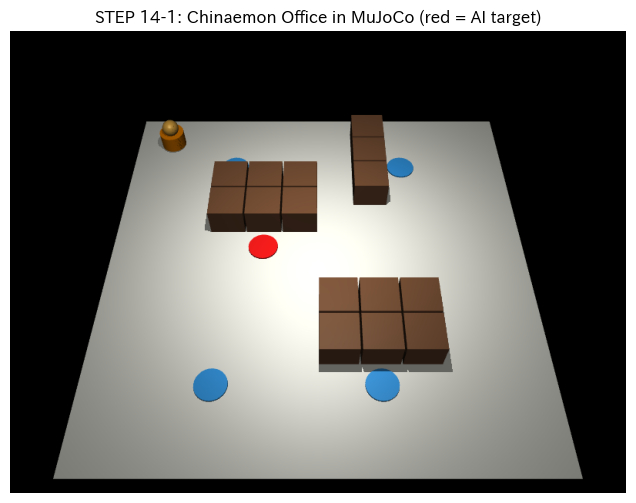

In [84]:
# STEP 14-1：知奈えもんのオフィスをMuJoCo（3D物理シミュレータ）で再現

!apt-get install -y -qq libosmesa6 > /dev/null
!pip -q install mujoco

import os
os.environ["MUJOCO_GL"] = "osmesa"
os.environ["PYOPENGL_PLATFORM"] = "osmesa"

import mujoco
import matplotlib.pyplot as plt

# 1マスを0.5mとして、グリッド座標(行, 列)を3D座標(x, y)に変換
CELL = 0.5

def grid_to_world(pos):
    row, col = pos
    return col * CELL, -row * CELL

rows, cols = support_office.shape
cx, cy = (cols - 1) * CELL / 2, -(rows - 1) * CELL / 2

# 既存のオフィスマップの障害物（1のマス）を3Dの机として配置
desk_geoms = ""
for r in range(rows):
    for c in range(cols):
        if support_office[r, c] == 1:
            x, y = grid_to_world((r, c))
            desk_geoms += (f'<geom type="box" pos="{x} {y} 0.2" '
                           f'size="{CELL/2*0.95} {CELL/2*0.95} 0.2" rgba="0.45 0.3 0.2 1"/>\n')

# 担当者の席を床のマーカーで表示（赤：AI選定対象、青：その他）
staff_geoms = ""
for name, pos in staff_positions.items():
    x, y = grid_to_world(pos)
    color = "0.9 0.1 0.1 1" if name == ai_target_name else "0.2 0.6 0.9 1"
    staff_geoms += (f'<geom type="cylinder" pos="{x} {y} 0.01" size="{CELL*0.4} 0.01" '
                    f'rgba="{color}" contype="0" conaffinity="0"/>\n')

# 知奈えもん（オレンジのロボット）を出発地点に配置
sx, sy = grid_to_world(start_position)

office_xml = f"""
<mujoco model="chinaemon_office">
  <visual><global offwidth="800" offheight="600"/></visual>
  <worldbody>
    <light pos="{cx} {cy} 6" dir="0 0 -1"/>
    <geom type="plane" pos="{cx} {cy} 0" size="{cols*CELL/2+0.3} {rows*CELL/2+0.3} 0.1" rgba="0.92 0.92 0.88 1"/>
    {desk_geoms}
    {staff_geoms}
    <body name="chinaemon" mocap="true" pos="{sx} {sy} 0.15">
      <geom type="cylinder" size="0.18 0.12" rgba="1 0.55 0 1"/>
      <geom type="sphere" pos="0 0 0.2" size="0.12" rgba="1 0.75 0.3 1"/>
    </body>
  </worldbody>
</mujoco>
"""

office_model = mujoco.MjModel.from_xml_string(office_xml)
office_data = mujoco.MjData(office_model)
mujoco.mj_forward(office_model, office_data)

# 斜め上からオフィス全体を見下ろすカメラ
office_camera = mujoco.MjvCamera()
office_camera.lookat[:] = [cx, cy, 0]
office_camera.distance = 7.5
office_camera.elevation = -55
office_camera.azimuth = 90

office_renderer = mujoco.Renderer(office_model, height=600, width=800)
office_renderer.update_scene(office_data, camera=office_camera)
office_image = office_renderer.render()
office_renderer.close()

print("MuJoCoバージョン:", mujoco.__version__)
print("机・障害物のマス数:", int(support_office.sum()))
print("知奈えもんの出発地点:", start_position)
print("AI選定対象:", ai_target_name, ai_target_position)

plt.figure(figsize=(8, 6))
plt.imshow(office_image)
plt.axis("off")
plt.title("STEP 14-1: Chinaemon Office in MuJoCo (red = AI target)")
plt.show()

In [85]:
# STEP 14-2：AI選定経路に沿って知奈えもんが3Dオフィスを移動する動画

!pip -q install mediapy

import numpy as np
import mediapy as media

# 経路上に「通過済み」を示す緑のタイルを配置（最初は透明）
trail_geoms = ""
for i, pos in enumerate(ai_safe_route):
    x, y = grid_to_world(pos)
    trail_geoms += (f'<geom name="trail_{i}" type="box" pos="{x} {y} 0.005" '
                    f'size="{CELL*0.3} {CELL*0.3} 0.004" rgba="0.2 0.8 0.2 0" '
                    f'contype="0" conaffinity="0"/>\n')

# STEP 14-1のオフィスに緑タイルを追加したモデルを作成（STEP 14-1の変数は変更しない）
move_xml = office_xml.replace("</worldbody>", trail_geoms + "</worldbody>")
move_model = mujoco.MjModel.from_xml_string(move_xml)
move_data = mujoco.MjData(move_model)
robot_mocap_id = move_model.body("chinaemon").mocapid[0]

# 1マスあたりのフレーム数（大きいほどゆっくり移動）
FRAMES_PER_CELL = 12
FPS = 24

move_renderer = mujoco.Renderer(move_model, height=600, width=800)
move_frames = []

def render_frame():
    mujoco.mj_forward(move_model, move_data)
    move_renderer.update_scene(move_data, camera=office_camera)
    move_frames.append(move_renderer.render())

def set_robot(x, y):
    move_data.mocap_pos[robot_mocap_id] = [x, y, 0.15]

def show_trail(i):
    move_model.geom_rgba[move_model.geom(f"trail_{i}").id][3] = 1.0

# 出発地点で少し静止
x0, y0 = grid_to_world(ai_safe_route[0])
set_robot(x0, y0)
show_trail(0)
for _ in range(FPS // 2):
    render_frame()

# 経路の各マスの間をなめらかに移動
for i in range(1, len(ai_safe_route)):
    xa, ya = grid_to_world(ai_safe_route[i - 1])
    xb, yb = grid_to_world(ai_safe_route[i])
    for k in range(1, FRAMES_PER_CELL + 1):
        t = k / FRAMES_PER_CELL
        set_robot(xa + (xb - xa) * t, ya + (yb - ya) * t)
        render_frame()
    show_trail(i)

# 到着：鈴木さんの席のマーカーを緑に変えて静止
target_geom_id = [
    g for g in range(move_model.ngeom)
    if np.allclose(move_model.geom_rgba[g], [0.9, 0.1, 0.1, 1])
][0]
move_model.geom_rgba[target_geom_id] = [0.1, 0.8, 0.1, 1]
for _ in range(FPS):
    render_frame()

move_renderer.close()

# MP4として保存
video_path = "chinaemon_3d_navigation.mp4"
media.write_video(video_path, move_frames, fps=FPS)

print("移動経路:", ai_safe_route)
print("移動ステップ数:", len(ai_safe_route) - 1)
print("到着地点:", ai_safe_route[-1], "/ AI選定対象の席:", ai_target_position)
print("到着判定:", ai_safe_route[-1] == ai_target_position)
print("フレーム数:", len(move_frames), f"（約{len(move_frames) / FPS:.1f}秒）")
print("保存先:", video_path)

media.show_video(move_frames, fps=FPS)

移動経路: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (4, 1), (4, 2), (4, 3)]
移動ステップ数: 7
到着地点: (4, 3) / AI選定対象の席: (4, 3)
到着判定: True
フレーム数: 120 （約5.0秒）
保存先: chinaemon_3d_navigation.mp4


This browser does not support the video tag.


In [86]:
# STEP 14-3：MuJoCo物理演算による差動二輪ロボットの直進・旋回テスト

import numpy as np
import mediapy as media

# 差動二輪ロボット（知奈えもん）の寸法
WHEEL_RADIUS = 0.06   # 車輪の半径 [m]
WHEEL_BASE = 0.30     # 左右の車輪の間隔 [m]

sx, sy = grid_to_world(start_position)

# STEP 14-1の机・担当者マーカーを再利用し、ロボットだけ物理モデルに置き換える
diffdrive_xml = f"""
<mujoco model="chinaemon_diffdrive">
  <option timestep="0.002" integrator="implicitfast"/>
  <visual><global offwidth="800" offheight="600"/></visual>
  <worldbody>
    <light pos="{cx} {cy} 6" dir="0 0 -1"/>
    <geom type="plane" pos="{cx} {cy} 0" size="{cols*CELL/2+0.3} {rows*CELL/2+0.3} 0.1"
          rgba="0.92 0.92 0.88 1" friction="1 0.005 0.0001"/>
    {desk_geoms}
    {staff_geoms}

    <body name="chinaemon_base" pos="{sx} {sy} {WHEEL_RADIUS}">
      <freejoint/>
      <!-- 胴体 -->
      <geom type="cylinder" size="0.16 0.05" pos="0 0 0.03" rgba="1 0.55 0 1" mass="2"/>
      <!-- 頭 -->
      <geom type="sphere" size="0.10" pos="0 0 0.17" rgba="1 0.75 0.3 1" mass="0.3"/>
      <!-- 前方を示す目印 -->
      <geom type="box" size="0.03 0.05 0.02" pos="0.15 0 0.08" rgba="0.2 0.2 0.2 1" mass="0.01"/>
      <!-- 前後のキャスター（摩擦なしで滑る補助輪） -->
      <geom type="sphere" size="0.02" pos="0.12 0 -0.035" condim="1" rgba="0.3 0.3 0.3 1" mass="0.05"/>
      <geom type="sphere" size="0.02" pos="-0.12 0 -0.035" condim="1" rgba="0.3 0.3 0.3 1" mass="0.05"/>
      <!-- 左車輪 -->
      <body name="left_wheel" pos="0 {WHEEL_BASE/2} 0">
        <joint name="left_wheel_joint" type="hinge" axis="0 1 0" damping="0.01" armature="0.01"/>
        <geom type="cylinder" size="{WHEEL_RADIUS} 0.02" euler="90 0 0"
              rgba="0.15 0.15 0.15 1" mass="0.2" friction="1.5 0.005 0.0001"/>
      </body>
      <!-- 右車輪 -->
      <body name="right_wheel" pos="0 {-WHEEL_BASE/2} 0">
        <joint name="right_wheel_joint" type="hinge" axis="0 1 0" damping="0.01" armature="0.01"/>
        <geom type="cylinder" size="{WHEEL_RADIUS} 0.02" euler="90 0 0"
              rgba="0.15 0.15 0.15 1" mass="0.2" friction="1.5 0.005 0.0001"/>
      </body>
    </body>
  </worldbody>

  <!-- 左右の車輪モーター（目標角速度で駆動） -->
  <actuator>
    <velocity name="left_motor"  joint="left_wheel_joint"  kv="5" ctrlrange="-20 20"/>
    <velocity name="right_motor" joint="right_wheel_joint" kv="5" ctrlrange="-20 20"/>
  </actuator>
</mujoco>
"""

dd_model = mujoco.MjModel.from_xml_string(diffdrive_xml)
dd_data = mujoco.MjData(dd_model)
mujoco.mj_forward(dd_model, dd_data)

dd_renderer = mujoco.Renderer(dd_model, height=600, width=800)
dd_frames = []
FPS = 24
steps_per_frame = int(1 / (FPS * dd_model.opt.timestep))

def robot_pose():
    """ロボットの位置(x, y)と向き(yaw, 度)を物理状態から取得"""
    x, y = dd_data.qpos[0], dd_data.qpos[1]
    w, qx, qy, qz = dd_data.qpos[3:7]
    yaw = np.degrees(np.arctan2(2 * (w * qz + qx * qy), 1 - 2 * (qy**2 + qz**2)))
    return x, y, yaw

def drive(left, right, seconds):
    """左右の車輪に目標角速度[rad/s]を与えて、指定秒数だけ物理演算を進める"""
    dd_data.ctrl[:] = [left, right]
    n_steps = int(seconds / dd_model.opt.timestep)
    for step in range(n_steps):
        mujoco.mj_step(dd_model, dd_data)
        if step % steps_per_frame == 0:
            dd_renderer.update_scene(dd_data, camera=office_camera)
            dd_frames.append(dd_renderer.render())

# 物理的に落ち着かせる（着地）
drive(0, 0, 0.5)
x0, y0, yaw0 = robot_pose()

# テスト1：直進（左右同じ速度）
drive(8, 8, 2.0)
drive(0, 0, 0.5)
x1, y1, yaw1 = robot_pose()

# テスト2：その場で右旋回（左を前進、右を後退）
drive(4, -4, 1.0)
drive(0, 0, 0.5)
x2, y2, yaw2 = robot_pose()

dd_renderer.close()

straight_dist = np.hypot(x1 - x0, y1 - y0)
straight_drift = abs(y1 - y0)
turn_angle = (yaw2 - yaw1 + 180) % 360 - 180
turn_shift = np.hypot(x2 - x1, y2 - y1)

print("【STEP 14-3：差動二輪ロボットの物理走行テスト】")
print(f"開始位置: x={x0:.3f}, y={y0:.3f}, 向き={yaw0:.1f}度")
print("\n[テスト1：直進]")
print(f"  走行距離: {straight_dist:.3f} m（理論値 {8 * WHEEL_RADIUS * 2.0:.3f} m）")
print(f"  横ずれ:   {straight_drift:.3f} m")
print(f"  向きの変化: {yaw1 - yaw0:.1f} 度")
print("\n[テスト2：その場で右旋回]")
print(f"  旋回角度: {turn_angle:.1f} 度（右回りはマイナス）")
print(f"  旋回中の位置ずれ: {turn_shift:.3f} m")
print(f"\nフレーム数: {len(dd_frames)}（約{len(dd_frames) / FPS:.1f}秒）")

media.write_video("chinaemon_diffdrive_test.mp4", dd_frames, fps=FPS)
media.show_video(dd_frames, fps=FPS)

【STEP 14-3：差動二輪ロボットの物理走行テスト】
開始位置: x=0.002, y=0.000, 向き=-0.0度

[テスト1：直進]
  走行距離: 0.932 m（理論値 0.960 m）
  横ずれ:   0.000 m
  向きの変化: 0.0 度

[テスト2：その場で右旋回]
  旋回角度: -88.6 度（右回りはマイナス）
  旋回中の位置ずれ: 0.002 m

フレーム数: 114（約4.8秒）


This browser does not support the video tag.


In [87]:
# STEP 14-4：AI選定経路に沿った差動二輪ロボットの物理走行（フィードバック制御）

import numpy as np
import mediapy as media

# STEP 14-3のロボットモデルに、通過済みを示す緑タイルを追加（STEP 14-3の変数は変更しない）
nav_trail_geoms = ""
for i, pos in enumerate(ai_safe_route):
    x, y = grid_to_world(pos)
    nav_trail_geoms += (f'<geom name="nav_trail_{i}" type="box" pos="{x} {y} 0.003" '
                        f'size="{CELL*0.3} {CELL*0.3} 0.002" rgba="0.2 0.8 0.2 0" '
                        f'contype="0" conaffinity="0"/>\n')

nav_xml = diffdrive_xml.replace("<body name=\"chinaemon_base\"",
                                nav_trail_geoms + "<body name=\"chinaemon_base\"", 1)
nav_model = mujoco.MjModel.from_xml_string(nav_xml)
nav_data = mujoco.MjData(nav_model)
mujoco.mj_forward(nav_model, nav_data)

# ロボットに属する部品と、床を判別（衝突判定用）
robot_body_ids = {nav_model.body(n).id for n in ["chinaemon_base", "left_wheel", "right_wheel"]}
floor_geom_id = 0  # 最初に定義した床

def is_robot_geom(g):
    return nav_model.geom_bodyid[g] in robot_body_ids

def desk_contact_now():
    """ロボットが床以外の物体（机）に接触しているか"""
    for c in nav_data.contact[:nav_data.ncon]:
        g1, g2 = c.geom1, c.geom2
        if is_robot_geom(g1) != is_robot_geom(g2):
            other = g2 if is_robot_geom(g1) else g1
            if other != floor_geom_id:
                return True
    return False

def nav_pose():
    x, y = nav_data.qpos[0], nav_data.qpos[1]
    w, qx, qy, qz = nav_data.qpos[3:7]
    yaw = np.arctan2(2 * (w * qz + qx * qy), 1 - 2 * (qy**2 + qz**2))
    return x, y, yaw

# 制御パラメータ
MAX_WHEEL = 12.0      # 車輪の最大角速度 [rad/s]
REACH_TOL = 0.05      # 経由点に到達したとみなす距離 [m]
TURN_FIRST = 0.35     # 向きのずれがこれ以上なら、まずその場で旋回 [rad]
K_V, K_W = 1.5, 4.0   # 前進・旋回の比例ゲイン
TIME_LIMIT = 30.0     # 打ち切り時間 [s]

nav_renderer = mujoco.Renderer(nav_model, height=600, width=800)
nav_frames = []
FPS = 24
steps_per_frame = int(1 / (FPS * nav_model.opt.timestep))

def nav_step(left, right, step_count):
    nav_data.ctrl[:] = [left, right]
    mujoco.mj_step(nav_model, nav_data)
    if step_count % steps_per_frame == 0:
        nav_renderer.update_scene(nav_data, camera=office_camera)
        nav_frames.append(nav_renderer.render())

def show_nav_trail(i):
    nav_model.geom_rgba[nav_model.geom(f"nav_trail_{i}").id][3] = 1.0

# 着地
step_count = 0
for _ in range(250):
    nav_step(0, 0, step_count); step_count += 1
show_nav_trail(0)

collision_events = 0
in_contact = False
reached = 0
min_err = []

# 経由点（AI経路の各マス）を順に目指す
for i in range(1, len(ai_safe_route)):
    gx, gy = grid_to_world(ai_safe_route[i])
    while nav_data.time < TIME_LIMIT:
        x, y, yaw = nav_pose()
        dist = np.hypot(gx - x, gy - y)
        if dist < REACH_TOL:
            break
        heading_err = (np.arctan2(gy - y, gx - x) - yaw + np.pi) % (2 * np.pi) - np.pi

        # 向きが大きくずれていれば旋回のみ、そうでなければ前進しながら向きを補正
        v = 0.0 if abs(heading_err) > TURN_FIRST else min(K_V * dist, 0.5)
        w = K_W * heading_err
        left = np.clip((v - w * WHEEL_BASE / 2) / WHEEL_RADIUS, -MAX_WHEEL, MAX_WHEEL)
        right = np.clip((v + w * WHEEL_BASE / 2) / WHEEL_RADIUS, -MAX_WHEEL, MAX_WHEEL)
        nav_step(left, right, step_count); step_count += 1

        # 机との接触を検出（接触が始まった回数を数える）
        touching = desk_contact_now()
        if touching and not in_contact:
            collision_events += 1
        in_contact = touching
    else:
        break
    reached = i
    show_nav_trail(i)
    min_err.append(dist)

# 停止して到着を表示
for _ in range(int(1.0 / nav_model.opt.timestep)):
    nav_step(0, 0, step_count); step_count += 1

nav_renderer.close()

fx, fy, fyaw = nav_pose()
tx, ty = grid_to_world(ai_target_position)
final_error = np.hypot(tx - fx, ty - fy)
arrived_physics = (reached == len(ai_safe_route) - 1) and final_error < 0.10

print("【STEP 14-4：AI経路に沿った物理走行】")
print("AI選定対象:", ai_target_name, ai_target_position)
print(f"経由点の到達数: {reached} / {len(ai_safe_route) - 1}")
print(f"最終位置: x={fx:.3f}, y={fy:.3f}（目標 x={tx:.3f}, y={ty:.3f}）")
print(f"目標との誤差: {final_error:.3f} m")
print(f"走行時間（物理時間）: {nav_data.time:.1f} 秒")
print(f"机との衝突回数: {collision_events} 回")
print("到着判定:", arrived_physics)

media.write_video("chinaemon_physics_navigation.mp4", nav_frames, fps=FPS)
print(f"動画: chinaemon_physics_navigation.mp4（{len(nav_frames)}フレーム、約{len(nav_frames) / FPS:.1f}秒）")
media.show_video(nav_frames, fps=FPS)

【STEP 14-4：AI経路に沿った物理走行】
AI選定対象: 鈴木 (4, 3)
経由点の到達数: 7 / 7
最終位置: x=1.450, y=-2.000（目標 x=1.500, y=-2.000）
目標との誤差: 0.050 m
走行時間（物理時間）: 14.4 秒
机との衝突回数: 0 回
到着判定: True
動画: chinaemon_physics_navigation.mp4（359フレーム、約15.0秒）


This browser does not support the video tag.


【成功判定基準】
  ① 経路上のすべての経由点に到達
  ② 最終位置と目標の誤差 0.1 m 未満
  ③ 机との接触 0回（MuJoCoの接触判定で実測）
  ④ 打ち切り時間内に到着（経路長 × 4.0 秒 + 5 秒）

【車体幅の確認】
  ロボットの最大半径: 0.170 m（車幅 0.34 m）
  1マス幅通路の半幅:  0.2625 m
  理論上の最小すき間: 0.0925 m（安全余裕 0.05 m 以上が条件）
  判定: 通行可能
L0 既存オフィス: 成功 5 / 経路なし 0 / 失敗 0
L1 ランダム(密度15%): 成功 5 / 経路なし 0 / 失敗 0
L2 ランダム(密度20%): 成功 5 / 経路なし 0 / 失敗 0
L3 ランダム(密度20%): 成功 5 / 経路なし 0 / 失敗 0
L4 ランダム(密度25%): 成功 5 / 経路なし 0 / 失敗 0
L5 ランダム(密度25%): 成功 5 / 経路なし 0 / 失敗 0
L6 ランダム(密度30%): 成功 5 / 経路なし 0 / 失敗 0
L7 ランダム(密度30%): 成功 5 / 経路なし 0 / 失敗 0
L8 鈴木さんの席を封鎖: 成功 4 / 経路なし 1 / 失敗 0

【評価結果一覧】


,配置,目的地,障害物マス,経路,経路長,判定,到達経由点,衝突回数,所要時間[s],誤差[m],最小すき間[m],車体幅の余裕
0,L0 既存オフィス,"田中(1, 2)",15,あり,3.0,成功,3/3,0.0,6.5,0.05,0.128,確保
1,L0 既存オフィス,"佐藤(1, 7)",15,あり,12.0,成功,12/12,0.0,23.0,0.05,0.081,確保
2,L0 既存オフィス,"鈴木(4, 3)",15,あり,7.0,成功,7/7,0.0,13.9,0.05,0.087,確保
3,L0 既存オフィス,"高橋(8, 6)",15,あり,14.0,成功,14/14,0.0,26.8,0.05,0.081,確保
4,L0 既存オフィス,"伊藤(8, 2)",15,あり,10.0,成功,10/10,0.0,19.4,0.05,0.082,確保
5,L1 ランダム(密度15%),"田中(1, 2)",13,あり,3.0,成功,3/3,0.0,6.8,0.05,0.092,確保
6,L1 ランダム(密度15%),"佐藤(1, 7)",13,あり,10.0,成功,10/10,0.0,20.0,0.05,0.089,確保
7,L1 ランダム(密度15%),"鈴木(4, 3)",13,あり,7.0,成功,7/7,0.0,14.1,0.05,0.092,確保
8,L1 ランダム(密度15%),"高橋(8, 6)",13,あり,14.0,成功,14/14,0.0,27.1,0.05,0.083,確保
9,L1 ランダム(密度15%),"伊藤(8, 2)",13,あり,10.0,成功,10/10,0.0,19.4,0.05,0.083,確保


【集計】
  評価配置数: 9、目的地: 5席、試行数: 45
  経路なし（BFSが正しく検出）: 1
  物理走行を実施: 44
  到達成功率: 44/44 = 100.0%
  衝突回数の合計: 0
  所要時間: 平均 18.8 秒（最短 6.5、最長 57.9）
  目標との誤差: 平均 0.050 m、最大 0.050 m
  経路長: 最短 3 マス、最長 31 マス
  車体幅の余裕不足（すき間 < 0.05 m）: 0 件
  走行中の机との最小すき間: 0.073 m（理論値 0.093 m）


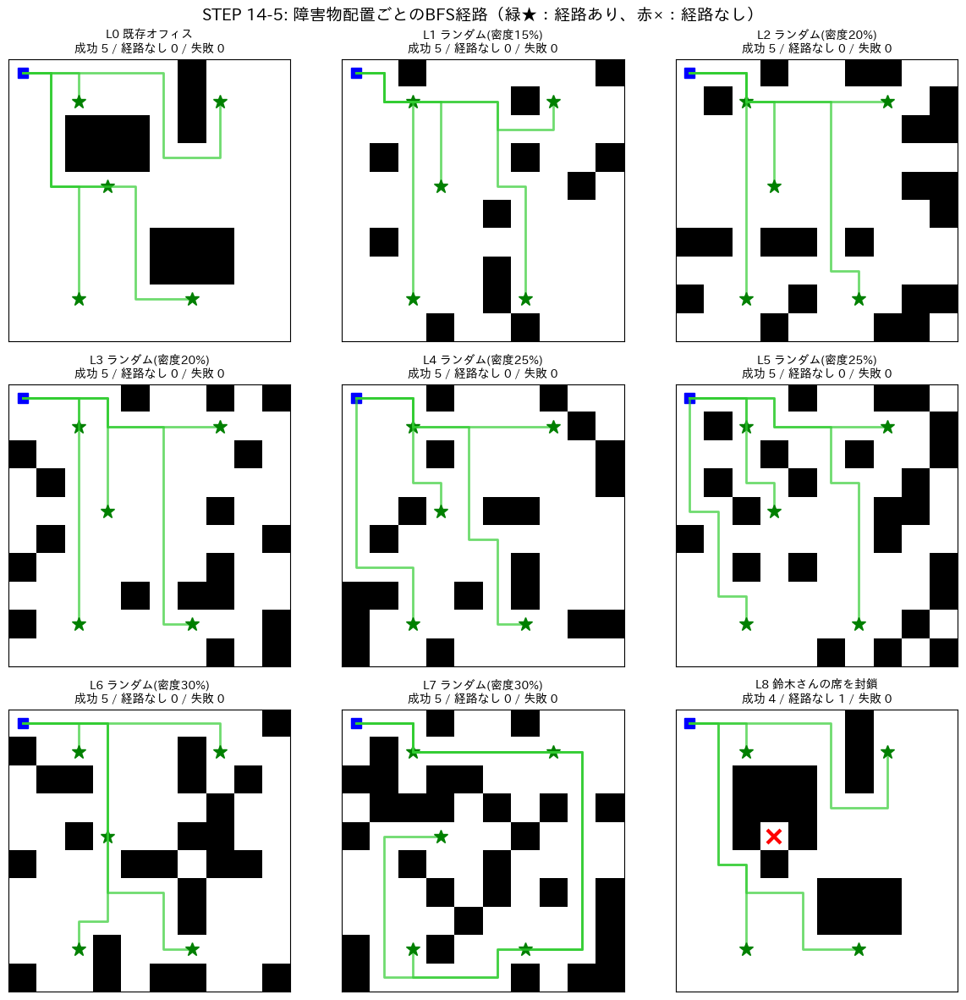

保存: chinaemon_eval_results.csv / chinaemon_eval_layouts.png


In [88]:
# STEP 14-5：複数の障害物配置における経路探索〜物理走行の評価実験

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. 成功判定基準と車体幅の条件
# ---------------------------------------------------------------
EVAL_REACH_TOL = 0.10        # 最終位置と目標の許容誤差 [m]
EVAL_TIME_PER_CELL = 4.0     # 1マスあたりの許容時間 [s]（打ち切り時間の算出用）
SAFETY_MARGIN = 0.05         # 車体と机の間に確保したい余裕 [m]

ROBOT_HALF_WIDTH = WHEEL_BASE / 2 + 0.02   # 車輪の外側までの半幅 [m]（車輪の厚み0.02を含む）
ROBOT_RADIUS = max(0.16, ROBOT_HALF_WIDTH)  # その場旋回時に机へ近づく最大半径 [m]
DESK_HALF = CELL / 2 * 0.95                 # 机1マスの半幅 [m]（STEP 14-1と同じ）
CORRIDOR_HALF = CELL - DESK_HALF            # 両側に机がある1マス幅通路の半幅 [m]
theory_clearance = CORRIDOR_HALF - ROBOT_RADIUS

print("【成功判定基準】")
print(f"  ① 経路上のすべての経由点に到達")
print(f"  ② 最終位置と目標の誤差 {EVAL_REACH_TOL} m 未満")
print(f"  ③ 机との接触 0回（MuJoCoの接触判定で実測）")
print(f"  ④ 打ち切り時間内に到着（経路長 × {EVAL_TIME_PER_CELL} 秒 + 5 秒）")
print("\n【車体幅の確認】")
print(f"  ロボットの最大半径: {ROBOT_RADIUS:.3f} m（車幅 {ROBOT_HALF_WIDTH*2:.2f} m）")
print(f"  1マス幅通路の半幅:  {CORRIDOR_HALF:.4f} m")
print(f"  理論上の最小すき間: {theory_clearance:.4f} m（安全余裕 {SAFETY_MARGIN} m 以上が条件）")
print(f"  判定: {'通行可能' if theory_clearance >= SAFETY_MARGIN else '車体幅により危険'}")

# ---------------------------------------------------------------
# 2. 評価用の障害物配置（再現性のため乱数シードを固定）
# ---------------------------------------------------------------
eval_start = start_position
# 目的地：全担当者の席（AI選定対象の鈴木さんを含む5席）
eval_goals = dict(staff_positions)

def make_random_layout(seed, density):
    r = np.random.default_rng(seed)
    layout = (r.random(support_office.shape) < density).astype(float)
    layout[eval_start] = 0
    for seat in eval_goals.values():      # 出発地点と全席は空けておく
        layout[seat] = 0
    return layout

eval_layouts = [("L0 既存オフィス", support_office.copy())]
for k, (seed, density) in enumerate([(1, 0.15), (2, 0.20), (3, 0.20), (4, 0.25),
                                     (5, 0.25), (6, 0.30), (7, 0.30)], start=1):
    eval_layouts.append((f"L{k} ランダム(密度{int(density*100)}%)", make_random_layout(seed, density)))

# AI選定対象（鈴木さん）の席を机で囲んだ「経路なし」の確認用配置
blocked = support_office.copy()
gr, gc = ai_target_position
for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
    nr, nc = gr + dr, gc + dc
    if 0 <= nr < blocked.shape[0] and 0 <= nc < blocked.shape[1]:
        blocked[nr, nc] = 1
eval_layouts.append(("L8 鈴木さんの席を封鎖", blocked))

# ---------------------------------------------------------------
# 3. 1つの配置について、BFS経路探索 → 物理走行を実行する関数
# ---------------------------------------------------------------
def build_layout_xml(layout, goal):
    new_desks = ""
    for r in range(layout.shape[0]):
        for c in range(layout.shape[1]):
            if layout[r, c] == 1:
                x, y = grid_to_world((r, c))
                new_desks += (f'<geom type="box" pos="{x} {y} 0.2" '
                              f'size="{DESK_HALF} {DESK_HALF} 0.2" rgba="0.45 0.3 0.2 1"/>\n')
    gx, gy = grid_to_world(goal)
    goal_marker = (f'<geom type="cylinder" pos="{gx} {gy} 0.01" size="{CELL*0.4} 0.01" '
                   f'rgba="0.9 0.1 0.1 1" contype="0" conaffinity="0"/>\n')
    # STEP 14-3のモデルの机・担当者マーカーだけを差し替える（ロボット部分は同一）
    return diffdrive_xml.replace(desk_geoms, new_desks).replace(staff_geoms, goal_marker)

def run_layout(name, layout, goal_name, goal):
    record = {"配置": name, "目的地": f"{goal_name}{goal}", "障害物マス": int(layout.sum())}
    route = find_ai_safe_route(layout, eval_start, goal)   # STEP 12-2のBFSを再利用

    if route is None:
        record.update({"経路": "なし", "経路長": None, "判定": "経路なし（走行せず）",
                       "到達経由点": None, "衝突回数": None, "所要時間[s]": None,
                       "誤差[m]": None, "最小すき間[m]": None, "車体幅の余裕": None})
        return record, None

    m = mujoco.MjModel.from_xml_string(build_layout_xml(layout, goal))
    d = mujoco.MjData(m)
    mujoco.mj_forward(m, d)

    robot_ids = {m.body(n).id for n in ["chinaemon_base", "left_wheel", "right_wheel"]}
    robot_geoms = [g for g in range(m.ngeom) if m.geom_bodyid[g] in robot_ids]
    desk_geom_ids = [g for g in range(m.ngeom)
                     if m.geom_bodyid[g] == 0 and m.geom_type[g] == mujoco.mjtGeom.mjGEOM_BOX]

    def pose():
        w, qx, qy, qz = d.qpos[3:7]
        return d.qpos[0], d.qpos[1], np.arctan2(2*(w*qz + qx*qy), 1 - 2*(qy**2 + qz**2))

    def touching_desk():
        for c in d.contact[:d.ncon]:
            a, b = c.geom1 in robot_geoms, c.geom2 in robot_geoms
            if a != b:
                other = c.geom2 if a else c.geom1
                if other in desk_geom_ids:
                    return True
        return False

    def min_gap():
        best = 1.0
        for g1 in robot_geoms:
            for g2 in desk_geom_ids:
                best = min(best, mujoco.mj_geomDistance(m, d, g1, g2, 1.0, None))
        return best

    time_limit = 0.5 + (len(route) - 1) * EVAL_TIME_PER_CELL + 5.0
    for _ in range(250):                      # 着地
        d.ctrl[:] = [0, 0]; mujoco.mj_step(m, d)

    collisions, in_contact, reached = 0, False, 0
    gap_min = min_gap() if desk_geom_ids else 1.0
    step = 0
    timed_out = False

    for i in range(1, len(route)):
        gx, gy = grid_to_world(route[i])
        while True:
            if d.time >= time_limit:
                timed_out = True
                break
            x, y, yaw = pose()
            dist = np.hypot(gx - x, gy - y)
            if dist < REACH_TOL:              # STEP 14-4と同じ経由点の到達判定
                break
            err = (np.arctan2(gy - y, gx - x) - yaw + np.pi) % (2*np.pi) - np.pi
            v = 0.0 if abs(err) > TURN_FIRST else min(K_V * dist, 0.5)
            w = K_W * err
            d.ctrl[:] = [np.clip((v - w*WHEEL_BASE/2) / WHEEL_RADIUS, -MAX_WHEEL, MAX_WHEEL),
                         np.clip((v + w*WHEEL_BASE/2) / WHEEL_RADIUS, -MAX_WHEEL, MAX_WHEEL)]
            mujoco.mj_step(m, d)
            step += 1
            t = touching_desk()
            if t and not in_contact:
                collisions += 1
            in_contact = t
            if desk_geom_ids and step % 25 == 0:
                gap_min = min(gap_min, min_gap())
        if timed_out:
            break
        reached = i

    for _ in range(250):                      # 停止
        d.ctrl[:] = [0, 0]; mujoco.mj_step(m, d)

    fx, fy, _ = pose()
    tx, ty = grid_to_world(goal)
    error = float(np.hypot(tx - fx, ty - fy))
    all_reached = reached == len(route) - 1

    # 判定（物理走行の失敗は理由を区別して記録）
    reasons = []
    if timed_out or not all_reached:
        reasons.append("時間切れ")
    if collisions > 0:
        reasons.append("衝突")
    if error >= EVAL_REACH_TOL:
        reasons.append("誤差超過")
    verdict = "成功" if not reasons else "物理走行失敗（" + "・".join(reasons) + "）"

    record.update({"経路": "あり", "経路長": len(route) - 1, "判定": verdict,
                   "到達経由点": f"{reached}/{len(route) - 1}", "衝突回数": collisions,
                   "所要時間[s]": round(d.time, 1), "誤差[m]": round(error, 3),
                   "最小すき間[m]": round(gap_min, 3),
                   "車体幅の余裕": "確保" if gap_min >= SAFETY_MARGIN else "不足（要注意）"})
    return record, route

# ---------------------------------------------------------------
# 4. 全配置で実行
# ---------------------------------------------------------------
eval_records, eval_routes = [], {}
for name, layout in eval_layouts:
    results = []
    for goal_name, goal in eval_goals.items():
        rec, route = run_layout(name, layout, goal_name, goal)
        eval_records.append(rec)
        eval_routes[(name, goal_name)] = route
        results.append(rec["判定"])
    n_ok = results.count("成功")
    n_np = sum(r.startswith("経路なし") for r in results)
    print(f"{name}: 成功 {n_ok} / 経路なし {n_np} / 失敗 {len(results) - n_ok - n_np}")

eval_df = pd.DataFrame(eval_records)
print("\n【評価結果一覧】")
display(eval_df)

# ---------------------------------------------------------------
# 5. 集計（経路なしは物理走行の母数から除外）
# ---------------------------------------------------------------
n_total = len(eval_df)
n_no_path = (eval_df["経路"] == "なし").sum()
ran = eval_df[eval_df["経路"] == "あり"]
n_success = (ran["判定"] == "成功").sum()

print("【集計】")
print(f"  評価配置数: {len(eval_layouts)}、目的地: {len(eval_goals)}席、試行数: {n_total}")
print(f"  経路なし（BFSが正しく検出）: {n_no_path}")
print(f"  物理走行を実施: {len(ran)}")
print(f"  到達成功率: {n_success}/{len(ran)} = {n_success / len(ran) * 100:.1f}%")
print(f"  衝突回数の合計: {int(ran['衝突回数'].sum())}")
print(f"  所要時間: 平均 {ran['所要時間[s]'].mean():.1f} 秒（最短 {ran['所要時間[s]'].min()}、最長 {ran['所要時間[s]'].max()}）")
print(f"  目標との誤差: 平均 {ran['誤差[m]'].mean():.3f} m、最大 {ran['誤差[m]'].max():.3f} m")
print(f"  経路長: 最短 {int(ran['経路長'].min())} マス、最長 {int(ran['経路長'].max())} マス")
print(f"  車体幅の余裕不足（すき間 < {SAFETY_MARGIN} m）: {(ran['車体幅の余裕'] != '確保').sum()} 件")
print(f"  走行中の机との最小すき間: {ran['最小すき間[m]'].min():.3f} m（理論値 {theory_clearance:.3f} m）")

# ---------------------------------------------------------------
# 6. 配置と経路の一覧図
# ---------------------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for ax, (name, layout) in zip(axes.flat, eval_layouts):
    ax.imshow(layout, cmap="Greys", vmin=0, vmax=1)
    ax.plot(eval_start[1], eval_start[0], "bs", markersize=9)
    sub = eval_df[eval_df["配置"] == name]
    for goal_name, goal in eval_goals.items():
        route = eval_routes[(name, goal_name)]
        if route:
            ax.plot([p[1] for p in route], [p[0] for p in route], color="limegreen", linewidth=2, alpha=0.7)
            ax.plot(goal[1], goal[0], "g*", markersize=12)
        else:
            ax.plot(goal[1], goal[0], "rx", markersize=12, mew=3)
    n_ok = (sub["判定"] == "成功").sum()
    n_np = (sub["経路"] == "なし").sum()
    ax.set_title(f"{name}\n成功 {n_ok} / 経路なし {n_np} / 失敗 {len(sub) - n_ok - n_np}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("STEP 14-5: 障害物配置ごとのBFS経路（緑★：経路あり、赤×：経路なし）", fontsize=14)
plt.tight_layout()
plt.savefig("chinaemon_eval_layouts.png", dpi=150)
plt.show()

eval_df.to_csv("chinaemon_eval_results.csv", index=False, encoding="utf-8-sig")
print("保存: chinaemon_eval_results.csv / chinaemon_eval_layouts.png")

【試験条件】
  コース: L字通路 9 マス（曲がり角1か所）
  ロボットの車幅: 0.34 m
  計画段階の通行条件: 通路幅 ≥ 車幅 + 安全余裕×2 = 0.44 m
通路幅 0.525 m: 計画=通行可 / 物理=成功 / 衝突 0回
通路幅 0.500 m: 計画=通行可 / 物理=成功 / 衝突 0回
通路幅 0.460 m: 計画=通行可 / 物理=成功 / 衝突 0回
通路幅 0.440 m: 計画=通行可 / 物理=成功 / 衝突 0回
通路幅 0.420 m: 計画=通行不可（車体幅） / 物理=成功 / 衝突 0回
通路幅 0.400 m: 計画=通行不可（車体幅） / 物理=成功 / 衝突 0回
通路幅 0.380 m: 計画=通行不可（車体幅） / 物理=成功 / 衝突 0回
通路幅 0.360 m: 計画=通行不可（車体幅） / 物理=失敗（衝突） / 衝突 1回
通路幅 0.350 m: 計画=通行不可（車体幅） / 物理=失敗（時間切れ・衝突・誤差超過） / 衝突 295回
通路幅 0.340 m: 計画=通行不可（車体幅） / 物理=失敗（時間切れ・衝突・誤差超過） / 衝突 1回
通路幅 0.320 m: 計画=通行不可（車体幅） / 物理=失敗（時間切れ・衝突・誤差超過） / 衝突 1回

【ストレステスト結果】


,通路幅[m],車幅との差[m],計画判定,物理走行,到達経由点,衝突回数,最小すき間[m],誤差[m],所要時間[s],計画と物理の整合
0,0.525,0.185,通行可,成功,9/9,0,0.081,0.050,16.5,一致（通行許可・走行成功）
1,0.500,0.160,通行可,成功,9/9,0,0.069,0.050,16.5,一致（通行許可・走行成功）
2,0.460,0.120,通行可,成功,9/9,0,0.049,0.050,16.5,一致（通行許可・走行成功）
3,0.440,0.100,通行可,成功,9/9,0,0.039,0.050,16.5,一致（通行許可・走行成功）
4,0.420,0.080,通行不可（車体幅）,成功,9/9,0,0.029,0.050,16.5,安全側（禁止したが走行は可能）
5,0.400,0.060,通行不可（車体幅）,成功,9/9,0,0.018,0.050,16.5,安全側（禁止したが走行は可能）
6,0.380,0.040,通行不可（車体幅）,成功,9/9,0,0.007,0.050,16.5,安全側（禁止したが走行は可能）
7,0.360,0.020,通行不可（車体幅）,失敗（衝突）,9/9,1,0.001,0.050,16.6,一致（通行禁止で事故を回避）
8,0.350,0.010,通行不可（車体幅）,失敗（時間切れ・衝突・誤差超過）,5/9,295,-0.006,1.844,41.5,一致（通行禁止で事故を回避）
9,0.340,0.000,通行不可（車体幅）,失敗（時間切れ・衝突・誤差超過）,0/9,1,-0.005,3.144,41.5,一致（通行禁止で事故を回避）


【集計】
  物理走行が成功した最小の通路幅: 0.380 m（車幅との差 0.040 m）
  物理走行が失敗した最大の通路幅: 0.360 m
  計画段階の通行条件: 0.44 m 以上
  計画が通行を許可したのに物理走行で失敗した件数: 0 件


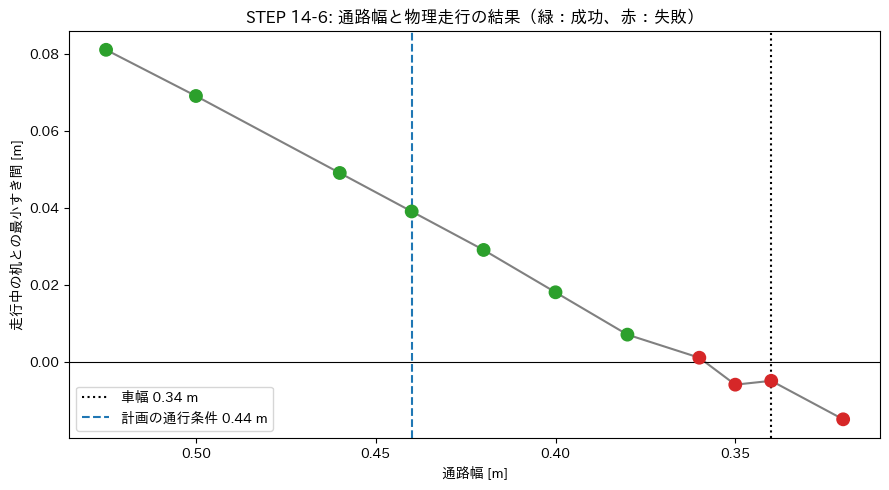

保存: chinaemon_stress_test.csv / chinaemon_stress_test.png


In [89]:
# STEP 14-6：車体幅に対する通路幅のストレステスト（衝突が起き始める境界の実測）

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. 試験コース：両側を机で挟んだL字型の通路（それ以外はすべて机）
# ---------------------------------------------------------------
stress_layout = np.ones_like(support_office)
for c in range(1, 7):
    stress_layout[4, c] = 0          # 横方向の通路
for r in range(4, 9):
    stress_layout[r, 6] = 0          # 縦方向の通路（曲がり角あり）
stress_start, stress_goal = (4, 1), (8, 6)
stress_route = find_ai_safe_route(stress_layout, stress_start, stress_goal)   # STEP 12-2のBFS

ROBOT_WIDTH = ROBOT_HALF_WIDTH * 2                    # 0.34 m（STEP 14-5で定義）
REQUIRED_WIDTH = ROBOT_WIDTH + 2 * SAFETY_MARGIN      # 計画段階で要求する通路幅

print("【試験条件】")
print(f"  コース: L字通路 {len(stress_route) - 1} マス（曲がり角1か所）")
print(f"  ロボットの車幅: {ROBOT_WIDTH:.2f} m")
print(f"  計画段階の通行条件: 通路幅 ≥ 車幅 + 安全余裕×2 = {REQUIRED_WIDTH:.2f} m")

# ---------------------------------------------------------------
# 2. 机の大きさ（＝通路幅）を変えて1回走行する関数
# ---------------------------------------------------------------
def run_corridor_trial(corridor_width):
    desk_half = CELL - corridor_width / 2             # 通路幅から机の半幅を逆算
    desks = ""
    for r in range(stress_layout.shape[0]):
        for c in range(stress_layout.shape[1]):
            if stress_layout[r, c] == 1:
                x, y = grid_to_world((r, c))
                desks += (f'<geom type="box" pos="{x} {y} 0.2" '
                          f'size="{desk_half} {desk_half} 0.2" rgba="0.45 0.3 0.2 1"/>\n')
    gx, gy = grid_to_world(stress_goal)
    marker = (f'<geom type="cylinder" pos="{gx} {gy} 0.01" size="0.15 0.01" '
              f'rgba="0.9 0.1 0.1 1" contype="0" conaffinity="0"/>\n')
    sx2, sy2 = grid_to_world(stress_start)
    robot_tag = f'<body name="chinaemon_base" pos="{sx} {sy} {WHEEL_RADIUS}">'
    if robot_tag not in diffdrive_xml:
        raise ValueError("ロボットの初期位置を差し替えられません（STEP 14-3のsx, syを確認してください）")
    xml = (diffdrive_xml.replace(desk_geoms, desks).replace(staff_geoms, marker)
           .replace(robot_tag, f'<body name="chinaemon_base" pos="{sx2} {sy2} {WHEEL_RADIUS}">'))
    m = mujoco.MjModel.from_xml_string(xml)
    d = mujoco.MjData(m)

    robot_ids = {m.body(n).id for n in ["chinaemon_base", "left_wheel", "right_wheel"]}
    robot_geoms = [g for g in range(m.ngeom) if m.geom_bodyid[g] in robot_ids]
    desk_ids = [g for g in range(m.ngeom)
                if m.geom_bodyid[g] == 0 and m.geom_type[g] == mujoco.mjtGeom.mjGEOM_BOX]

    def pose():
        w, qx, qy, qz = d.qpos[3:7]
        return d.qpos[0], d.qpos[1], np.arctan2(2*(w*qz + qx*qy), 1 - 2*(qy**2 + qz**2))

    def touching():
        for c in d.contact[:d.ncon]:
            a, b = c.geom1 in robot_geoms, c.geom2 in robot_geoms
            if a != b and (c.geom2 if a else c.geom1) in desk_ids:
                return True
        return False

    def min_gap():
        return min(mujoco.mj_geomDistance(m, d, g1, g2, 1.0, None)
                   for g1 in robot_geoms for g2 in desk_ids)

    for _ in range(250):
        d.ctrl[:] = [0, 0]; mujoco.mj_step(m, d)

    # ロボットの向きを最初の進行方向（東）にそろえた状態から開始
    time_limit = d.time + (len(stress_route) - 1) * EVAL_TIME_PER_CELL + 5.0
    collisions, in_contact, reached, step, timed_out = 0, False, 0, 0, False
    gap = min_gap()
    for i in range(1, len(stress_route)):
        gx, gy = grid_to_world(stress_route[i])
        while True:
            if d.time >= time_limit:
                timed_out = True; break
            x, y, yaw = pose()
            dist = np.hypot(gx - x, gy - y)
            if dist < REACH_TOL:
                break
            err = (np.arctan2(gy - y, gx - x) - yaw + np.pi) % (2*np.pi) - np.pi
            v = 0.0 if abs(err) > TURN_FIRST else min(K_V * dist, 0.5)
            w = K_W * err
            d.ctrl[:] = [np.clip((v - w*WHEEL_BASE/2) / WHEEL_RADIUS, -MAX_WHEEL, MAX_WHEEL),
                         np.clip((v + w*WHEEL_BASE/2) / WHEEL_RADIUS, -MAX_WHEEL, MAX_WHEEL)]
            mujoco.mj_step(m, d); step += 1
            t = touching()
            if t and not in_contact:
                collisions += 1
            in_contact = t
            if step % 25 == 0:
                gap = min(gap, min_gap())
        if timed_out:
            break
        reached = i

    fx, fy, _ = pose()
    tx, ty = grid_to_world(stress_goal)
    error = float(np.hypot(tx - fx, ty - fy))

    reasons = []
    if timed_out or reached < len(stress_route) - 1:
        reasons.append("時間切れ")
    if collisions > 0:
        reasons.append("衝突")
    if error >= EVAL_REACH_TOL:
        reasons.append("誤差超過")
    physics = "成功" if not reasons else "失敗（" + "・".join(reasons) + "）"
    planner_ok = corridor_width >= REQUIRED_WIDTH

    if planner_ok and physics == "成功":
        consistency = "一致（通行許可・走行成功）"
    elif not planner_ok and physics != "成功":
        consistency = "一致（通行禁止で事故を回避）"
    elif not planner_ok:
        consistency = "安全側（禁止したが走行は可能）"
    else:
        consistency = "危険（許可したが走行失敗）"

    return {"通路幅[m]": corridor_width,
            "車幅との差[m]": round(corridor_width - ROBOT_WIDTH, 3),
            "計画判定": "通行可" if planner_ok else "通行不可（車体幅）",
            "物理走行": physics,
            "到達経由点": f"{reached}/{len(stress_route) - 1}",
            "衝突回数": collisions,
            "最小すき間[m]": round(gap, 3),
            "誤差[m]": round(error, 3),
            "所要時間[s]": round(d.time, 1),
            "計画と物理の整合": consistency}

# ---------------------------------------------------------------
# 3. 通路幅を広い順に変えて実行（計画判定に関係なく、検証のため全条件で走行させる）
# ---------------------------------------------------------------
corridor_widths = [0.525, 0.50, 0.46, 0.44, 0.42, 0.40, 0.38, 0.36, 0.35, 0.34, 0.32]
stress_records = []
for wdt in corridor_widths:
    rec = run_corridor_trial(wdt)
    stress_records.append(rec)
    print(f"通路幅 {wdt:.3f} m: 計画={rec['計画判定']} / 物理={rec['物理走行']} / 衝突 {rec['衝突回数']}回")

stress_df = pd.DataFrame(stress_records)
print("\n【ストレステスト結果】")
display(stress_df)

ok_widths = stress_df[stress_df["物理走行"] == "成功"]["通路幅[m]"]
ng_widths = stress_df[stress_df["物理走行"] != "成功"]["通路幅[m]"]
print("【集計】")
print(f"  物理走行が成功した最小の通路幅: {ok_widths.min():.3f} m（車幅との差 {ok_widths.min() - ROBOT_WIDTH:.3f} m）")
if len(ng_widths):
    print(f"  物理走行が失敗した最大の通路幅: {ng_widths.max():.3f} m")
print(f"  計画段階の通行条件: {REQUIRED_WIDTH:.2f} m 以上")
n_danger = (stress_df["計画と物理の整合"] == "危険（許可したが走行失敗）").sum()
print(f"  計画が通行を許可したのに物理走行で失敗した件数: {n_danger} 件")

# ---------------------------------------------------------------
# 4. グラフ：通路幅と最小すき間・判定
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["tab:green" if p == "成功" else "tab:red" for p in stress_df["物理走行"]]
ax.scatter(stress_df["通路幅[m]"], stress_df["最小すき間[m]"], c=colors, s=80, zorder=3)
ax.plot(stress_df["通路幅[m]"], stress_df["最小すき間[m]"], color="gray", zorder=2)
ax.axvline(ROBOT_WIDTH, color="black", linestyle=":", label=f"車幅 {ROBOT_WIDTH:.2f} m")
ax.axvline(REQUIRED_WIDTH, color="tab:blue", linestyle="--", label=f"計画の通行条件 {REQUIRED_WIDTH:.2f} m")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("通路幅 [m]")
ax.set_ylabel("走行中の机との最小すき間 [m]")
ax.set_title("STEP 14-6: 通路幅と物理走行の結果（緑：成功、赤：失敗）")
ax.invert_xaxis()
ax.legend()
plt.tight_layout()
plt.savefig("chinaemon_stress_test.png", dpi=150)
plt.show()

stress_df.to_csv("chinaemon_stress_test.csv", index=False, encoding="utf-8-sig")
print("保存: chinaemon_stress_test.csv / chinaemon_stress_test.png")

In [90]:
# STEP 14-7：MuJoCo物理走行の到着確認 → 本人承認 → 模擬PC支援の統合

import ipywidgets as widgets
from IPython.display import display, clear_output
from datetime import datetime

# ---------------------------------------------------------------
# 1. 物理走行の到着判定（STEP 14-4の実測結果を使用。再走行はしない）
# ---------------------------------------------------------------
PHYSICS_ARRIVAL_TOL = EVAL_REACH_TOL   # STEP 14-5と同じ 0.10 m

def check_physics_arrival():
    """MuJoCo上の実測値から、AI選定対象の席に安全に到着したかを判定"""
    checks = {
        "AI選定対象と走行経路の終点が一致": ai_safe_route[-1] == ai_target_position,
        "全経由点に到達（STEP 14-4）": reached == len(ai_safe_route) - 1,
        f"目標との誤差 {PHYSICS_ARRIVAL_TOL} m 未満": final_error < PHYSICS_ARRIVAL_TOL,
        "机との衝突 0回": collision_events == 0,
    }
    return all(checks.values()), checks

def support_allowed(state):
    """支援の実行条件：物理到着と本人承認の両方がそろった場合のみ"""
    return state["physics_arrived"] is True and state["approved"] is True

# ---------------------------------------------------------------
# 2. このSTEP専用の状態（既存のai_flow_state・approval_stateは変更しない）
# ---------------------------------------------------------------
physics_flow_state = {
    "target": ai_target_name,
    "phase": "到着確認待ち",
    "physics_arrived": False,
    "approved": False,
    "decision": None,
    "support_result": None,
    "log": [],
}

def add_log(message):
    physics_flow_state["log"].append(
        f"{datetime.now().strftime('%H:%M:%S')} [{physics_flow_state['phase']}] {message}")

# ---------------------------------------------------------------
# 3. 操作ボタン（到着確認が通るまで承認・拒否は押せない）
# ---------------------------------------------------------------
p_arrival_btn = widgets.Button(description="物理到着を確認", button_style="info", icon="map-marker")
p_approve_btn = widgets.Button(description="承認する", button_style="success", icon="check", disabled=True)
p_reject_btn = widgets.Button(description="拒否する", button_style="danger", icon="times", disabled=True)
p_support_btn = widgets.Button(description="PC支援を実行", button_style="primary", icon="desktop", disabled=True)
p_output = widgets.Output()

def on_physics_arrival(_):
    ok, checks = check_physics_arrival()
    with p_output:
        print("【MuJoCo物理走行の到着判定】")
        for name, passed in checks.items():
            print(f"  {'✅' if passed else '❌'} {name}")
    p_arrival_btn.disabled = True
    if ok:
        physics_flow_state["physics_arrived"] = True
        physics_flow_state["phase"] = "承認待ち"
        add_log("物理到着を確認")
        p_approve_btn.disabled = False
        p_reject_btn.disabled = False
        with p_output:
            print(f"\n🐱 知奈えもん：{ai_target_name}さん、席に到着したにゃ。")
            print("🐱 知奈えもん：開発環境の模擬支援を実行してもいいかにゃ？")
    else:
        physics_flow_state["phase"] = "中止（未到着）"
        add_log("到着条件を満たさないため中止")
        with p_output:
            print("\n⛔ 安全な物理到着が確認できないため、承認待ちに移行しません。")

def on_physics_approve(_):
    if not physics_flow_state["physics_arrived"]:      # 二重チェック
        return
    physics_flow_state["approved"] = True
    physics_flow_state["decision"] = "承認"
    physics_flow_state["phase"] = "支援実行待ち"
    add_log("本人が承認")
    p_approve_btn.disabled = True
    p_reject_btn.disabled = True
    p_support_btn.disabled = False
    with p_output:
        print(f"\n✅ {ai_target_name}さんが支援を承認しました。")

def on_physics_reject(_):
    physics_flow_state["approved"] = False
    physics_flow_state["decision"] = "拒否"
    physics_flow_state["phase"] = "完了（拒否・支援なし）"
    add_log("本人が拒否。支援は実行しない")
    p_approve_btn.disabled = True
    p_reject_btn.disabled = True
    p_support_btn.disabled = True
    with p_output:
        print(f"\n❌ {ai_target_name}さんが支援を拒否しました。")
        print("🐱 知奈えもん：本人の意思を尊重するにゃ。PC支援は実行しないにゃ。")

def on_physics_support(_):
    p_support_btn.disabled = True
    if not support_allowed(physics_flow_state):          # 実行直前にも条件を再確認
        with p_output:
            print("⛔ 物理到着または承認が確認できないため、支援を実行しません。")
        return
    with p_output:
        # STEP 10-6の安全制御付き模擬支援関数をそのまま使用
        result = execute_safe_support(
            physics_flow_state["physics_arrived"],
            physics_flow_state["approved"],
            ai_target_name,
        )
    physics_flow_state["support_result"] = result
    physics_flow_state["phase"] = "完了（支援実行）" if result.get("executed") else "完了（支援未完了）"
    add_log(f"模擬PC支援: {result.get('status')}")
    with p_output:
        print("実行結果:", result)

p_arrival_btn.on_click(on_physics_arrival)
p_approve_btn.on_click(on_physics_approve)
p_reject_btn.on_click(on_physics_reject)
p_support_btn.on_click(on_physics_support)

print("【知奈えもん 3D物理走行 × 承認 × 模擬PC支援】")
print(f"AI選定対象: {ai_target_name}（AI高リスク確率 {ai_target_probability:.1f}%）")
print(f"MuJoCo走行結果: 経由点 {reached}/{len(ai_safe_route) - 1}、誤差 {final_error:.3f} m、衝突 {collision_events} 回")
print("操作手順: ①物理到着を確認 → ②承認する／拒否する → ③PC支援を実行（承認時のみ）\n")

display(widgets.HBox([p_arrival_btn, p_approve_btn, p_reject_btn, p_support_btn]))
display(p_output)

【知奈えもん 3D物理走行 × 承認 × 模擬PC支援】
AI選定対象: 鈴木（AI高リスク確率 92.0%）
MuJoCo走行結果: 経由点 7/7、誤差 0.050 m、衝突 0 回
操作手順: ①物理到着を確認 → ②承認する／拒否する → ③PC支援を実行（承認時のみ）



Output()

In [91]:
# STEP 14-8：物理到着・承認・模擬PC支援の安全制御 自動テスト（本番の状態は変更しない）

import copy
import io
import contextlib
import pandas as pd

# 本番の状態を退避（テスト後に変更がないことを確認する）
_saved_metrics = (reached, final_error, collision_events)
_saved_flow_state = copy.deepcopy(physics_flow_state)

def simulate_physics_flow(test_reached, test_error, test_collisions, decision):
    """STEP 14-7と同じ判定関数を使い、ボタン操作の流れを再現する"""
    global reached, final_error, collision_events
    try:
        # 走行結果だけを一時的にテスト値へ置き換える
        reached, final_error, collision_events = test_reached, test_error, test_collisions
        arrived_ok, _ = check_physics_arrival()          # STEP 14-7の到着判定
    finally:
        reached, final_error, collision_events = _saved_metrics   # 必ず元に戻す

    if not arrived_ok:
        return {"到着判定": "NG", "承認待ちへ移行": False, "判断": "-",
                "支援実行": False, "最終状態": "中止（未到着）"}

    state = {"physics_arrived": True, "approved": decision == "承認"}
    if decision == "拒否":
        return {"到着判定": "OK", "承認待ちへ移行": True, "判断": "拒否",
                "支援実行": False, "最終状態": "完了（拒否・支援なし）"}

    executed = False
    if support_allowed(state):                           # STEP 14-7の実行条件
        with contextlib.redirect_stdout(io.StringIO()):  # 模擬支援の表示は省略
            result = execute_safe_support(True, True, ai_target_name)   # STEP 10-6
        executed = result.get("executed") is True
    return {"到着判定": "OK", "承認待ちへ移行": True, "判断": decision,
            "支援実行": executed, "最終状態": "完了（支援実行）" if executed else "完了（支援未完了）"}

full = len(ai_safe_route) - 1
test_cases = [
    # (テスト名, 到達経由点, 誤差, 衝突回数, 本人の判断, 支援実行の期待値)
    ("T1 正常：到着・承認",            full,     0.05, 0, "承認", True),
    ("T2 拒否：到着・拒否",            full,     0.05, 0, "拒否", False),
    ("T3 未到着：経由点が不足",        full - 2, 0.05, 0, "承認", False),
    ("T4 衝突あり：到着したが接触1回", full,     0.05, 1, "承認", False),
    ("T5 誤差超過：目標から0.20 m",    full,     0.20, 0, "承認", False),
]

rows = []
for name, r_, e_, c_, decision, expected in test_cases:
    out = simulate_physics_flow(r_, e_, c_, decision)
    rows.append({"テスト": name, **out, "期待": "実行" if expected else "実行しない",
                 "判定": "PASS" if out["支援実行"] == expected else "FAIL"})

# T6・T7：不正な状態で支援関数を直接呼んでも実行されないこと（多重防御の確認）
with contextlib.redirect_stdout(io.StringIO()):
    r6 = execute_safe_support(False, True, ai_target_name)    # 未到着なのに承認済み
    r7 = execute_safe_support(True, False, ai_target_name)    # 到着済みだが未承認
t6_ok = (support_allowed({"physics_arrived": False, "approved": True}) is False
         and r6["executed"] is False)
t7_ok = (support_allowed({"physics_arrived": True, "approved": False}) is False
         and r7["executed"] is False)
rows.append({"テスト": "T6 不正状態：未到着＋承認フラグ", "到着判定": "NG", "承認待ちへ移行": False,
             "判断": "承認（不正）", "支援実行": r6["executed"], "最終状態": r6["status"],
             "期待": "実行しない", "判定": "PASS" if t6_ok else "FAIL"})
rows.append({"テスト": "T7 不正状態：到着＋未承認で直接実行", "到着判定": "OK", "承認待ちへ移行": True,
             "判断": "なし", "支援実行": r7["executed"], "最終状態": r7["status"],
             "期待": "実行しない", "判定": "PASS" if t7_ok else "FAIL"})

safety_test_df = pd.DataFrame(rows)
print("【STEP 14-8：安全制御 自動テスト】")
display(safety_test_df)

# 本番の状態が変わっていないことを確認
metrics_unchanged = (reached, final_error, collision_events) == _saved_metrics
state_unchanged = physics_flow_state == _saved_flow_state

n_pass = (safety_test_df["判定"] == "PASS").sum()
print(f"テスト結果: {n_pass} / {len(safety_test_df)} PASS")
print(f"STEP 14-4の走行結果は不変: {metrics_unchanged}")
print(f"STEP 14-7の本番状態（physics_flow_state）は不変: {state_unchanged}")
print(f"現在の本番状態: {physics_flow_state['phase']}")

【STEP 14-8：安全制御 自動テスト】


,テスト,到着判定,承認待ちへ移行,判断,支援実行,最終状態,期待,判定
0,T1 正常：到着・承認,OK,True,承認,True,完了（支援実行）,実行,PASS
1,T2 拒否：到着・拒否,OK,True,拒否,False,完了（拒否・支援なし）,実行しない,PASS
2,T3 未到着：経由点が不足,NG,False,-,False,中止（未到着）,実行しない,PASS
3,T4 衝突あり：到着したが接触1回,NG,False,-,False,中止（未到着）,実行しない,PASS
4,T5 誤差超過：目標から0.20 m,NG,False,-,False,中止（未到着）,実行しない,PASS
5,T6 不正状態：未到着＋承認フラグ,NG,False,承認（不正）,False,未到着・実行中止,実行しない,PASS
6,T7 不正状態：到着＋未承認で直接実行,OK,True,なし,False,未承認・実行中止,実行しない,PASS


テスト結果: 7 / 7 PASS
STEP 14-4の走行結果は不変: True
STEP 14-7の本番状態（physics_flow_state）は不変: True
現在の本番状態: 完了（支援実行）


In [92]:
# STEP 14-9：PM向け統合報告（AI予測・MuJoCo物理走行・評価実験・承認・模擬支援）

import json
from datetime import datetime
from pathlib import Path

# ---------------------------------------------------------------
# 1. 報告前の整合性チェック（報告内容が各STEPの結果と食い違わないこと）
# ---------------------------------------------------------------
support_result_14_7 = physics_flow_state["support_result"] or {}
consistency_checks = {
    "AI選定対象 = 物理走行の目的地の担当者":
        staff_positions[ai_target_name] == ai_safe_route[-1],
    "AI選定対象 = 承認・支援フローの対象者":
        physics_flow_state["target"] == ai_target_name,
    "支援実行 ⇒ 物理到着済み":
        (not support_result_14_7.get("executed")) or physics_flow_state["physics_arrived"],
    "支援実行 ⇒ 本人承認済み":
        (not support_result_14_7.get("executed")) or physics_flow_state["approved"],
    "安全制御テスト（STEP 14-8）全PASS":
        (safety_test_df["判定"] == "PASS").all(),
}

print("【報告前の整合性チェック】")
for name, ok in consistency_checks.items():
    print(f"  {'✅' if ok else '❌'} {name}")

if not all(consistency_checks.values()):
    raise ValueError("整合性チェックに不合格の項目があるため、PM報告を作成しません。")

# ---------------------------------------------------------------
# 2. 評価実験（STEP 14-5・14-6）の要約
# ---------------------------------------------------------------
eval_ran = eval_df[eval_df["経路"] == "あり"]
eval_summary = {
    "試行数": int(len(eval_df)),
    "経路なし（BFSが検出）": int((eval_df["経路"] == "なし").sum()),
    "物理走行の成功": f"{int((eval_ran['判定'] == '成功').sum())}/{len(eval_ran)}",
    "衝突回数の合計": int(eval_ran["衝突回数"].sum()),
    "走行中の最小すき間[m]": float(eval_ran["最小すき間[m]"].min()),
}
stress_ok = stress_df[stress_df["物理走行"] == "成功"]["通路幅[m]"]
stress_ng = stress_df[stress_df["物理走行"] != "成功"]["通路幅[m]"]
stress_summary = {
    "車幅[m]": float(ROBOT_WIDTH),
    "計画の通行条件[m]": float(REQUIRED_WIDTH),
    "走行成功の最小通路幅[m]": float(stress_ok.min()),
    "走行失敗の最大通路幅[m]": float(stress_ng.max()) if len(stress_ng) else None,
    "通行許可したのに失敗した件数":
        int((stress_df["計画と物理の整合"] == "危険（許可したが走行失敗）").sum()),
}

# ---------------------------------------------------------------
# 3. PM報告の作成
# ---------------------------------------------------------------
executed = support_result_14_7.get("executed") is True
pm_physics_report = {
    "報告日時": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "1_AIによる支援対象の選定": {
        "担当者": ai_target_name,
        "対象タスク": str(ai_selected_row["タスク"]),
        "AI高リスク確率": f"{ai_target_probability:.1f}%",
        "モデル": "RandomForestClassifier（合成データ200件で学習）",
    },
    "2_MuJoCo物理走行": {
        "ロボット": "差動二輪（モーター駆動・フィードバック制御）",
        "経路探索": "BFS（4方向・最短経路）",
        "移動ステップ数": len(ai_safe_route) - 1,
        "経由点の到達": f"{reached}/{len(ai_safe_route) - 1}",
        "目標との誤差[m]": round(float(final_error), 3),
        "机との衝突回数": int(collision_events),
        "物理到着判定": physics_flow_state["physics_arrived"],
    },
    "3_本人の承認と模擬PC支援": {
        "本人の判断": physics_flow_state["decision"],
        "模擬PC支援": support_result_14_7.get("status", "未実行"),
        "最終状態": physics_flow_state["phase"],
        "操作ログ": physics_flow_state["log"],
    },
    "4_評価実験": {
        "複数配置での走行（STEP 14-5）": eval_summary,
        "通路幅ストレステスト（STEP 14-6）": stress_summary,
        "安全制御テスト（STEP 14-8）":
            f"{int((safety_test_df['判定'] == 'PASS').sum())}/{len(safety_test_df)} PASS",
    },
    "5_前提と限界": [
        "AIの学習・評価は合成データによるもので、実プロジェクトでの予測精度を保証しない",
        "AI予測では残タスク数と遅延日数を全員共通の仮定値としている（STEP 11-6）",
        "PC支援は表示による模擬であり、実際のPC環境は操作していない",
        "走行はMuJoCo上のシミュレーションであり、実機では検証していない",
    ],
}

# ---------------------------------------------------------------
# 4. 表示と保存
# ---------------------------------------------------------------
print("\n" + "=" * 60)
print("🐱 知奈えもん PM向け統合報告")
print("=" * 60)
a = pm_physics_report["1_AIによる支援対象の選定"]
n = pm_physics_report["2_MuJoCo物理走行"]
s = pm_physics_report["3_本人の承認と模擬PC支援"]
print(f"① AI選定：{a['担当者']}さん（{a['対象タスク']}）高リスク確率 {a['AI高リスク確率']}")
print(f"② 物理走行：{n['移動ステップ数']}マス、経由点 {n['経由点の到達']}、"
      f"誤差 {n['目標との誤差[m]']} m、衝突 {n['机との衝突回数']} 回 → 到着 {'確認' if n['物理到着判定'] else '未確認'}")
print(f"③ 本人の判断：{s['本人の判断']} → 模擬PC支援：{s['模擬PC支援']}")
print(f"④ 評価：複数配置 {eval_summary['物理走行の成功']} 成功・衝突 {eval_summary['衝突回数の合計']} 回／"
      f"通路幅の境界 {stress_summary['走行失敗の最大通路幅[m]']}〜{stress_summary['走行成功の最小通路幅[m]']} m／"
      f"安全制御 {pm_physics_report['4_評価実験']['安全制御テスト（STEP 14-8）']}")
print("-" * 60)
if executed:
    print("🐱 知奈えもん：PMさん、鈴木さんの承認を得て模擬支援を完了したにゃ！")
else:
    print("🐱 知奈えもん：PMさん、今回は支援を実行していないにゃ。")
print("※ 前提と限界：")
for note in pm_physics_report["5_前提と限界"]:
    print(f"   ・{note}")

report_path_14_9 = Path("chinaemon_sandbox/pm_physics_report.json")
report_path_14_9.parent.mkdir(parents=True, exist_ok=True)
with open(report_path_14_9, "w", encoding="utf-8") as f:
    json.dump(pm_physics_report, f, ensure_ascii=False, indent=2)
print(f"\n保存: {report_path_14_9}")

【報告前の整合性チェック】
  ✅ AI選定対象 = 物理走行の目的地の担当者
  ✅ AI選定対象 = 承認・支援フローの対象者
  ✅ 支援実行 ⇒ 物理到着済み
  ✅ 支援実行 ⇒ 本人承認済み
  ✅ 安全制御テスト（STEP 14-8）全PASS

🐱 知奈えもん PM向け統合報告
① AI選定：鈴木さん（詳細設計）高リスク確率 92.0%
② 物理走行：7マス、経由点 7/7、誤差 0.05 m、衝突 0 回 → 到着 確認
③ 本人の判断：承認 → 模擬PC支援：正常終了
④ 評価：複数配置 44/44 成功・衝突 0 回／通路幅の境界 0.36〜0.38 m／安全制御 7/7 PASS
------------------------------------------------------------
🐱 知奈えもん：PMさん、鈴木さんの承認を得て模擬支援を完了したにゃ！
※ 前提と限界：
   ・AIの学習・評価は合成データによるもので、実プロジェクトでの予測精度を保証しない
   ・AI予測では残タスク数と遅延日数を全員共通の仮定値としている（STEP 11-6）
   ・PC支援は表示による模擬であり、実際のPC環境は操作していない
   ・走行はMuJoCo上のシミュレーションであり、実機では検証していない

保存: chinaemon_sandbox/pm_physics_report.json


In [93]:
# STEP 14-10：統合デモ動画の作成（AI選定 → 物理走行 → 到着判定 → 承認 → 模擬支援 → PM報告）

import os
import numpy as np
import mediapy as media
import japanize_matplotlib
from PIL import Image, ImageDraw, ImageFont

# ---------------------------------------------------------------
# 1. 動画の設定
# ---------------------------------------------------------------
W, H = 1280, 720
VIDEO_FPS = 24
FONT_PATH = os.path.join(os.path.dirname(japanize_matplotlib.__file__), "fonts", "ipaexg.ttf")

def font(size):
    return ImageFont.truetype(FONT_PATH, size)

BG = (250, 248, 242)
INK = (40, 40, 40)
ORANGE = (230, 120, 20)
GREEN = (30, 150, 70)
RED = (200, 50, 50)
GRAY = (120, 120, 120)

def new_canvas():
    img = Image.new("RGB", (W, H), BG)
    return img, ImageDraw.Draw(img)

def footer(draw, text="MuJoCoシミュレーション映像／PC支援は模擬"):
    draw.text((W - 20, H - 20), text, font=font(18), fill=GRAY, anchor="rb")

def hold(img, seconds):
    arr = np.asarray(img)
    return [arr] * int(seconds * VIDEO_FPS)

video_frames = []

# ---------------------------------------------------------------
# 2. シーン1：タイトル
# ---------------------------------------------------------------
img, d = new_canvas()
d.text((W // 2, 250), "知奈えもん", font=font(80), fill=ORANGE, anchor="mm")
d.text((W // 2, 350), "困っている人のもとへ、自ら駆けつけ、考え、行動するAI", font=font(34), fill=INK, anchor="mm")
d.text((W // 2, 430), "AI遅延リスク予測 × MuJoCo差動二輪ロボット × 本人承認つき模擬PC支援",
       font=font(24), fill=GRAY, anchor="mm")
footer(d)
video_frames += hold(img, 4)

# ---------------------------------------------------------------
# 3. シーン2：AIによる支援対象の選定（STEP 11-6・11-7の結果）
# ---------------------------------------------------------------
img, d = new_canvas()
d.text((60, 50), "① AIが遅延リスクを予測し、支援対象を選ぶ", font=font(40), fill=INK)
d.text((60, 110), "RandomForestClassifier（合成データ200件で学習）", font=font(22), fill=GRAY)
ranked = ai_risk_results.sort_values("AI高リスク確率", ascending=False)
y = 200
for _, row in ranked.iterrows():
    p = float(row["AI高リスク確率"])
    selected = row["担当者"] == ai_target_name
    color = RED if selected else (150, 170, 200)
    d.text((80, y + 22), f"{row['担当者']}（{row['タスク']}）", font=font(30), fill=INK, anchor="lm")
    d.rectangle([380, y, 380 + int(p * 7), y + 44], fill=color)
    d.text((390 + int(p * 7), y + 22), f"{p:.1f}%", font=font(28), fill=INK, anchor="lm")
    y += 80
d.text((60, y + 40), f"→ 最も高リスクの {ai_target_name}さん を支援対象に選定", font=font(32), fill=RED)
footer(d, "合成データによる予測／実プロジェクトでの精度は未検証")
video_frames += hold(img, 5)

# ---------------------------------------------------------------
# 4. シーン3：MuJoCo物理走行（STEP 14-4の映像を2倍速で使用）
# ---------------------------------------------------------------
def nav_scene_frame(frame, title, status_lines, speed_label=""):
    img, d = new_canvas()
    view = Image.fromarray(frame).resize((880, 660))
    img.paste(view, (20, 20))
    x0 = 925
    d.text((x0, 40), title, font=font(34), fill=INK)
    d.text((x0, 92), "差動二輪・モーター駆動", font=font(22), fill=GRAY)
    d.text((x0, 122), "フィードバック制御", font=font(22), fill=GRAY)
    yy = 185
    for text, color in status_lines:
        d.text((x0, yy), text, font=font(24), fill=color)
        yy += 42
    if speed_label:
        d.text((x0, H - 90), speed_label, font=font(24), fill=ORANGE)
    footer(d)
    return np.asarray(img)

n_nav = len(nav_frames)
nav_lines = [(f"目的地：{ai_target_name}さんの席", INK),
             (f"経路：BFS {len(ai_safe_route) - 1}マス", INK),
             ("経由点を順に目指して走行", INK),
             ("緑のタイル＝通過済み", GREEN)]
for k in range(0, n_nav, 2):                       # 2倍速
    video_frames.append(nav_scene_frame(nav_frames[k], "② 物理走行", nav_lines, "2倍速"))

# ---------------------------------------------------------------
# 5. シーン4：物理到着判定（STEP 14-7の判定関数で再確認）
# ---------------------------------------------------------------
arr_ok, arr_checks = check_physics_arrival()
last_view = nav_frames[-1]
short_names = ["終点＝AI選定対象の席", "全経由点に到達", "誤差 0.10 m 未満", "机との衝突 0回"]
lines = [("MuJoCoの実測値で判定", GRAY)]
for short, passed in zip(short_names, arr_checks.values()):
    lines.append((("○ " if passed else "× ") + short, GREEN if passed else RED))
lines.append((f"誤差 {final_error:.3f} m／衝突 {collision_events} 回", INK))
lines.append(("→ 到着確認：承認待ちへ" if arr_ok else "→ 未到着：支援しない", GREEN if arr_ok else RED))
video_frames += [nav_scene_frame(last_view, "③ 到着判定", lines)] * int(5 * VIDEO_FPS)

# ---------------------------------------------------------------
# 6. シーン5：声かけと本人の判断（STEP 14-7の本番状態）
# ---------------------------------------------------------------
decision = physics_flow_state["decision"]
lines = [(f"知奈えもん：{ai_target_name}さん、", ORANGE),
         ("席に到着したにゃ。", ORANGE),
         ("模擬支援を実行しても", ORANGE),
         ("いいかにゃ？", ORANGE),
         ("", INK),
         (f"{ai_target_name}さん：{decision or '未回答'}", GREEN if decision == "承認" else RED),
         ("※ 承認がなければ支援しない", GRAY)]
video_frames += [nav_scene_frame(last_view, "④ 声かけと承認", lines)] * int(5 * VIDEO_FPS)

# ---------------------------------------------------------------
# 7. シーン6：模擬PC支援（承認時のみ。STEP 10-6の関数の結果）
# ---------------------------------------------------------------
result_14_7 = physics_flow_state["support_result"] or {}
steps_text = ["PCの状態を確認中…", "開発環境の設定不備を検出", "設定を修復中…",
              f"完了：{result_14_7.get('status', '未実行')}"]
for i in range(1, len(steps_text) + 1):
    img, d = new_canvas()
    d.text((60, 50), "⑤ 承認後の模擬PC支援", font=font(40), fill=INK)
    if result_14_7.get("executed"):
        for j, t in enumerate(steps_text[:i]):
            d.text((100, 180 + j * 70), t, font=font(34), fill=GREEN if j == 3 else INK)
    else:
        d.text((100, 180), "承認がないため、支援は実行していません", font=font(34), fill=RED)
    d.text((60, H - 110), "※ 表示による模擬。実際のPC環境は操作していません", font=font(24), fill=GRAY)
    footer(d)
    video_frames += hold(img, 1.5)

# ---------------------------------------------------------------
# 8. シーン7：PM報告と評価（STEP 14-9の報告内容）
# ---------------------------------------------------------------
ev = pm_physics_report["4_評価実験"]
img, d = new_canvas()
d.text((60, 50), "⑥ PMへの報告と評価結果", font=font(40), fill=INK)
report_lines = [
    f"AI選定：{ai_target_name}さん（高リスク確率 {ai_target_probability:.1f}%）",
    f"物理走行：経由点 {reached}/{len(ai_safe_route) - 1}、誤差 {final_error:.3f} m、衝突 {collision_events} 回",
    f"本人の判断：{decision} → 模擬PC支援：{result_14_7.get('status', '未実行')}",
    "",
    f"複数配置での走行：{ev['複数配置での走行（STEP 14-5）']['物理走行の成功']} 成功・衝突 "
    f"{ev['複数配置での走行（STEP 14-5）']['衝突回数の合計']} 回",
    f"通路幅テスト：車幅{ev['通路幅ストレステスト（STEP 14-6）']['車幅[m]']:.2f} mに対し、"
    f"{ev['通路幅ストレステスト（STEP 14-6）']['走行成功の最小通路幅[m]']:.2f} m以上で走行成功",
    f"安全制御テスト（拒否・未到着・衝突など）：{ev['安全制御テスト（STEP 14-8）']}",
]
for j, t in enumerate(report_lines):
    d.text((80, 150 + j * 62), t, font=font(28), fill=INK)
footer(d, "合成データ・シミュレーション・模擬支援による検証結果")
video_frames += hold(img, 7)

# ---------------------------------------------------------------
# 9. 保存と表示
# ---------------------------------------------------------------
demo_video_path = "chinaemon_integrated_demo.mp4"
media.write_video(demo_video_path, video_frames, fps=VIDEO_FPS)
print(f"保存: {demo_video_path}")
print(f"フレーム数: {len(video_frames)}（約{len(video_frames) / VIDEO_FPS:.1f}秒、走行部分は2倍速）")
media.show_video(video_frames, fps=VIDEO_FPS)

保存: chinaemon_integrated_demo.mp4
フレーム数: 948（約39.5秒、走行部分は2倍速）


This browser does not support the video tag.


In [94]:
# STEP 14-11：承認後の隔離環境での開発環境セットアップ（許可リスト方式の実処理・検証・ログ）

import json
import shutil
import copy
from datetime import datetime
from pathlib import Path

# ---------------------------------------------------------------
# 1. 隔離環境（サンドボックス）の定義：この配下以外には一切書き込まない
# ---------------------------------------------------------------
SANDBOX_ROOT = Path("chinaemon_sandbox").resolve()
SANDBOX_ROOT.mkdir(parents=True, exist_ok=True)

def safe_path(*parts):
    """サンドボックス外を指すパスを拒否する"""
    p = SANDBOX_ROOT.joinpath(*parts).resolve()
    if SANDBOX_ROOT not in p.parents and p != SANDBOX_ROOT:
        raise PermissionError(f"サンドボックス外へのアクセスを拒否: {p}")
    return p

# 担当者ごとの模擬開発環境（架空のプロジェクト）
REQUIRED_CONFIG = {"project": "chinaemon_demo", "python_version": "3.12",
                   "encoding": "utf-8", "test_command": "pytest"}
REQUIRED_PACKAGES = ["numpy", "pandas", "pytest"]

def prepare_broken_env(ws):
    """支援前の状態：設定不備のある開発環境を再現（デモ用の初期状態）"""
    if ws.exists():
        shutil.rmtree(ws)
    ws.mkdir(parents=True)
    (ws / "dev_config.json").write_text(
        json.dumps({"project": "chinaemon_demo", "encoding": "shift_jis"}, ensure_ascii=False),
        encoding="utf-8")                       # python_versionとtest_commandが欠落、文字コード誤り
    # requirements.txt と src/ フォルダは未作成

# ---------------------------------------------------------------
# 2. 診断（読み取りのみ）
# ---------------------------------------------------------------
def diagnose(ws):
    issues = []
    cfg_path = ws / "dev_config.json"
    try:
        cfg = json.loads(cfg_path.read_text(encoding="utf-8"))
    except Exception:
        cfg = None
        issues.append("dev_config.json が読めない")
    if cfg is not None:
        for k, v in REQUIRED_CONFIG.items():
            if cfg.get(k) != v:
                issues.append(f"設定 {k} が不正（現在値: {cfg.get(k)}）")
    if not (ws / "requirements.txt").exists():
        issues.append("requirements.txt がない")
    if not (ws / "src").is_dir():
        issues.append("src フォルダがない")
    return issues

# ---------------------------------------------------------------
# 3. 許可リスト：知奈えもんが実行してよい処理はこの3つだけ
# ---------------------------------------------------------------
def action_fix_config(ws):
    (ws / "dev_config.json").write_text(json.dumps(REQUIRED_CONFIG, ensure_ascii=False, indent=2),
                                        encoding="utf-8")

def action_write_requirements(ws):
    (ws / "requirements.txt").write_text("\n".join(REQUIRED_PACKAGES) + "\n", encoding="utf-8")

def action_create_src(ws):
    (ws / "src").mkdir(exist_ok=True)
    (ws / "src" / "__init__.py").write_text("", encoding="utf-8")

ALLOWED_ACTIONS = {
    "設定ファイルの修正": action_fix_config,
    "依存パッケージ一覧の作成": action_write_requirements,
    "ソースフォルダの作成": action_create_src,
}

# ---------------------------------------------------------------
# 4. 検証テスト（修復後に実施）
# ---------------------------------------------------------------
def verify(ws):
    tests = {}
    try:
        cfg = json.loads((ws / "dev_config.json").read_text(encoding="utf-8"))
        tests["設定ファイルがJSONとして読める"] = True
        tests["必須設定がすべて正しい"] = all(cfg.get(k) == v for k, v in REQUIRED_CONFIG.items())
    except Exception:
        tests["設定ファイルがJSONとして読める"] = False
        tests["必須設定がすべて正しい"] = False
    req = ws / "requirements.txt"
    tests["依存パッケージ一覧がそろっている"] = (
        req.exists() and req.read_text(encoding="utf-8").split() == REQUIRED_PACKAGES)
    tests["src フォルダが存在する"] = (ws / "src" / "__init__.py").exists()
    tests["サンドボックス外にファイルを作っていない"] = all(
        SANDBOX_ROOT in p.resolve().parents for p in ws.rglob("*"))
    return tests

# ---------------------------------------------------------------
# 5. 本体：物理到着と本人承認がそろった場合だけ実行
# ---------------------------------------------------------------
def run_sandbox_setup(state, target, requested_actions=None, skip_actions=()):
    log = {"timestamp": datetime.now().isoformat(timespec="seconds"),
           "robot": "知奈えもん", "target": target,
           "physics_arrived": state.get("physics_arrived"), "approved": state.get("approved"),
           "executed": False, "issues_found": [], "actions": [], "rejected_actions": [],
           "tests": {}, "status": None}

    if not support_allowed(state):                     # STEP 14-7の実行条件をそのまま使用
        log["status"] = "未実行（物理到着または承認なし）"
        return log

    ws = safe_path("workspaces", f"{target}_dev_env")
    prepare_broken_env(ws)
    log["workspace"] = str(ws)
    log["issues_found"] = diagnose(ws)
    log["executed"] = True

    for name in (requested_actions or list(ALLOWED_ACTIONS)):
        if name not in ALLOWED_ACTIONS:                # 許可リスト外の処理は実行しない
            log["rejected_actions"].append(name)
            continue
        if name in skip_actions:                       # 失敗時の動作確認用
            continue
        ALLOWED_ACTIONS[name](ws)
        log["actions"].append(name)

    log["tests"] = verify(ws)
    log["remaining_issues"] = diagnose(ws)
    log["status"] = "成功" if all(log["tests"].values()) and not log["remaining_issues"] else "失敗"

    log_path = safe_path("setup_logs", f"setup_{target}_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}.json")
    log_path.parent.mkdir(parents=True, exist_ok=True)
    log_path.write_text(json.dumps(log, ensure_ascii=False, indent=2), encoding="utf-8")
    log["log_file"] = str(log_path)
    return log

def print_setup_log(title, log):
    print(f"【{title}】状態: {log['status']}")
    if log["executed"]:
        print(f"  検出した不備: {len(log['issues_found'])}件")
        for x in log["issues_found"]:
            print(f"    ・{x}")
        print(f"  実行した処理: {', '.join(log['actions']) or 'なし'}")
        if log["rejected_actions"]:
            print(f"  拒否した処理（許可リスト外）: {', '.join(log['rejected_actions'])}")
        for name, ok in log["tests"].items():
            print(f"    {'✅' if ok else '❌'} {name}")
        print(f"  残った不備: {len(log['remaining_issues'])}件")
    print()

# ---------------------------------------------------------------
# 6. 本番：STEP 14-7の承認結果に基づいて実行（本番状態は読み取りのみ）
# ---------------------------------------------------------------
print("=" * 60)
print("🐱 知奈えもん：承認を確認して、隔離環境でセットアップを実行するにゃ")
print("=" * 60)
sandbox_setup_result = run_sandbox_setup(physics_flow_state, ai_target_name)
print_setup_log(f"本番：{ai_target_name}さん（判断：{physics_flow_state['decision']}）", sandbox_setup_result)

# ---------------------------------------------------------------
# 7. 安全性の確認（本番状態のコピーを使い、本番には影響させない）
# ---------------------------------------------------------------
rejected_state = copy.deepcopy(physics_flow_state)
rejected_state.update({"approved": False, "decision": "拒否"})
not_arrived_state = copy.deepcopy(physics_flow_state)
not_arrived_state.update({"physics_arrived": False})

checks_14_11 = []

r1 = run_sandbox_setup(rejected_state, "テスト拒否")
checks_14_11.append(("拒否時は実行しない", r1["executed"] is False
                     and not safe_path("workspaces", "テスト拒否_dev_env").exists()))

r2 = run_sandbox_setup(not_arrived_state, "テスト未到着")
checks_14_11.append(("未到着時は実行しない", r2["executed"] is False
                     and not safe_path("workspaces", "テスト未到着_dev_env").exists()))

r3 = run_sandbox_setup(physics_flow_state, "テスト許可リスト",
                       requested_actions=list(ALLOWED_ACTIONS) + ["ホームフォルダの削除"])
checks_14_11.append(("許可リスト外の処理は拒否", r3["rejected_actions"] == ["ホームフォルダの削除"]
                     and r3["status"] == "成功"))

r4 = run_sandbox_setup(physics_flow_state, "テスト失敗", skip_actions=("依存パッケージ一覧の作成",))
checks_14_11.append(("修復が不完全なら失敗と報告", r4["status"] == "失敗"))
print_setup_log("失敗時の報告例（依存パッケージ一覧の作成を意図的に省略）", r4)

try:
    safe_path("..", "outside.txt")
    escaped = True
except PermissionError:
    escaped = False
checks_14_11.append(("サンドボックス外のパスを拒否", escaped is False))

print("【STEP 14-11：安全性の確認】")
for name, ok in checks_14_11:
    print(f"  {'✅ PASS' if ok else '❌ FAIL'}  {name}")
print(f"\n結果: {sum(ok for _, ok in checks_14_11)} / {len(checks_14_11)} PASS")
print(f"本番の支援ログ: {sandbox_setup_result.get('log_file')}")
print(f"STEP 14-7の本番状態は不変: {physics_flow_state['phase']}（判断：{physics_flow_state['decision']}）")

# テスト用の作業フォルダを片付ける（本番の作業フォルダとログは残す）
for name in ["テスト許可リスト", "テスト失敗"]:
    shutil.rmtree(safe_path("workspaces", f"{name}_dev_env"), ignore_errors=True)

🐱 知奈えもん：承認を確認して、隔離環境でセットアップを実行するにゃ
【本番：鈴木さん（判断：承認）】状態: 成功
  検出した不備: 5件
    ・設定 python_version が不正（現在値: None）
    ・設定 encoding が不正（現在値: shift_jis）
    ・設定 test_command が不正（現在値: None）
    ・requirements.txt がない
    ・src フォルダがない
  実行した処理: 設定ファイルの修正, 依存パッケージ一覧の作成, ソースフォルダの作成
    ✅ 設定ファイルがJSONとして読める
    ✅ 必須設定がすべて正しい
    ✅ 依存パッケージ一覧がそろっている
    ✅ src フォルダが存在する
    ✅ サンドボックス外にファイルを作っていない
  残った不備: 0件

【失敗時の報告例（依存パッケージ一覧の作成を意図的に省略）】状態: 失敗
  検出した不備: 5件
    ・設定 python_version が不正（現在値: None）
    ・設定 encoding が不正（現在値: shift_jis）
    ・設定 test_command が不正（現在値: None）
    ・requirements.txt がない
    ・src フォルダがない
  実行した処理: 設定ファイルの修正, ソースフォルダの作成
    ✅ 設定ファイルがJSONとして読める
    ✅ 必須設定がすべて正しい
    ❌ 依存パッケージ一覧がそろっている
    ✅ src フォルダが存在する
    ✅ サンドボックス外にファイルを作っていない
  残った不備: 1件

【STEP 14-11：安全性の確認】
  ✅ PASS  拒否時は実行しない
  ✅ PASS  未到着時は実行しない
  ✅ PASS  許可リスト外の処理は拒否
  ✅ PASS  修復が不完全なら失敗と報告
  ✅ PASS  サンドボックス外のパスを拒否

結果: 5 / 5 PASS
本番の支援ログ: /content/chinaemon_sandbox/setup_logs/setup_鈴木_20261024_050412_370572.json
STEP 14-7の

In [95]:
# STEP 14-12：到着後の困りごと確認（選択肢型対話）→ 代行案の提示 → 承認時のみ隔離環境で実行

import ipywidgets as widgets
from IPython.display import display
from datetime import datetime
import shutil

# ---------------------------------------------------------------
# 1. 困りごとの選択肢と、知奈えもんの対応方針（自由対話LLMは使わない）
# ---------------------------------------------------------------
TROUBLE_OPTIONS = {
    "開発環境の構築が進まない": {
        "reply": "環境構築をお手伝いできるにゃ！",
        "proposal": "隔離環境で、設定ファイルの修正・依存パッケージ一覧の作成・ソースフォルダの作成を代行する",
        "executable": True,           # 許可リスト（STEP 14-11）の範囲内なので代行を提案
    },
    "テストが失敗する": {
        "reply": "テストの失敗は、知奈えもんの代行範囲外だにゃ。",
        "proposal": "状況をPMに共有し、詳しいメンバーへの相談を提案する（PC操作はしない）",
        "executable": False,
    },
    "仕様がよくわからない": {
        "reply": "仕様の確認は、人どうしで話すのが一番だにゃ。",
        "proposal": "PMとの確認の場を設けることを提案する（PC操作はしない）",
        "executable": False,
    },
    "特に困っていない": {
        "reply": "それはよかったにゃ！また何かあったら呼んでほしいにゃ。",
        "proposal": None,              # 不要な介入はしない
        "executable": False,
    },
}

def decide_response(answer):
    """回答から対応方針を決める（ボタン操作と自動テストで共通に使う）"""
    return TROUBLE_OPTIONS[answer]

def execute_after_decision(state, answer, decision, target):
    """代行可能な困りごと × 物理到着 × 本人承認がそろったときだけ実行"""
    plan = decide_response(answer)
    if not plan["executable"]:
        return {"executed": False, "status": "代行対象外（提案のみ）" if plan["proposal"] else "介入なし"}
    if decision != "承認":
        return {"executed": False, "status": "拒否のため実行しない"}
    exec_state = {"physics_arrived": state["physics_arrived"], "approved": True}
    return run_sandbox_setup(exec_state, target)      # STEP 14-11（内部でsupport_allowedを再確認）

# ---------------------------------------------------------------
# 2. このSTEP専用の状態（既存の状態変数は変更しない）
# ---------------------------------------------------------------
dialog_ok, _ = check_physics_arrival()                  # STEP 14-7の物理到着判定
dialog_state = {"target": ai_target_name, "physics_arrived": dialog_ok,
                "awaiting_approval": False, "answer": None, "decision": None, "result": None, "transcript": []}

def say(speaker, text):
    dialog_state["transcript"].append(f"{datetime.now().strftime('%H:%M:%S')} {speaker}：{text}")
    with d_output:
        print(f"{'🐱' if speaker == '知奈えもん' else '👤'} {speaker}：{text}")

d_output = widgets.Output()
answer_buttons = [widgets.Button(description=a, layout=widgets.Layout(width="230px"))
                  for a in TROUBLE_OPTIONS]
d_approve_btn = widgets.Button(description="お願いする（承認）", button_style="success", disabled=True)
d_reject_btn = widgets.Button(description="今回はいい（拒否）", button_style="danger", disabled=True)

def on_answer(btn):
    if not dialog_state["physics_arrived"] or dialog_state["answer"] is not None:
        return
    answer = btn.description
    dialog_state["answer"] = answer
    for b in answer_buttons:
        b.disabled = True
    plan = decide_response(answer)
    say(ai_target_name, answer)
    say("知奈えもん", plan["reply"])
    if plan["executable"]:
        say("知奈えもん", f"提案：{plan['proposal']}。代わりに作業してもいいかにゃ？")
        dialog_state["awaiting_approval"] = True
        d_approve_btn.disabled = False
        d_reject_btn.disabled = False
    else:
        if plan["proposal"]:
            say("知奈えもん", f"提案：{plan['proposal']}")
        dialog_state["result"] = execute_after_decision(dialog_state, answer, None, ai_target_name)
        with d_output:
            print(f"\n結果：{dialog_state['result']['status']}（PC操作は行っていません）")

def on_decision(btn):
    if not dialog_state["awaiting_approval"] or dialog_state["decision"] is not None:
        return                                          # 代行案を提示していなければ受け付けない
    dialog_state["awaiting_approval"] = False
    decision = "承認" if btn is d_approve_btn else "拒否"
    dialog_state["decision"] = decision
    d_approve_btn.disabled = True
    d_reject_btn.disabled = True
    say(ai_target_name, "お願いします" if decision == "承認" else "今回は自分でやります")
    result = execute_after_decision(dialog_state, dialog_state["answer"], decision, ai_target_name)
    dialog_state["result"] = result
    with d_output:
        if result.get("executed"):
            print_setup_log(f"隔離環境でのセットアップ（{ai_target_name}さん）", result)
        else:
            print(f"\n結果：{result['status']}")
    say("知奈えもん", "作業が終わったにゃ！結果をPMさんにも報告するにゃ。" if result.get("status") == "成功"
        else "わかったにゃ。本人の意思を尊重するにゃ。" if decision == "拒否"
        else "うまくいかなかったにゃ。ログを残してPMさんに報告するにゃ。")

for b in answer_buttons:
    b.on_click(on_answer)
d_approve_btn.on_click(on_decision)
d_reject_btn.on_click(on_decision)

# ---------------------------------------------------------------
# 3. 自動テスト：全8通り（回答4種 × 承認／拒否）で、実行されるのは1通りだけであること
# ---------------------------------------------------------------
test_rows = []
for answer, plan in TROUBLE_OPTIONS.items():
    for decision in ["承認", "拒否"]:
        r = execute_after_decision({"physics_arrived": True}, answer, decision, "テスト対話")
        expected = plan["executable"] and decision == "承認"
        test_rows.append((answer, decision, r.get("executed") is True, expected))
# 未到着なら、代行対象の困りごとを承認しても実行しない
r_na = execute_after_decision({"physics_arrived": False}, "開発環境の構築が進まない", "承認", "テスト対話")
test_rows.append(("開発環境の構築が進まない（未到着）", "承認", r_na.get("executed") is True, False))
shutil.rmtree(safe_path("workspaces", "テスト対話_dev_env"), ignore_errors=True)

print("【STEP 14-12：自動テスト（回答 × 判断）】")
for answer, decision, executed, expected in test_rows:
    mark = "✅ PASS" if executed == expected else "❌ FAIL"
    print(f"  {mark}  {answer} × {decision} → {'実行' if executed else '実行しない'}")
n_ok = sum(e == x for _, _, e, x in test_rows)
print(f"結果: {n_ok} / {len(test_rows)} PASS\n")

# ---------------------------------------------------------------
# 4. 対話の開始（物理到着が確認できた場合のみ）
# ---------------------------------------------------------------
print("【知奈えもん 困りごと確認】")
if dialog_state["physics_arrived"]:
    say("知奈えもん", f"{ai_target_name}さん、こんにちはにゃ！")
    say("知奈えもん", "進捗が少し遅れているみたいだにゃ。困っていることはあるかにゃ？")
    display(widgets.VBox([widgets.HBox(answer_buttons[:2]), widgets.HBox(answer_buttons[2:])]))
    display(widgets.HBox([d_approve_btn, d_reject_btn]))
else:
    print("⛔ 物理到着が確認できないため、声かけを行いません。")
display(d_output)

【STEP 14-12：自動テスト（回答 × 判断）】
  ✅ PASS  開発環境の構築が進まない × 承認 → 実行
  ✅ PASS  開発環境の構築が進まない × 拒否 → 実行しない
  ✅ PASS  テストが失敗する × 承認 → 実行しない
  ✅ PASS  テストが失敗する × 拒否 → 実行しない
  ✅ PASS  仕様がよくわからない × 承認 → 実行しない
  ✅ PASS  仕様がよくわからない × 拒否 → 実行しない
  ✅ PASS  特に困っていない × 承認 → 実行しない
  ✅ PASS  特に困っていない × 拒否 → 実行しない
  ✅ PASS  開発環境の構築が進まない（未到着） × 承認 → 実行しない
結果: 9 / 9 PASS

【知奈えもん 困りごと確認】


Output()

In [96]:
# # STEP 14-13：提出用動画（約2分15秒）・TTS原稿・字幕ファイル（SRT）の作成

# import os
# import numpy as np
# import mediapy as media
# import japanize_matplotlib
# from PIL import Image, ImageDraw, ImageFont
# from IPython.display import Video, display

# # ---------------------------------------------------------------
# # 1. 共通設定（注記は再生バーと重ならない上部に配置）
# # ---------------------------------------------------------------
# FW, FH, FFPS = 1280, 720, 24
# FONT_FILE = os.path.join(os.path.dirname(japanize_matplotlib.__file__), "fonts", "ipaexg.ttf")
# def F(size): return ImageFont.truetype(FONT_FILE, size)

# C_BG, C_INK, C_GRAY = (250, 248, 242), (40, 40, 40), (120, 120, 120)
# C_ORANGE, C_GREEN, C_RED, C_BLUE = (230, 120, 20), (30, 150, 70), (200, 50, 50), (60, 110, 180)
# TOP_BAND = 44           # 上部の注記帯
# CONTENT_TOP = 60        # 本文の開始位置

# def canvas(note):
#     img = Image.new("RGB", (FW, FH), C_BG)
#     d = ImageDraw.Draw(img)
#     d.rectangle([0, 0, FW, TOP_BAND], fill=(236, 233, 224))
#     d.text((FW - 20, TOP_BAND // 2), note, font=F(18), fill=C_GRAY, anchor="rm")
#     d.text((20, TOP_BAND // 2), "知奈えもん｜PAI最終課題", font=F(18), fill=C_GRAY, anchor="lm")
#     return img, d

# def title(d, text):
#     d.text((60, CONTENT_TOP + 10), text, font=F(40), fill=C_INK)

# NOTE_SIM = "MuJoCoシミュレーション映像／架空のプロジェクトデータ"
# NOTE_AI = "予測値は合成データ200件で学習したモデルの出力であり、実際の遅延確率ではありません"

# # ---------------------------------------------------------------
# # 2. 各STEPの結果から表示用の値を取り出す（手入力しない）
# # ---------------------------------------------------------------
# n_total_eval = len(eval_df)
# n_path = int((eval_df["経路"] == "あり").sum())
# n_nopath = int((eval_df["経路"] == "なし").sum())
# n_success_eval = int(((eval_df["経路"] == "あり") & (eval_df["判定"] == "成功")).sum())
# stress_ok_min = float(stress_df[stress_df["物理走行"] == "成功"]["通路幅[m]"].min())

# safety_suites = [
#     ("物理到着・承認の判定（STEP 14-8）",
#      "正常／拒否／未到着／衝突あり／誤差超過／不正状態2種",
#      int((safety_test_df["判定"] == "PASS").sum()), len(safety_test_df)),
#     ("隔離環境での実行制御（STEP 14-11）",
#      "拒否・未到着で不実行／許可リスト外を拒否／失敗を報告／外部パスを拒否",
#      sum(ok for _, ok in checks_14_11), len(checks_14_11)),
#     ("困りごと対話の分岐（STEP 14-12）",
#      "回答4種×承認・拒否＋未到着で、代行は1通りのみ",
#      sum(e == x for _, _, e, x in test_rows), len(test_rows)),
# ]

# setup_log = dialog_state["result"]
# transcript = [t.split(" ", 1)[1] for t in dialog_state["transcript"]]   # 時刻を除いた会話

# # ---------------------------------------------------------------
# # 3. シーンごとの画面生成関数（generatorで1フレームずつ書き出す）
# # ---------------------------------------------------------------
# def hold(img, sec):
#     arr = np.asarray(img)
#     for _ in range(int(round(sec * FFPS))):
#         yield arr

# def scene_title(sec):
#     img, d = canvas(NOTE_SIM)
#     d.text((FW // 2, 280), "知奈えもん", font=F(84), fill=C_ORANGE, anchor="mm")
#     d.text((FW // 2, 380), "困っている人のもとへ、自ら駆けつけ、考え、行動するAI", font=F(34), fill=C_INK, anchor="mm")
#     d.text((FW // 2, 450), "AI遅延リスク予測 × MuJoCo差動二輪ロボット × 本人承認つき隔離環境支援",
#            font=F(24), fill=C_GRAY, anchor="mm")
#     yield from hold(img, sec)

# def scene_problem(sec):
#     img, d = canvas("想定シナリオ（架空のプロジェクト）")
#     title(d, "課題：遅れの兆候と「困っている人」は見えにくい")
#     items = [("PMの困りごと", "進捗の遅れに気づいたときには、納期が迫っている"),
#              ("担当者の困りごと", "環境構築などでつまずいても、自分から言い出しにくい"),
#              ("知奈えもんの解決策", "AIが支援の必要な人を見つけ、ロボットが自ら席まで駆けつける")]
#     for i, (h, t) in enumerate(items):
#         y = 190 + i * 140
#         color = C_ORANGE if i == 2 else C_BLUE
#         d.rectangle([80, y, 90, y + 90], fill=color)
#         d.text((115, y + 5), h, font=F(30), fill=color)
#         d.text((115, y + 50), t, font=F(28), fill=C_INK)
#     yield from hold(img, sec)

# def scene_flow(sec):
#     img, d = canvas("各段階は本課題で実装・検証済み")
#     title(d, "全体の流れ")
#     steps = ["AI遅延リスク予測", "支援対象の選定", "BFS経路計画", "MuJoCo物理走行",
#              "到着判定（実測値）", "困りごと対話", "本人の承認", "隔離環境で実行・検証", "PMへ報告"]
#     bw, bh = 250, 80
#     for i, s in enumerate(steps):
#         row, col = divmod(i, 4) if i < 8 else (2, 0)
#         x = 70 + col * 295 if row != 1 else 70 + (3 - col) * 295
#         y = 170 + row * 160
#         if i == 8:
#             x, y = 70, 490
#         fill = (255, 235, 210) if i in (6,) else (225, 235, 248)
#         d.rounded_rectangle([x, y, x + bw, y + bh], radius=14, fill=fill, outline=C_BLUE, width=2)
#         d.text((x + bw // 2, y + bh // 2), s, font=F(24), fill=C_INK, anchor="mm")
#     arrow = dict(font=F(34), fill=C_GRAY, anchor="mm")
#     for col in range(3):
#         d.text((70 + col * 295 + bw + 22, 210), "→", **arrow)
#         d.text((70 + (3 - col) * 295 - 22, 370), "←", **arrow)
#     d.text((70 + 3 * 295 + bw // 2, 290), "↓", **arrow)
#     d.text((70 + bw // 2, 450), "↓", **arrow)
#     d.text((360, 530), "承認がなければ、作業は行わない", font=F(26), fill=C_ORANGE, anchor="lm")
#     yield from hold(img, sec)

# def scene_ai(sec):
#     img, d = canvas(NOTE_AI)
#     title(d, "① AIが遅延リスクを予測し、支援対象を選ぶ")
#     d.text((60, 130), "RandomForestClassifier｜合成データ200件で学習｜表示値はモデルの予測値",
#            font=F(22), fill=C_GRAY)
#     ranked = ai_risk_results.sort_values("AI高リスク確率", ascending=False)
#     y = 210
#     for _, row in ranked.iterrows():
#         p = float(row["AI高リスク確率"])
#         color = C_RED if row["担当者"] == ai_target_name else (150, 170, 200)
#         d.text((80, y + 22), f"{row['担当者']}（{row['タスク']}）", font=F(30), fill=C_INK, anchor="lm")
#         d.rectangle([380, y, 380 + int(p * 7), y + 44], fill=color)
#         d.text((390 + int(p * 7), y + 22), f"予測 {p:.1f}%", font=F(28), fill=C_INK, anchor="lm")
#         y += 80
#     d.text((60, y + 30), f"→ 予測値が最も高い {ai_target_name}さん を支援対象に選定", font=F(32), fill=C_RED)
#     d.text((60, y + 90), "※ 実際の遅延発生確率として検証された値ではありません", font=F(24), fill=C_GRAY)
#     yield from hold(img, sec)

# def side_panel(frame, heading, lines, badge=None, note=NOTE_SIM):
#     img, d = canvas(note)
#     view = Image.fromarray(frame).resize((840, 630))
#     img.paste(view, (20, CONTENT_TOP))
#     x0 = 885
#     d.text((x0, CONTENT_TOP + 10), heading, font=F(32), fill=C_INK)
#     yy = CONTENT_TOP + 70
#     for text, color in lines:
#         d.text((x0, yy), text, font=F(23), fill=color)
#         yy += 38
#     if badge:
#         d.rounded_rectangle([x0, FH - 120, x0 + 150, FH - 76], radius=10, fill=C_ORANGE)
#         d.text((x0 + 75, FH - 98), badge, font=F(24), fill=(255, 255, 255), anchor="mm")
#     return np.asarray(img)

# def scene_drive(sec):
#     nav_lines = [("差動二輪・モーター駆動", C_GRAY), ("フィードバック制御", C_GRAY), ("", C_INK),
#                  (f"目的地：{ai_target_name}さんの席", C_INK),
#                  (f"経路：BFS {len(ai_safe_route) - 1}マス", C_INK),
#                  ("緑のタイル＝通過済み", C_GREEN)]
#     drive_frames = nav_frames[::2]                          # 2倍速
#     for f in drive_frames:
#         yield side_panel(f, "② 物理走行", nav_lines, badge="2倍速")
#     ok, checks = check_physics_arrival()
#     shorts = ["終点＝AI選定対象の席", "全経由点に到達", "誤差 0.10 m 未満", "机との衝突 0回"]
#     lines = [("MuJoCoの実測値で判定", C_GRAY)]
#     lines += [(("○ " if p else "× ") + s, C_GREEN if p else C_RED) for s, p in zip(shorts, checks.values())]
#     lines += [(f"誤差 {final_error:.3f} m／衝突 {collision_events}回", C_INK),
#               ("→ 到着確認：対話へ" if ok else "→ 未到着：支援しない", C_GREEN if ok else C_RED)]
#     rest = sec - len(drive_frames) / FFPS
#     yield from hold(Image.fromarray(side_panel(nav_frames[-1], "③ 到着判定", lines)), rest)

# def scene_dialog(sec):
#     n = len(transcript)
#     per = sec / (n + 1)
#     for k in range(1, n + 1):
#         blocks = []
#         for t in transcript[:k]:
#             speaker = t.split("：", 1)[0]
#             color = C_ORANGE if speaker == "知奈えもん" else C_BLUE
#             # 1行16文字で折り返す（右側パネルからはみ出さないように）
#             blocks.append([(("" if j == 0 else "　") + t[j:j + 16], color) for j in range(0, len(t), 16)])
#         lines = []
#         for b in reversed(blocks):                   # 新しい発言から、15行に収まる分だけ表示
#             if len(lines) + len(b) > 15:
#                 break
#             lines = b + lines
#         img = Image.fromarray(side_panel(nav_frames[-1], "④ 困りごとの確認", lines,
#                                          note="選択肢型の対話（自由対話AIは使用していません）"))
#         yield from hold(img, per * (2 if k == n else 1))

# def scene_setup(sec):
#     log = setup_log
#     stages = []
#     stages.append([("検出した不備", C_INK)] + [("・" + x, C_RED) for x in log["issues_found"]])
#     stages.append(stages[-1] + [("", C_INK), ("許可リストの処理だけを実行", C_INK)]
#                   + [("・" + a, C_BLUE) for a in log["actions"]])
#     tests = [(("○ " if v else "× ") + k, C_GREEN if v else C_RED) for k, v in log["tests"].items()]
#     stages.append(tests + [("", C_INK), (f"残った不備：{len(log['remaining_issues'])}件", C_INK),
#                            (f"結果：{log['status']}", C_GREEN if log["status"] == "成功" else C_RED)])
#     heads = ["⑤ 隔離環境で診断", "⑤ 隔離環境で修復", "⑤ 修復後の検証テスト"]
#     for h, lines in zip(heads, stages):
#         img, d = canvas("隔離環境（サンドボックス）内の架空の開発環境で実行。実在のPCは操作していません")
#         title(d, h)
#         for i, (t, c) in enumerate(lines):
#             d.text((100, 150 + i * 46), t, font=F(28), fill=c)
#         yield from hold(img, sec / 3)

# def scene_safety(sec):
#     img, d = canvas("自動テストによる検証（本番の状態は変更していません）")
#     title(d, "⑥ 安全制御：してはいけないときは、実行しない")
#     d.text((60, 135), "3種類のテストは、それぞれ検証している内容が異なります", font=F(24), fill=C_GRAY)
#     y = 200
#     for name, content, ok, tot in safety_suites:
#         d.rounded_rectangle([60, y, FW - 60, y + 120], radius=12, fill=(255, 255, 255), outline=(210, 205, 195))
#         d.text((90, y + 22), name, font=F(28), fill=C_INK)
#         d.text((90, y + 70), content, font=F(22), fill=C_GRAY)
#         d.text((FW - 90, y + 60), f"{ok} / {tot} PASS", font=F(34),
#                fill=C_GREEN if ok == tot else C_RED, anchor="rm")
#         y += 145
#     yield from hold(img, sec)

# def scene_eval(sec):
#     img, d = canvas("MuJoCo上での評価実験（障害物配置はランダム生成を含む）")
#     title(d, "⑦ 評価実験")
#     for path, box in [("chinaemon_eval_layouts.png", (50, 125, 520, 595)),
#                       ("chinaemon_stress_test.png", (545, 150, 1250, 580))]:
#         if os.path.exists(path):
#             im = Image.open(path).convert("RGB")
#             im.thumbnail((box[2] - box[0], box[3] - box[1]))
#             img.paste(im, (box[0], box[1]))
#     d.text((60, 605), f"{n_total_eval}ケース中 {n_success_eval}ケースで経路計画・物理走行に成功（衝突0回）。"
#                       f"残り{n_nopath}ケースは経路がなく、BFSが正しく検出", font=F(22), fill=C_INK)
#     d.text((60, 645), f"通路幅テスト：車幅0.34 mに対し、{stress_ok_min:.2f} m以上で走行成功（衝突が起きる境界を実測）",
#            font=F(22), fill=C_INK)
#     yield from hold(img, sec)

# def scene_report(sec):
#     img, d = canvas("合成データ・シミュレーション・隔離環境による検証結果")
#     title(d, "⑧ PMへの報告と、検証の限界")
#     lines = [
#         (f"AI選定：{ai_target_name}さん（モデルの予測値 {ai_target_probability:.1f}%）", C_INK),
#         (f"物理走行：経由点 {reached}/{len(ai_safe_route) - 1}、誤差 {final_error:.3f} m、衝突 {collision_events}回", C_INK),
#         (f"困りごと：{dialog_state['answer']} → {dialog_state['decision']} → 隔離環境で{setup_log['status']}", C_INK),
#         ("", C_INK),
#         ("限界", C_ORANGE),
#         ("・AIは合成データで学習。実プロジェクトでの予測精度は未検証", C_GRAY),
#         ("・走行はシミュレーション。実機では未検証", C_GRAY),
#         ("・作業は隔離環境内の架空の開発環境に対するもの", C_GRAY),
#     ]
#     for i, (t, c) in enumerate(lines):
#         d.text((80, 150 + i * 56), t, font=F(27), fill=c)
#     yield from hold(img, sec)

# def scene_future(sec):
#     img, d = canvas("以下は未実装の将来構想です")
#     title(d, "⑨ 今後の展望（将来構想）")
#     items = ["Teams・ServiceNow などとの連携", "複数の担当者への支援と優先順位づけ",
#              "遠隔勤務の担当者への支援", "支援の効果を測り、支援方法を改善する仕組み"]
#     for i, t in enumerate(items):
#         d.text((100, 170 + i * 70), "・" + t, font=F(30), fill=C_INK)
#     d.text((FW // 2, 520), "困っている人のもとへ、自ら駆けつけるAIへ", font=F(36), fill=C_ORANGE, anchor="mm")
#     yield from hold(img, sec)

# # ---------------------------------------------------------------
# # 4. シーン構成・TTS原稿（字幕は音声なしでも理解できる文にする）
# # ---------------------------------------------------------------
# scenes = [
#     (scene_title, 8, "知奈えもんは、困っている人のもとへ自ら駆けつけ、考え、行動する、猫のキャラクターのPM支援ロボットです。"),
#     (scene_problem, 15, "プロジェクトの遅れは、気づいたときには納期が迫っていることがあります。"
#                         "困っている担当者も、自分からは言い出しにくいものです。"
#                         "そこで、AIが支援の必要な人を見つけ、ロボットが自ら席まで駆けつけます。"),
#     (scene_flow, 10, "AIの予測から、経路計画、物理走行、到着の確認、対話、本人の承認、"
#                      "隔離環境での作業、PMへの報告までを、一つの流れでつなぎました。"),
#     (scene_ai, 10, f"合成データ200件で学習したモデルが、{ai_target_name}さんの遅延リスクを最も高いと予測しました。"
#                    "これは予測値で、実際の遅延確率ではありません。"),
#     (scene_drive, 15, "MuJoCoの物理シミュレーションで、差動二輪ロボットが机を避けて走ります。映像は2倍速です。"
#                       "到着は、目標との誤差と衝突の有無を実測して判定します。"),
#     (scene_dialog, 15, "到着後、知奈えもんは困りごとを尋ねます。"
#                        "開発環境の構築が進まないという回答に、代行案を示して、本人の承認を求めます。"),
#     (scene_setup, 15, f"承認を得てから、隔離された環境の中だけで、許可された{len(setup_log['actions'])}つの処理を実行します。"
#                       f"{len(setup_log['issues_found'])}件の不備を修復し、検証テスト{len(setup_log['tests'])}項目をすべて通過しました。"),
#     (scene_safety, 10, "拒否されたとき、到着していないとき、許可されていない処理を求められたときは、実行しません。"
#                        "内容の異なる3種類の自動テストで確認しました。"),
#     (scene_eval, 15, f"評価実験では、{n_total_eval}ケース中{n_success_eval}ケースで経路計画と物理走行に成功しました。"
#                      f"残る{n_nopath}ケースは経路がないケースで、これを正しく検出しました。"
#                      "通路幅のテストでは、衝突が起き始める境界も測定しました。"),
#     (scene_report, 12, "結果はPMに報告します。"
#                        "ただし、合成データとシミュレーションによる検証であり、実際の現場での効果は今後の課題です。"),
#     (scene_future, 10, "今後は、TeamsやServiceNowとの連携や、複数の担当者への支援へと発展させていきます。"),
# ]

# # ---------------------------------------------------------------
# # 5. 動画の書き出し（1フレームずつ書き込み、メモリを節約）
# # ---------------------------------------------------------------
# final_video_path = "chinaemon_final_demo.mp4"
# scene_times = []
# t_cursor, n_written = 0.0, 0
# with media.VideoWriter(final_video_path, shape=(FH, FW), fps=FFPS) as writer:
#     for fn, sec, _ in scenes:
#         start = n_written
#         for frame in fn(sec):
#             writer.add_image(frame)
#             n_written += 1
#         scene_times.append((start / FFPS, n_written / FFPS))

# # ---------------------------------------------------------------
# # 6. TTS原稿と字幕（SRT）の作成
# # ---------------------------------------------------------------
# def ts(sec):
#     ms = int(round(sec * 1000))
#     h, ms = divmod(ms, 3600000); m, ms = divmod(ms, 60000); s, ms = divmod(ms, 1000)
#     return f"{h:02d}:{m:02d}:{s:02d},{ms:03d}"

# srt_lines, tts_lines, idx = [], [], 1
# print("【シーンごとの時間とナレーションの長さ】")
# for i, ((fn, sec, text), (st, en)) in enumerate(zip(scenes, scene_times), start=1):
#     chars_per_sec = len(text) / (en - st)
#     flag = "" if chars_per_sec <= 7.0 else "  ※読み上げが速すぎる可能性"
#     print(f"  シーン{i:2d} {st:6.1f}〜{en:6.1f}秒  {len(text):3d}文字（{chars_per_sec:.1f}文字/秒）{flag}")
#     tts_lines.append(f"[シーン{i}] {ts(st)[:8]}〜{ts(en)[:8]}\n{text}\n")
#     sentences = [s + "。" for s in text.split("。") if s]
#     total = sum(len(s) for s in sentences)
#     t = st + 0.2
#     for s in sentences:
#         dur = (en - st - 0.4) * len(s) / total
#         srt_lines.append(f"{idx}\n{ts(t)} --> {ts(t + dur - 0.1)}\n{s}\n")
#         idx += 1
#         t += dur

# with open("chinaemon_subtitles.srt", "w", encoding="utf-8") as f:
#     f.write("\n".join(srt_lines))
# with open("chinaemon_tts_script.txt", "w", encoding="utf-8") as f:
#     f.write("知奈えもん 提出動画 TTS原稿（各シーンの時間内に収まるよう読み上げ速度を調整してください）\n\n")
#     f.write("\n".join(tts_lines))

# print(f"\n保存: {final_video_path}（{n_written}フレーム、約{n_written / FFPS:.1f}秒、走行部分は2倍速）")
# print("保存: chinaemon_tts_script.txt / chinaemon_subtitles.srt")
# print(f"字幕の数: {idx - 1}")
# print(f"評価の表記: {n_total_eval}ケース中{n_success_eval}ケース成功、経路なし{n_nopath}ケース")
# for name, _, ok, tot in safety_suites:
#     print(f"安全制御: {name} {ok}/{tot}")

# display(Video(final_video_path, embed=True, width=960))

In [97]:
# STEP 14-13：提出用動画（約2分15秒）・TTS原稿・字幕ファイル（SRT）の作成（修正版：下部140pxを文字禁止領域に）

import os
import numpy as np
import mediapy as media
import japanize_matplotlib
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Video, display

# ---------------------------------------------------------------
# 1. 共通設定（注記は再生バーと重ならない上部に配置）
# ---------------------------------------------------------------
FW, FH, FFPS = 1280, 720, 24
FONT_FILE = os.path.join(os.path.dirname(japanize_matplotlib.__file__), "fonts", "ipaexg.ttf")
def F(size): return ImageFont.truetype(FONT_FILE, size)

C_BG, C_INK, C_GRAY = (250, 248, 242), (40, 40, 40), (120, 120, 120)
C_ORANGE, C_GREEN, C_RED, C_BLUE = (230, 120, 20), (30, 150, 70), (200, 50, 50), (60, 110, 180)
TOP_BAND = 44           # 上部の注記帯
CONTENT_TOP = 60        # 本文の開始位置
SAFE_BOTTOM = FH - 140  # 【修正】下部140pxは文字禁止領域（再生バー・字幕と重ならないように）

def canvas(note):
    img = Image.new("RGB", (FW, FH), C_BG)
    d = ImageDraw.Draw(img)
    d.rectangle([0, 0, FW, TOP_BAND], fill=(236, 233, 224))
    d.text((FW - 20, TOP_BAND // 2), note, font=F(18), fill=C_GRAY, anchor="rm")
    d.text((20, TOP_BAND // 2), "知奈えもん｜PAI最終課題", font=F(18), fill=C_GRAY, anchor="lm")
    return img, d

def title(d, text):
    d.text((60, CONTENT_TOP + 10), text, font=F(40), fill=C_INK)

NOTE_SIM = "MuJoCoシミュレーション映像／架空のプロジェクトデータ"
NOTE_AI = "予測値は合成データ200件で学習したモデルの出力であり、実際の遅延確率ではありません"

# ---------------------------------------------------------------
# 2. 各STEPの結果から表示用の値を取り出す（手入力しない）
# ---------------------------------------------------------------
n_total_eval = len(eval_df)
n_path = int((eval_df["経路"] == "あり").sum())
n_nopath = int((eval_df["経路"] == "なし").sum())
n_success_eval = int(((eval_df["経路"] == "あり") & (eval_df["判定"] == "成功")).sum())
stress_ok_min = float(stress_df[stress_df["物理走行"] == "成功"]["通路幅[m]"].min())

safety_suites = [
    ("物理到着・承認の判定（STEP 14-8）",
     "正常／拒否／未到着／衝突あり／誤差超過／不正状態2種",
     int((safety_test_df["判定"] == "PASS").sum()), len(safety_test_df)),
    ("隔離環境での実行制御（STEP 14-11）",
     "拒否・未到着で不実行／許可リスト外を拒否／失敗を報告／外部パスを拒否",
     sum(ok for _, ok in checks_14_11), len(checks_14_11)),
    ("困りごと対話の分岐（STEP 14-12）",
     "回答4種×承認・拒否＋未到着で、代行は1通りのみ",
     sum(e == x for _, _, e, x in test_rows), len(test_rows)),
]

setup_log = dialog_state["result"]
transcript = [t.split(" ", 1)[1] for t in dialog_state["transcript"]]   # 時刻を除いた会話

# ---------------------------------------------------------------
# 3. シーンごとの画面生成関数（generatorで1フレームずつ書き出す）
# ---------------------------------------------------------------
def hold(img, sec):
    arr = np.asarray(img)
    for _ in range(int(round(sec * FFPS))):
        yield arr

def scene_title(sec):
    img, d = canvas(NOTE_SIM)
    d.text((FW // 2, 280), "知奈えもん", font=F(84), fill=C_ORANGE, anchor="mm")
    d.text((FW // 2, 380), "困っている人のもとへ、自ら駆けつけ、考え、行動するAI", font=F(34), fill=C_INK, anchor="mm")
    d.text((FW // 2, 450), "AI遅延リスク予測 × MuJoCo差動二輪ロボット × 本人承認つき隔離環境支援",
           font=F(24), fill=C_GRAY, anchor="mm")
    yield from hold(img, sec)

def scene_problem(sec):
    img, d = canvas("想定シナリオ（架空のプロジェクト）")
    title(d, "課題：遅れの兆候と「困っている人」は見えにくい")
    items = [("PMの困りごと", "進捗の遅れに気づいたときには、納期が迫っている"),
             ("担当者の困りごと", "環境構築などでつまずいても、自分から言い出しにくい"),
             ("知奈えもんの解決策", "AIが支援の必要な人を見つけ、ロボットが自ら席まで駆けつける")]
    for i, (h, t) in enumerate(items):
        y = 190 + i * 140
        color = C_ORANGE if i == 2 else C_BLUE
        d.rectangle([80, y, 90, y + 90], fill=color)
        d.text((115, y + 5), h, font=F(30), fill=color)
        d.text((115, y + 50), t, font=F(28), fill=C_INK)
    yield from hold(img, sec)

def scene_flow(sec):
    img, d = canvas("各段階は本課題で実装・検証済み")
    title(d, "全体の流れ")
    steps = ["AI遅延リスク予測", "支援対象の選定", "BFS経路計画", "MuJoCo物理走行",
             "到着判定（実測値）", "困りごと対話", "本人の承認", "隔離環境で実行・検証", "PMへ報告"]
    bw, bh = 250, 80
    for i, s in enumerate(steps):
        row, col = divmod(i, 4) if i < 8 else (2, 0)
        x = 70 + col * 295 if row != 1 else 70 + (3 - col) * 295
        y = 170 + row * 160
        if i == 8:
            x, y = 70, 490
        fill = (255, 235, 210) if i in (6,) else (225, 235, 248)
        d.rounded_rectangle([x, y, x + bw, y + bh], radius=14, fill=fill, outline=C_BLUE, width=2)
        d.text((x + bw // 2, y + bh // 2), s, font=F(24), fill=C_INK, anchor="mm")
    arrow = dict(font=F(34), fill=C_GRAY, anchor="mm")
    for col in range(3):
        d.text((70 + col * 295 + bw + 22, 210), "→", **arrow)
        d.text((70 + (3 - col) * 295 - 22, 370), "←", **arrow)
    d.text((70 + 3 * 295 + bw // 2, 290), "↓", **arrow)
    d.text((70 + bw // 2, 450), "↓", **arrow)
    d.text((360, 530), "承認がなければ、作業は行わない", font=F(26), fill=C_ORANGE, anchor="lm")
    yield from hold(img, sec)

def scene_ai(sec):
    img, d = canvas(NOTE_AI)
    title(d, "① AIが遅延リスクを予測し、支援対象を選ぶ")
    d.text((60, 130), "RandomForestClassifier｜合成データ200件で学習｜表示値はモデルの予測値",
           font=F(22), fill=C_GRAY)
    ranked = ai_risk_results.sort_values("AI高リスク確率", ascending=False)
    y = 210
    for _, row in ranked.iterrows():
        p = float(row["AI高リスク確率"])
        color = C_RED if row["担当者"] == ai_target_name else (150, 170, 200)
        d.text((80, y + 22), f"{row['担当者']}（{row['タスク']}）", font=F(30), fill=C_INK, anchor="lm")
        d.rectangle([380, y, 380 + int(p * 7), y + 44], fill=color)
        d.text((390 + int(p * 7), y + 22), f"予測 {p:.1f}%", font=F(28), fill=C_INK, anchor="lm")
        y += 80
    d.text((60, y + 30), f"→ 予測値が最も高い {ai_target_name}さん を支援対象に選定", font=F(32), fill=C_RED)
    d.text((60, y + 90), "※ 実際の遅延発生確率として検証された値ではありません", font=F(24), fill=C_GRAY)
    yield from hold(img, sec)

def side_panel(frame, heading, lines, badge=None, note=NOTE_SIM):
    img, d = canvas(note)
    view = Image.fromarray(frame).resize((840, 630))
    img.paste(view, (20, CONTENT_TOP))
    x0 = 885
    d.text((x0, CONTENT_TOP + 10), heading, font=F(32), fill=C_INK)
    yy = CONTENT_TOP + 70
    for text, color in lines:
        d.text((x0, yy), text, font=F(23), fill=color)
        yy += 38
    if badge:   # 【修正④】「2倍速」を見出しの右へ移動（下部から退避）
        d.rounded_rectangle([x0 + 215, CONTENT_TOP + 12, x0 + 345, CONTENT_TOP + 52], radius=10, fill=C_ORANGE)
        d.text((x0 + 280, CONTENT_TOP + 32), badge, font=F(24), fill=(255, 255, 255), anchor="mm")
    return np.asarray(img)

def scene_drive(sec):
    nav_lines = [("差動二輪・モーター駆動", C_GRAY), ("フィードバック制御", C_GRAY), ("", C_INK),
                 (f"目的地：{ai_target_name}さんの席", C_INK),
                 (f"経路：BFS {len(ai_safe_route) - 1}マス", C_INK),
                 ("緑のタイル＝通過済み", C_GREEN)]
    drive_frames = nav_frames[::2]                          # 2倍速
    for f in drive_frames:
        yield side_panel(f, "② 物理走行", nav_lines, badge="2倍速")
    ok, checks = check_physics_arrival()
    shorts = ["終点＝AI選定対象の席", "全経由点に到達", "誤差 0.10 m 未満", "机との衝突 0回"]
    lines = [("MuJoCoの実測値で判定", C_GRAY)]
    lines += [(("○ " if p else "× ") + s, C_GREEN if p else C_RED) for s, p in zip(shorts, checks.values())]
    lines += [(f"誤差 {final_error:.3f} m／衝突 {collision_events}回", C_INK),
              ("→ 到着確認：対話へ" if ok else "→ 未到着：支援しない", C_GREEN if ok else C_RED)]
    rest = sec - len(drive_frames) / FFPS
    yield from hold(Image.fromarray(side_panel(nav_frames[-1], "③ 到着判定", lines)), rest)

def scene_dialog(sec):
    n = len(transcript)
    per = sec / (n + 1)
    for k in range(1, n + 1):
        blocks = []
        for t in transcript[:k]:
            speaker = t.split("：", 1)[0]
            color = C_ORANGE if speaker == "知奈えもん" else C_BLUE
            # 1行16文字で折り返す（右側パネルからはみ出さないように）
            blocks.append([(("" if j == 0 else "　") + t[j:j + 16], color) for j in range(0, len(t), 16)])
        lines = []
        for b in reversed(blocks):                   # 【修正②】新しい発言から、12行に収まる分だけ表示
            if len(lines) + len(b) > 12:
                break
            lines = b + lines
        img = Image.fromarray(side_panel(nav_frames[-1], "④ 困りごとの確認", lines,
                                         note="選択肢型の対話（自由対話AIは使用していません）"))
        yield from hold(img, per * (2 if k == n else 1))

def scene_setup(sec):
    log = setup_log
    stages = []
    stages.append([("検出した不備", C_INK)] + [("・" + x, C_RED) for x in log["issues_found"]])
    stages.append(stages[-1] + [("", C_INK), ("許可リストの処理だけを実行", C_INK)]
                  + [("・" + a, C_BLUE) for a in log["actions"]])
    tests = [(("○ " if v else "× ") + k, C_GREEN if v else C_RED) for k, v in log["tests"].items()]
    stages.append(tests + [("", C_INK), (f"残った不備：{len(log['remaining_issues'])}件", C_INK),
                           (f"結果：{log['status']}", C_GREEN if log["status"] == "成功" else C_RED)])
    heads = ["⑤ 隔離環境で診断", "⑤ 隔離環境で修復", "⑤ 修復後の検証テスト"]
    for h, lines in zip(heads, stages):
        img, d = canvas("隔離環境（サンドボックス）内の架空の開発環境で実行。実在のPCは操作していません")
        title(d, h)
        for i, (t, c) in enumerate(lines):          # 【修正③】行間・文字サイズを詰めて下部に入らないように
            d.text((100, 130 + i * 38), t, font=F(26), fill=c)
        yield from hold(img, sec / 3)

def scene_safety(sec):
    img, d = canvas("自動テストによる検証（本番の状態は変更していません）")
    title(d, "⑥ 安全制御：してはいけないときは、実行しない")
    d.text((60, 135), "3種類のテストは、それぞれ検証している内容が異なります", font=F(24), fill=C_GRAY)
    y = 180
    for name, content, ok, tot in safety_suites:     # 【修正⑥】カードの間隔を詰めて下部に入らないように
        d.rounded_rectangle([60, y, FW - 60, y + 110], radius=12, fill=(255, 255, 255), outline=(210, 205, 195))
        d.text((90, y + 18), name, font=F(28), fill=C_INK)
        d.text((90, y + 64), content, font=F(22), fill=C_GRAY)
        d.text((FW - 90, y + 55), f"{ok} / {tot} PASS", font=F(34),
               fill=C_GREEN if ok == tot else C_RED, anchor="rm")
        y += 125
    yield from hold(img, sec)

def scene_eval(sec):
    img, d = canvas("MuJoCo上での評価実験（障害物配置はランダム生成を含む）")
    title(d, "⑦ 評価実験")
    # 【修正①】結論の2行をタイトルの下へ移動し、図は下部140pxより上に収める
    d.text((60, 125), f"{n_total_eval}ケース中 {n_success_eval}ケースで経路計画・物理走行に成功（衝突0回）。"
                      f"残り{n_nopath}ケースは経路がなく、BFSが正しく検出", font=F(22), fill=C_INK)
    d.text((60, 160), f"通路幅テスト：車幅0.34 mに対し、{stress_ok_min:.2f} m以上で走行成功（衝突が起きる境界を実測）",
           font=F(22), fill=C_INK)
    for path, box in [("chinaemon_eval_layouts.png", (60, 200, 440, SAFE_BOTTOM - 5)),
                      ("chinaemon_stress_test.png", (470, 205, 1230, SAFE_BOTTOM - 5))]:
        if os.path.exists(path):
            im = Image.open(path).convert("RGB")
            im.thumbnail((box[2] - box[0], box[3] - box[1]))
            img.paste(im, (box[0], box[1]))
    yield from hold(img, sec)

def scene_report(sec):
    img, d = canvas("合成データ・シミュレーション・隔離環境による検証結果")
    title(d, "⑧ PMへの報告と、検証の限界")
    lines = [
        (f"AI選定：{ai_target_name}さん（モデルの予測値 {ai_target_probability:.1f}%）", C_INK),
        (f"物理走行：経由点 {reached}/{len(ai_safe_route) - 1}、誤差 {final_error:.3f} m、衝突 {collision_events}回", C_INK),
        (f"困りごと：{dialog_state['answer']} → {dialog_state['decision']} → 隔離環境で{setup_log['status']}", C_INK),
        ("", C_INK),
        ("限界", C_ORANGE),
        ("・AIは合成データで学習。実プロジェクトでの予測精度は未検証", C_GRAY),
        ("・走行はシミュレーション。実機では未検証", C_GRAY),
        ("・作業は隔離環境内の架空の開発環境に対するもの", C_GRAY),
    ]
    for i, (t, c) in enumerate(lines):              # 【修正⑤】行間を詰めて最終行を上へ
        d.text((80, 140 + i * 50), t, font=F(27), fill=c)
    yield from hold(img, sec)

def scene_future(sec):
    img, d = canvas("以下は未実装の将来構想です")
    title(d, "⑨ 今後の展望（将来構想）")
    items = ["Teams・ServiceNow などとの連携", "複数の担当者への支援と優先順位づけ",
             "遠隔勤務の担当者への支援", "支援の効果を測り、支援方法を改善する仕組み"]
    for i, t in enumerate(items):
        d.text((100, 170 + i * 70), "・" + t, font=F(30), fill=C_INK)
    d.text((FW // 2, 520), "困っている人のもとへ、自ら駆けつけるAIへ", font=F(36), fill=C_ORANGE, anchor="mm")
    yield from hold(img, sec)

# ---------------------------------------------------------------
# 4. シーン構成・TTS原稿（字幕は音声なしでも理解できる文にする）
# ---------------------------------------------------------------
scenes = [
    (scene_title, 8, "知奈えもんは、困っている人のもとへ自ら駆けつけ、考え、行動する、猫のキャラクターのPM支援ロボットです。"),
    (scene_problem, 15, "プロジェクトの遅れは、気づいたときには納期が迫っていることがあります。"
                        "困っている担当者も、自分からは言い出しにくいものです。"
                        "そこで、AIが支援の必要な人を見つけ、ロボットが自ら席まで駆けつけます。"),
    (scene_flow, 10, "AIの予測から、経路計画、物理走行、到着の確認、対話、本人の承認、"
                     "隔離環境での作業、PMへの報告までを、一つの流れでつなぎました。"),
    (scene_ai, 10, f"合成データ200件で学習したモデルが、{ai_target_name}さんの遅延リスクを最も高いと予測しました。"
                   "これは予測値で、実際の遅延確率ではありません。"),
    (scene_drive, 15, "MuJoCoの物理シミュレーションで、差動二輪ロボットが机を避けて走ります。映像は2倍速です。"
                      "到着は、目標との誤差と衝突の有無を実測して判定します。"),
    (scene_dialog, 15, "到着後、知奈えもんは困りごとを尋ねます。"
                       "開発環境の構築が進まないという回答に、代行案を示して、本人の承認を求めます。"),
    (scene_setup, 15, f"承認を得てから、隔離された環境の中だけで、許可された{len(setup_log['actions'])}つの処理を実行します。"
                      f"{len(setup_log['issues_found'])}件の不備を修復し、検証テスト{len(setup_log['tests'])}項目をすべて通過しました。"),
    (scene_safety, 10, "拒否されたとき、到着していないとき、許可されていない処理を求められたときは、実行しません。"
                       "内容の異なる3種類の自動テストで確認しました。"),
    (scene_eval, 15, f"評価実験では、{n_total_eval}ケース中{n_success_eval}ケースで経路計画と物理走行に成功しました。"
                     f"残る{n_nopath}ケースは経路がないケースで、これを正しく検出しました。"
                     "通路幅のテストでは、衝突が起き始める境界も測定しました。"),
    (scene_report, 12, "結果はPMに報告します。"
                       "ただし、合成データとシミュレーションによる検証であり、実際の現場での効果は今後の課題です。"),
    (scene_future, 10, "今後は、TeamsやServiceNowとの連携や、複数の担当者への支援へと発展させていきます。"),
]

# ---------------------------------------------------------------
# 5. 動画の書き出し（1フレームずつ書き込み、メモリを節約）
# ---------------------------------------------------------------
# 【修正】下部140pxに文字がないかを、1秒ごとのフレームで自動確認する
#  ・全面スライドのシーン：下部140pxが背景色だけであること
#  ・3D映像つきのシーン：右側パネル（文字の領域）の下部140pxが背景色だけであること
SIDE_PANEL_SCENES = {"scene_drive", "scene_dialog"}

def bottom_band_has_text(frame, scene_name):
    band = frame[SAFE_BOTTOM:, 870:] if scene_name in SIDE_PANEL_SCENES else frame[SAFE_BOTTOM:, :]
    return bool(np.any(np.abs(band.astype(int) - np.array(C_BG)).sum(axis=2) > 30))

final_video_path = "chinaemon_final_demo.mp4"
scene_times = []
band_violations = {}
t_cursor, n_written = 0.0, 0
with media.VideoWriter(final_video_path, shape=(FH, FW), fps=FFPS) as writer:
    for fn, sec, _ in scenes:
        start = n_written
        for k, frame in enumerate(fn(sec)):
            if k % FFPS == 0 and bottom_band_has_text(frame, fn.__name__):
                band_violations[fn.__name__] = band_violations.get(fn.__name__, 0) + 1
            writer.add_image(frame)
            n_written += 1
        scene_times.append((start / FFPS, n_written / FFPS))

# ---------------------------------------------------------------
# 6. TTS原稿と字幕（SRT）の作成
# ---------------------------------------------------------------
def ts(sec):
    ms = int(round(sec * 1000))
    h, ms = divmod(ms, 3600000); m, ms = divmod(ms, 60000); s, ms = divmod(ms, 1000)
    return f"{h:02d}:{m:02d}:{s:02d},{ms:03d}"

srt_lines, tts_lines, idx = [], [], 1
print("【シーンごとの時間とナレーションの長さ】")
for i, ((fn, sec, text), (st, en)) in enumerate(zip(scenes, scene_times), start=1):
    chars_per_sec = len(text) / (en - st)
    flag = "" if chars_per_sec <= 7.0 else "  ※読み上げが速すぎる可能性"
    print(f"  シーン{i:2d} {st:6.1f}〜{en:6.1f}秒  {len(text):3d}文字（{chars_per_sec:.1f}文字/秒）{flag}")
    tts_lines.append(f"[シーン{i}] {ts(st)[:8]}〜{ts(en)[:8]}\n{text}\n")
    sentences = [s + "。" for s in text.split("。") if s]
    total = sum(len(s) for s in sentences)
    t = st + 0.2
    for s in sentences:
        dur = (en - st - 0.4) * len(s) / total
        srt_lines.append(f"{idx}\n{ts(t)} --> {ts(t + dur - 0.1)}\n{s}\n")
        idx += 1
        t += dur

with open("chinaemon_subtitles.srt", "w", encoding="utf-8") as f:
    f.write("\n".join(srt_lines))
with open("chinaemon_tts_script.txt", "w", encoding="utf-8") as f:
    f.write("知奈えもん 提出動画 TTS原稿（各シーンの時間内に収まるよう読み上げ速度を調整してください）\n\n")
    f.write("\n".join(tts_lines))

print("\n【下部140pxの確認（再生バー・字幕との重なり）】")
for i, (fn, _, _) in enumerate(scenes, start=1):
    n_bad = band_violations.get(fn.__name__, 0)
    print(f"  シーン{i:2d} {fn.__name__:<14s} {'OK' if n_bad == 0 else f'NG（{n_bad}秒分）'}")
print(f"  判定: {'全シーンOK' if not band_violations else '要修正あり'}")

print(f"\n保存: {final_video_path}（{n_written}フレーム、約{n_written / FFPS:.1f}秒、走行部分は2倍速）")
print("保存: chinaemon_tts_script.txt / chinaemon_subtitles.srt")
print(f"字幕の数: {idx - 1}")
print(f"評価の表記: {n_total_eval}ケース中{n_success_eval}ケース成功、経路なし{n_nopath}ケース")
for name, _, ok, tot in safety_suites:
    print(f"安全制御: {name} {ok}/{tot}")

display(Video(final_video_path, embed=True, width=960))

【シーンごとの時間とナレーションの長さ】
  シーン 1    0.0〜   8.0秒   52文字（6.5文字/秒）
  シーン 2    8.0〜  23.0秒   98文字（6.5文字/秒）
  シーン 3   23.0〜  33.0秒   65文字（6.5文字/秒）
  シーン 4   33.0〜  43.0秒   65文字（6.5文字/秒）
  シーン 5   43.0〜  58.0秒   74文字（4.9文字/秒）
  シーン 6   58.0〜  73.0秒   58文字（3.9文字/秒）
  シーン 7   73.0〜  88.0秒   67文字（4.5文字/秒）
  シーン 8   88.0〜  98.0秒   68文字（6.8文字/秒）
  シーン 9   98.0〜 113.0秒   94文字（6.3文字/秒）
  シーン10  113.0〜 125.0秒   57文字（4.8文字/秒）
  シーン11  125.0〜 135.0秒   48文字（4.8文字/秒）

【下部140pxの確認（再生バー・字幕との重なり）】
  シーン 1 scene_title    OK
  シーン 2 scene_problem  OK
  シーン 3 scene_flow     OK
  シーン 4 scene_ai       OK
  シーン 5 scene_drive    OK
  シーン 6 scene_dialog   OK
  シーン 7 scene_setup    OK
  シーン 8 scene_safety   OK
  シーン 9 scene_eval     OK
  シーン10 scene_report   OK
  シーン11 scene_future   OK
  判定: 全シーンOK

保存: chinaemon_final_demo.mp4（3240フレーム、約135.0秒、走行部分は2倍速）
保存: chinaemon_tts_script.txt / chinaemon_subtitles.srt
字幕の数: 22
評価の表記: 45ケース中44ケース成功、経路なし1ケース
安全制御: 物理到着・承認の判定（STEP 14-8） 7/7
安全制御: 隔離環境での実行制御（STEP 14-11） 5/5
安全制御: 困

In [ ]:
# !zip -r -q chinaemon_sandbox.zip chinaemon_sandbox && ls -la chinaemon_sandbox.zip

▶ 通常の笑顔PNG（移動用） を1つだけ選択してください。


Saving 知奈えもん.png to chinaemon_chara/src/normal/知奈えもん.png
▶ ウィンクPNG を1つだけ選択してください。


Saving 知奈えもん_ウィンク.png to chinaemon_chara/src/wink/知奈えもん_ウィンク.png
▶ ウィンク→ハートのGIF を1つだけ選択してください。


Saving 知奈えもん_ウィンク後にハート.gif to chinaemon_chara/src/gif/知奈えもん_ウィンク後にハート.gif
【STEP 15-1：キャラクター素材の確認】
通常の笑顔PNG: 知奈えもん.png（元の形式 RGBA、元サイズ 1373×1146）
  切り抜き後 {'幅×高さ': '1147×1144', '不透明部の割合': '94.9%', '半透明の縁の割合': '5.1%'} ／薄い残りかすを透明化: 46,624 画素
ウィンクPNG: 知奈えもん_ウィンク.png（元の形式 RGBA、元サイズ 1372×1146）
  切り抜き後 {'幅×高さ': '1175×1127', '不透明部の割合': '95.3%', '半透明の縁の割合': '4.7%'} ／薄い残りかすを透明化: 92,416 画素
GIF: 知奈えもん_ウィンク後にハート.gif（10フレーム、合計 2.39 秒）
  各フレームの表示時間[ms]: [750, 680, 120, 120, 120, 120, 120, 120, 120, 120]
  縁の白い小片・はみ出しとして除去した画素数（フレームごと）: [4096, 3128, 3128, 3189, 3165, 3176, 3061, 3084, 3004, 3002]
  除去後の濃いピンク画素数（ハートの大きさの目安）: [2459, 4711, 5395, 6057, 6879, 7895, 9113, 8862, 9040, 9271]


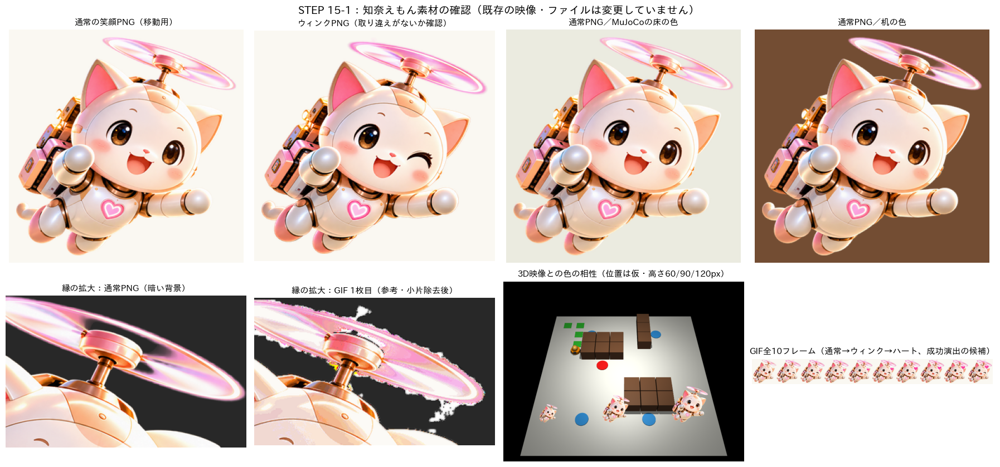


【確認結果】
  ✅ PASS  通常の笑顔PNGが透過付き（RGBA）
  ✅ PASS  ウィンクPNGが透過付き（RGBA）
  ✅ PASS  通常PNGとウィンクPNGが別のファイル
  ✅ PASS  通常PNGとウィンクPNGの元サイズの差が2%以内（同じシリーズの素材）
  ✅ PASS  GIFが複数フレーム
  ✅ PASS  GIFの全フレームが同じサイズ
  ✅ PASS  除去後もハートが残っている（最終フレームのピンク画素がウィンク直後の1.5倍以上）
  ✅ PASS  作業フォルダ直下の既存ファイルは変更なし
  ✅ PASS  作業フォルダ直下に新しいファイルを作っていない
  ✅ PASS  STEP 14-4の物理走行映像（nav_frames）は変更なし
結果: 10 / 10 PASS
※ 通常PNGとウィンクPNGの取り違えは自動判定できないため、図の上段2枚で目視確認してください。

保存（新規フォルダ内のみ）: chinaemon_chara/chara_normal.png, chara_wink.png, step15_1_asset_check.png


In [98]:
# STEP 15-1：知奈えもんキャラクター素材の読み込みと品質確認（既存の変数・ファイルは変更しない）

import os
import inspect
import hashlib
import numpy as np
from PIL import Image, ImageFilter
from scipy import ndimage
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib   # STEP 9-6Aで導入済み
except ImportError:
    pass

# ---------------------------------------------------------------
# 1. 保存先は新規フォルダのみ（既存の動画・画像・CSVとは分ける）
#    素材の取り違えを防ぐため、種類ごとに別フォルダへ1ファイルずつ置く
# ---------------------------------------------------------------
CHARA_DIR = "chinaemon_chara"
SRC_SLOTS = {
    "normal": ("通常の笑顔PNG（移動用）", ".png"),
    "wink":   ("ウィンクPNG", ".png"),
    "gif":    ("ウィンク→ハートのGIF", ".gif"),
}
for _slot in SRC_SLOTS:
    os.makedirs(os.path.join(CHARA_DIR, "src", _slot), exist_ok=True)

# 既存ファイルの更新時刻を記録（このSTEPで変更していないことを最後に確認）
_files_before = {f: os.path.getmtime(f) for f in os.listdir(".") if os.path.isfile(f)}
# 既存の物理走行映像（STEP 14-4）の内容を記録（読むだけ・変更しないことを確認）
_has_nav = "nav_frames" in globals() and len(nav_frames) > 0
_nav_hash_before = hashlib.md5(np.stack(nav_frames).tobytes()).hexdigest() if _has_nav else None

# ---------------------------------------------------------------
# 2. 素材のアップロード（そのフォルダが空の場合のみ。1種類ずつ選択）
# ---------------------------------------------------------------
def slot_dir(slot):
    return os.path.join(CHARA_DIR, "src", slot)

def slot_files(slot):
    ext = SRC_SLOTS[slot][1]
    return sorted(f for f in os.listdir(slot_dir(slot)) if f.lower().endswith(ext))

_missing = [s for s in SRC_SLOTS if not slot_files(s)]
if _missing:
    from google.colab import files
    if "target_dir" not in inspect.signature(files.upload).parameters:
        # 作業フォルダ直下へのアップロードは既存ファイルを上書きするおそれがあるため行わない
        raise RuntimeError("左の「ファイル」パネルで次のフォルダに1ファイルずつ直接アップロードし、"
                           "このセルを再実行してください：\n"
                           + "\n".join(f"  {slot_dir(s)}  ← {SRC_SLOTS[s][0]}" for s in _missing))
    for _slot in _missing:
        print(f"▶ {SRC_SLOTS[_slot][0]} を1つだけ選択してください。")
        files.upload(target_dir=slot_dir(_slot))

for _slot in SRC_SLOTS:
    if len(slot_files(_slot)) != 1:
        raise RuntimeError(f"{slot_dir(_slot)} に {SRC_SLOTS[_slot][0]} を1つだけ置いてください"
                           f"（現在: {slot_files(_slot)}）")
normal_path = os.path.join(slot_dir("normal"), slot_files("normal")[0])
wink_path = os.path.join(slot_dir("wink"), slot_files("wink")[0])
gif_path = os.path.join(slot_dir("gif"), slot_files("gif")[0])

def md5_of(path):
    with open(path, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()

# ---------------------------------------------------------------
# 3. 素材の読み込み
# ---------------------------------------------------------------
_normal_png, _wink_png = Image.open(normal_path), Image.open(wink_path)
normal_mode, wink_mode = _normal_png.mode, _wink_png.mode
normal_raw, wink_raw = _normal_png.convert("RGBA"), _wink_png.convert("RGBA")

_gif = Image.open(gif_path)
gif_n = getattr(_gif, "n_frames", 1)
gif_durations, gif_raw_frames = [], []
for _k in range(gif_n):
    _gif.seek(_k)
    gif_durations.append(int(_gif.info.get("duration", 100)))
    gif_raw_frames.append(_gif.convert("RGBA"))

# ---------------------------------------------------------------
# 4. 透過のクリーンアップと余白の切り抜き
#    PNG：ごく薄い残りかす（alpha<16）を透明化するだけ（縁の滑らかな透過はそのまま残す）
#    GIF：透過が「透明か不透明か」の2段階のみで、背景除去の白い小片が縁に残っているため、
#         小さな孤立片の除去 → 細いはみ出しの除去 → 縁を1px分ぼかす（成功演出の候補素材）
# ---------------------------------------------------------------
ALPHA_FLOOR = 16
GIF_OPENING = 2          # はみ出し除去の強さ（画素）
MIN_PART_RATIO = 0.01    # 最大の部品の1%未満の孤立片は除去（ハートは残る大きさ）

def clean_alpha(img):
    a = np.array(img)
    faint = (a[..., 3] > 0) & (a[..., 3] < ALPHA_FLOOR)
    a[faint, 3] = 0
    return Image.fromarray(a), int(faint.sum())

def keep_large_parts(mask):
    lab, n = ndimage.label(mask)
    if n == 0:
        return mask
    sizes = ndimage.sum(mask, lab, range(1, n + 1))
    keep = [i + 1 for i, s in enumerate(sizes) if s >= sizes.max() * MIN_PART_RATIO]
    return np.isin(lab, keep)

def clean_gif_frame(img):
    a = np.array(img)
    mask0 = a[..., 3] > 0
    mask = keep_large_parts(mask0)
    mask = ndimage.binary_opening(mask, ndimage.generate_binary_structure(2, 1), iterations=GIF_OPENING)
    mask = keep_large_parts(mask)
    alpha = Image.fromarray((mask * 255).astype(np.uint8)).filter(ImageFilter.GaussianBlur(1.0))
    a[..., 3] = np.array(alpha)
    return Image.fromarray(a), int((mask0 & ~mask).sum())

normal_clean, normal_faint = clean_alpha(normal_raw)
wink_clean, wink_faint = clean_alpha(wink_raw)
normal_sprite = normal_clean.crop(normal_clean.getbbox())   # 移動用（高解像度PNG）
wink_sprite = wink_clean.crop(wink_clean.getbbox())         # 成功演出の候補素材

gif_basic = [clean_alpha(f)[0] for f in gif_raw_frames]
_cleaned = [clean_gif_frame(f) for f in gif_basic]
gif_removed = [r for _, r in _cleaned]
_boxes = [c.getbbox() for c, _ in _cleaned]
gif_box = (min(b[0] for b in _boxes), min(b[1] for b in _boxes),
           max(b[2] for b in _boxes), max(b[3] for b in _boxes))
chara_gif_frames = [c.crop(gif_box) for c, _ in _cleaned]  # 全フレーム共通の切り抜きで位置ずれを防ぐ

normal_sprite.save(os.path.join(CHARA_DIR, "chara_normal.png"))
wink_sprite.save(os.path.join(CHARA_DIR, "chara_wink.png"))

# ---------------------------------------------------------------
# 5. 品質の数値確認
# ---------------------------------------------------------------
def alpha_stats(img):
    a = np.array(img)[..., 3]
    vis = a > 0
    return {"幅×高さ": f"{img.width}×{img.height}",
            "不透明部の割合": f"{(a >= 250).sum() / vis.sum() * 100:.1f}%",
            "半透明の縁の割合": f"{((a > 0) & (a < 250)).sum() / vis.sum() * 100:.1f}%"}

def pink_pixels(img):
    """濃いピンク（ハートの色）の画素数。ハートが除去で消えていないかの目安"""
    a = np.array(img)
    return int(((a[..., 0] > 220) & (a[..., 1] < 120) & (a[..., 2] > 120) & (a[..., 3] > 128)).sum())

_pink = [pink_pixels(f) for f in chara_gif_frames]

print("【STEP 15-1：キャラクター素材の確認】")
print(f"通常の笑顔PNG: {slot_files('normal')[0]}（元の形式 {normal_mode}、元サイズ {normal_raw.width}×{normal_raw.height}）")
print("  切り抜き後", alpha_stats(normal_sprite), f"／薄い残りかすを透明化: {normal_faint:,} 画素")
print(f"ウィンクPNG: {slot_files('wink')[0]}（元の形式 {wink_mode}、元サイズ {wink_raw.width}×{wink_raw.height}）")
print("  切り抜き後", alpha_stats(wink_sprite), f"／薄い残りかすを透明化: {wink_faint:,} 画素")
print(f"GIF: {slot_files('gif')[0]}（{gif_n}フレーム、合計 {sum(gif_durations) / 1000:.2f} 秒）")
print(f"  各フレームの表示時間[ms]: {gif_durations}")
print(f"  縁の白い小片・はみ出しとして除去した画素数（フレームごと）: {gif_removed}")
print(f"  除去後の濃いピンク画素数（ハートの大きさの目安）: {_pink}")

checks_15_1 = [
    ("通常の笑顔PNGが透過付き（RGBA）", normal_mode == "RGBA"),
    ("ウィンクPNGが透過付き（RGBA）", wink_mode == "RGBA"),
    ("通常PNGとウィンクPNGが別のファイル", md5_of(normal_path) != md5_of(wink_path)),
    ("通常PNGとウィンクPNGの元サイズの差が2%以内（同じシリーズの素材）",
     abs(normal_raw.width - wink_raw.width) / wink_raw.width < 0.02
     and abs(normal_raw.height - wink_raw.height) / wink_raw.height < 0.02),
    ("GIFが複数フレーム", gif_n >= 2),
    ("GIFの全フレームが同じサイズ", len({f.size for f in chara_gif_frames}) == 1),
    ("除去後もハートが残っている（最終フレームのピンク画素がウィンク直後の1.5倍以上）",
     gif_n >= 2 and _pink[-1] >= _pink[1] * 1.5),
]

# ---------------------------------------------------------------
# 6. 見た目の確認（取り違えの目視確認・背景色との相性・縁の品質・3D映像との色の相性）
# ---------------------------------------------------------------
BG_VIDEO = (250, 248, 242)   # 提出動画の背景色（STEP 14-13のC_BG）
BG_FLOOR = (235, 235, 224)   # MuJoCoの床の色（rgba 0.92 0.92 0.88）
BG_DESK = (115, 77, 51)      # MuJoCoの机の色（rgba 0.45 0.3 0.2）
BG_DARK = (40, 40, 40)       # 縁の白っぽさ・ギザつきを見つけるための暗い背景

def on_bg(sprite, bg_rgb, height):
    s = sprite.resize((round(sprite.width * height / sprite.height), height), Image.LANCZOS)
    base = Image.new("RGBA", (s.width + 20, s.height + 20), bg_rgb + (255,))
    base.alpha_composite(s, (10, 10))
    return base

def edge_zoom(sprite, bg_rgb, width=600):
    """プロペラ付近（右上）を同じ倍率に揃えて拡大し、縁を確認"""
    s = sprite.resize((width, round(sprite.height * width / sprite.width)), Image.LANCZOS)
    w, h = s.size
    crop = s.crop((int(w * 0.45), 0, w, int(h * 0.35)))
    base = Image.new("RGBA", crop.size, bg_rgb + (255,))
    base.alpha_composite(crop)
    return base

panels = [
    (on_bg(normal_sprite, BG_VIDEO, 300), "通常の笑顔PNG（移動用）"),
    (on_bg(wink_sprite, BG_VIDEO, 300), "ウィンクPNG（取り違えがないか確認）"),
    (on_bg(normal_sprite, BG_FLOOR, 300), "通常PNG／MuJoCoの床の色"),
    (on_bg(normal_sprite, BG_DESK, 300), "通常PNG／机の色"),
    (edge_zoom(normal_sprite, BG_DARK), "縁の拡大：通常PNG（暗い背景）"),
    (edge_zoom(chara_gif_frames[0], BG_DARK), "縁の拡大：GIF 1枚目（参考・小片除去後）"),
]
if _has_nav:
    # 既存フレームのコピーに貼るだけ（位置は仮。正しい位置・大きさはSTEP 15-3で計算）
    _view = Image.fromarray(nav_frames[len(nav_frames) // 2].copy()).convert("RGBA")
    for _hgt, _xpos in [(60, 120), (90, 330), (120, 560)]:
        _s = normal_sprite.resize((round(normal_sprite.width * _hgt / normal_sprite.height), _hgt), Image.LANCZOS)
        _view.alpha_composite(_s, (_xpos, 470 - _hgt))
    panels.append((_view, "3D映像との色の相性（位置は仮・高さ60/90/120px）"))
else:
    panels.append((Image.new("RGBA", (10, 10), BG_VIDEO + (255,)), "nav_frames が無いため省略"))

# GIF全フレームの一覧（縮小サイズを先に決め、キャンバスは余白5px×2＋全フレーム幅で作成）
_tw, _th = chara_gif_frames[0].width // 4, chara_gif_frames[0].height // 4
gif_strip = Image.new("RGBA", (10 + _tw * gif_n, 10 + _th), BG_VIDEO + (255,))
for _k, _f in enumerate(chara_gif_frames):
    gif_strip.alpha_composite(_f.resize((_tw, _th), Image.LANCZOS), (5 + _k * _tw, 5))
panels.append((gif_strip, f"GIF全{gif_n}フレーム（通常→ウィンク→ハート、成功演出の候補）"))

_fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for _ax in axes.flat:
    _ax.axis("off")
for _ax, (_img, _ttl) in zip(axes.flat, panels):
    _ax.imshow(_img)
    _ax.set_title(_ttl, fontsize=11)
plt.suptitle("STEP 15-1：知奈えもん素材の確認（既存の映像・ファイルは変更していません）", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(CHARA_DIR, "step15_1_asset_check.png"), dpi=110)
plt.show()

# ---------------------------------------------------------------
# 7. 既存の映像・ファイルを変更していないことの確認
# ---------------------------------------------------------------
_files_after = {f: os.path.getmtime(f) for f in os.listdir(".") if os.path.isfile(f)}
_changed = [f for f, t in _files_before.items() if _files_after.get(f) != t]
_added_top = [f for f in _files_after if f not in _files_before]

checks_15_1 += [
    ("作業フォルダ直下の既存ファイルは変更なし", not _changed),
    ("作業フォルダ直下に新しいファイルを作っていない", not _added_top),
]
if _has_nav:
    checks_15_1.append(("STEP 14-4の物理走行映像（nav_frames）は変更なし",
                        hashlib.md5(np.stack(nav_frames).tobytes()).hexdigest() == _nav_hash_before))

print("\n【確認結果】")
for _name, _ok in checks_15_1:
    print(f"  {'✅ PASS' if _ok else '❌ FAIL'}  {_name}")
print(f"結果: {sum(_ok for _, _ok in checks_15_1)} / {len(checks_15_1)} PASS")
if not _has_nav:
    print("※ nav_frames が見つかりません（STEP 14-4 未実行）。STEP 15-2の前に14-4までの実行が必要です。")
print("※ 通常PNGとウィンクPNGの取り違えは自動判定できないため、図の上段2枚で目視確認してください。")
print(f"\n保存（新規フォルダ内のみ）: {CHARA_DIR}/chara_normal.png, chara_wink.png, step15_1_asset_check.png")

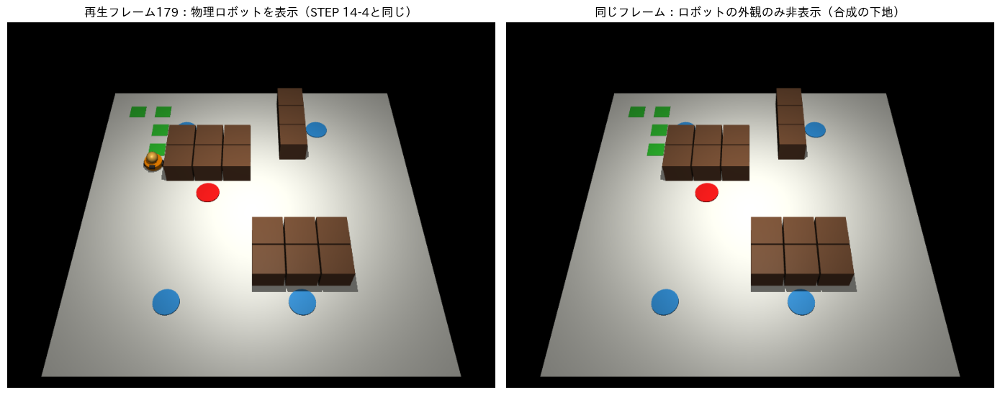

【STEP 15-2：STEP 14-4の物理走行の再生と照合】
AI選定対象の席: (4, 3)／経路: 7マス
記録したフレーム数: 359（1フレーム = 20ステップ × 0.002 秒）
14-4映像との最大画素差（全フレーム中の最大）: 0

【確認結果】
  ✅ PASS  経由点の到達数が一致（14-4: 7／再生: 7）
  ✅ PASS  目標との誤差が一致（14-4: 0.049908 m／再生: 0.049908 m）
  ✅ PASS  机との衝突回数が一致（14-4: 0回／再生: 0回）
  ✅ PASS  フレーム数が一致（14-4: 359／再生: 359）
  ✅ PASS  全フレームが画素単位で完全一致（359/359フレーム）
  ✅ PASS  記録した位置・姿勢だけで映像を再現できる（代表フレーム[0, 179, 358]の最大画素差 [0, 0, 0]）
  ✅ PASS  提出時のノートブックの保存済み出力と一致（7/7・誤差0.050 m・衝突0回・359フレーム）
  ✅ PASS  非表示用の描画グループ2は、ロボット以外の部品で未使用
  ✅ PASS  非表示にしたときロボット部分だけが消える（変化した画素 883）
  ✅ PASS  STEP 14-4の映像（nav_frames）は変更なし
  ✅ PASS  STEP 14-4の走行結果（reached・final_error・collision_events）は変更なし
結果: 11 / 11 PASS

保存（新規フォルダ内のみ）: chinaemon_chara/step15_2_replay_poses.csv, step15_2_replay_check.png


In [99]:
# STEP 15-2：STEP 14-4の物理走行を同条件で再生し、フレームごとの位置・姿勢を記録（既存の結果との完全一致を確認）

import os
import hashlib
import numpy as np
import pandas as pd
import mujoco
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib   # STEP 9-6Aで導入済み
except ImportError:
    pass

# ---------------------------------------------------------------
# 0. 前提の確認（STEP 14-4までを実行済みであること）
# ---------------------------------------------------------------
_need = ["nav_xml", "nav_frames", "ai_safe_route", "grid_to_world", "office_camera",
         "WHEEL_BASE", "WHEEL_RADIUS", "MAX_WHEEL", "REACH_TOL", "TURN_FIRST", "K_V", "K_W",
         "TIME_LIMIT", "steps_per_frame", "reached", "final_error", "collision_events",
         "ai_target_position"]
_missing = [n for n in _need if n not in globals()]
if _missing:
    raise RuntimeError(f"STEP 14-4までを先に実行してください。不足: {_missing}")

CHARA_DIR = globals().get("CHARA_DIR", "chinaemon_chara")   # STEP 15-1と同じ新規フォルダ
os.makedirs(CHARA_DIR, exist_ok=True)

# 既存の結果を記録（このSTEPで変更していないことを最後に確認）
_nav_hash_before = hashlib.md5(np.stack(nav_frames).tobytes()).hexdigest()
_metrics_before = (reached, final_error, collision_events, len(nav_frames))

# ---------------------------------------------------------------
# 1. STEP 14-4と同じモデルを新しく作成（14-4の nav_model / nav_data には触れない）
# ---------------------------------------------------------------
rp_model = mujoco.MjModel.from_xml_string(nav_xml)
rp_data = mujoco.MjData(rp_model)
mujoco.mj_forward(rp_model, rp_data)

rp_robot_body_ids = {rp_model.body(n).id for n in ["chinaemon_base", "left_wheel", "right_wheel"]}

def rp_is_robot_geom(g):
    return rp_model.geom_bodyid[g] in rp_robot_body_ids

def rp_desk_contact_now():
    """STEP 14-4の desk_contact_now と同じ判定"""
    for c in rp_data.contact[:rp_data.ncon]:
        g1, g2 = c.geom1, c.geom2
        if rp_is_robot_geom(g1) != rp_is_robot_geom(g2):
            other = g2 if rp_is_robot_geom(g1) else g1
            if other != 0:          # 0 = 床（STEP 14-4の floor_geom_id）
                return True
    return False

def rp_pose():
    """STEP 14-4の nav_pose と同じ計算（x, y, 向き）"""
    x, y = rp_data.qpos[0], rp_data.qpos[1]
    w, qx, qy, qz = rp_data.qpos[3:7]
    yaw = np.arctan2(2 * (w * qz + qx * qy), 1 - 2 * (qy**2 + qz**2))
    return x, y, yaw

def rp_show_trail(i):
    rp_model.geom_rgba[rp_model.geom(f"nav_trail_{i}").id][3] = 1.0

# ---------------------------------------------------------------
# 2. 再生：STEP 14-4と同じ制御を実行し、描画のたびに
#    ・14-4の映像（nav_frames）と画素単位で比較
#    ・その瞬間の位置・姿勢（qpos全体）と、表示中の緑タイル数を記録
# ---------------------------------------------------------------
rp_renderer = mujoco.Renderer(rp_model, height=600, width=800)
rp_qpos, rp_trail_count, rp_times = [], [], []
rp_frame_diff = []          # フレームごとの、14-4映像との最大画素差
rp_trail_shown = 0

# mj_step は「その時点の姿勢で形状の位置を計算 → 時間を進めて姿勢を更新」の順に処理するため、
# ステップ直後に描画される形状は「ステップ前の姿勢」のもの。映像と一致させるため、ステップ前の姿勢を記録する
def rp_capture(qpos_drawn):
    k = len(rp_qpos)
    rp_renderer.update_scene(rp_data, camera=office_camera)
    img = rp_renderer.render()
    if k < len(nav_frames):
        rp_frame_diff.append(int(np.abs(img.astype(np.int16) - nav_frames[k].astype(np.int16)).max()))
    else:
        rp_frame_diff.append(-1)   # 14-4より多い（不一致）
    rp_qpos.append(qpos_drawn)
    rp_trail_count.append(rp_trail_shown)
    rp_times.append(rp_data.time)

def rp_step(left, right, step_count):
    rp_data.ctrl[:] = [left, right]
    qpos_before = rp_data.qpos.copy()
    mujoco.mj_step(rp_model, rp_data)
    if step_count % steps_per_frame == 0:
        rp_capture(qpos_before)

# 着地（STEP 14-4と同じ250ステップ）
rp_step_count = 0
for _ in range(250):
    rp_step(0, 0, rp_step_count); rp_step_count += 1
rp_show_trail(0); rp_trail_shown = 1

rp_collisions, rp_in_contact, rp_reached = 0, False, 0
# 変数名は既存セル（STEP 14-4）と重ならないよう先頭に _ を付ける（計算内容は14-4と同一）
for _i in range(1, len(ai_safe_route)):
    _gx, _gy = grid_to_world(ai_safe_route[_i])
    while rp_data.time < TIME_LIMIT:
        _x, _y, _yaw = rp_pose()
        _dist = np.hypot(_gx - _x, _gy - _y)
        if _dist < REACH_TOL:
            break
        _herr = (np.arctan2(_gy - _y, _gx - _x) - _yaw + np.pi) % (2 * np.pi) - np.pi
        _v = 0.0 if abs(_herr) > TURN_FIRST else min(K_V * _dist, 0.5)
        _w = K_W * _herr
        _left = np.clip((_v - _w * WHEEL_BASE / 2) / WHEEL_RADIUS, -MAX_WHEEL, MAX_WHEEL)
        _right = np.clip((_v + _w * WHEEL_BASE / 2) / WHEEL_RADIUS, -MAX_WHEEL, MAX_WHEEL)
        rp_step(_left, _right, rp_step_count); rp_step_count += 1
        _touching = rp_desk_contact_now()
        if _touching and not rp_in_contact:
            rp_collisions += 1
        rp_in_contact = _touching
    else:
        break
    rp_reached = _i
    rp_show_trail(_i); rp_trail_shown = _i + 1

# 停止（STEP 14-4と同じ1秒）
for _ in range(int(1.0 / rp_model.opt.timestep)):
    rp_step(0, 0, rp_step_count); rp_step_count += 1

_fx, _fy, _ = rp_pose()
_tx, _ty = grid_to_world(ai_target_position)
rp_final_error = float(np.hypot(_tx - _fx, _ty - _fy))
rp_qpos = np.array(rp_qpos)

# ---------------------------------------------------------------
# 3. 記録した位置・姿勢だけで映像を再現できるかの確認（STEP 15-4の合成で使う方法）
#    物理計算はせず、qposを設定して描画するだけ。代表3フレームで14-4映像と比較
# ---------------------------------------------------------------
_trail_ids = [rp_model.geom(f"nav_trail_{i}").id for i in range(len(ai_safe_route))]

def rp_render_from_record(k, scene_option=None):
    for j, gid in enumerate(_trail_ids):
        rp_model.geom_rgba[gid][3] = 1.0 if j < rp_trail_count[k] else 0.0
    rp_data.qpos[:] = rp_qpos[k]
    rp_data.qvel[:] = 0
    mujoco.mj_forward(rp_model, rp_data)
    if scene_option is None:
        rp_renderer.update_scene(rp_data, camera=office_camera)
    else:
        rp_renderer.update_scene(rp_data, camera=office_camera, scene_option=scene_option)
    return rp_renderer.render()

_n = len(rp_qpos)
_sample = [0, _n // 2, _n - 1]
_restore_diff = [int(np.abs(rp_render_from_record(k).astype(np.int16)
                            - nav_frames[k].astype(np.int16)).max()) for k in _sample]

# ---------------------------------------------------------------
# 4. ロボットの外観だけを非表示にした描画の確認（このSTEP専用のモデルのみ変更）
#    ロボットの部品を描画グループ2に移し、グループ2を描かない設定で描画する
#    ※ 描画グループは見た目だけの設定で、質量・接触判定・物理計算には使われない
# ---------------------------------------------------------------
_robot_geoms = [_g for _g in range(rp_model.ngeom) if rp_is_robot_geom(_g)]
_group2_before = [_g for _g in range(rp_model.ngeom) if rp_model.geom_group[_g] == 2]
for _g in _robot_geoms:
    rp_model.geom_group[_g] = 2
rp_hide_robot = mujoco.MjvOption()
rp_hide_robot.geomgroup[2] = 0

_k_mid = _n // 2
_img_visible = rp_render_from_record(_k_mid)
_img_hidden = rp_render_from_record(_k_mid, rp_hide_robot)
_robot_pixels = int((np.abs(_img_visible.astype(np.int16) - _img_hidden.astype(np.int16)).sum(axis=2) > 30).sum())
_fig, _axes = plt.subplots(1, 2, figsize=(14, 5.5))
_axes[0].imshow(_img_visible); _axes[0].set_title(f"再生フレーム{_k_mid}：物理ロボットを表示（STEP 14-4と同じ）")
_axes[1].imshow(_img_hidden); _axes[1].set_title(f"同じフレーム：ロボットの外観のみ非表示（合成の下地）")
for _ax in _axes:
    _ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(CHARA_DIR, "step15_2_replay_check.png"), dpi=100)
plt.show()

# 位置・姿勢の記録をCSVに保存（新規フォルダ内のみ）
_yaw = [np.arctan2(2 * (q[3] * q[6] + q[4] * q[5]), 1 - 2 * (q[5]**2 + q[6]**2)) for q in rp_qpos]
rp_pose_df = pd.DataFrame({"フレーム": range(_n), "物理時間[s]": np.round(rp_times, 4),
                           "x[m]": rp_qpos[:, 0], "y[m]": rp_qpos[:, 1], "z[m]": rp_qpos[:, 2],
                           "向き[deg]": np.degrees(_yaw), "緑タイル数": rp_trail_count})
rp_pose_df.to_csv(os.path.join(CHARA_DIR, "step15_2_replay_poses.csv"), index=False, encoding="utf-8-sig")

# ---------------------------------------------------------------
# 5. 判定
# ---------------------------------------------------------------
_identical = sum(d == 0 for d in rp_frame_diff)
checks_15_2 = [
    (f"経由点の到達数が一致（14-4: {reached}／再生: {rp_reached}）", rp_reached == reached),
    (f"目標との誤差が一致（14-4: {final_error:.6f} m／再生: {rp_final_error:.6f} m）",
     abs(rp_final_error - final_error) < 1e-9),
    (f"机との衝突回数が一致（14-4: {collision_events}回／再生: {rp_collisions}回）",
     rp_collisions == collision_events),
    (f"フレーム数が一致（14-4: {len(nav_frames)}／再生: {_n}）", _n == len(nav_frames)),
    (f"全フレームが画素単位で完全一致（{_identical}/{_n}フレーム）", _identical == _n == len(nav_frames)),
    (f"記録した位置・姿勢だけで映像を再現できる（代表フレーム{_sample}の最大画素差 {_restore_diff}）",
     all(d == 0 for d in _restore_diff)),
    ("提出時のノートブックの保存済み出力と一致（7/7・誤差0.050 m・衝突0回・359フレーム）",
     (rp_reached, round(rp_final_error, 3), rp_collisions, _n) == (7, 0.050, 0, 359)),
    ("非表示用の描画グループ2は、ロボット以外の部品で未使用", not _group2_before),
    (f"非表示にしたときロボット部分だけが消える（変化した画素 {_robot_pixels}）", 0 < _robot_pixels < 600 * 800 * 0.05),
    ("STEP 14-4の映像（nav_frames）は変更なし",
     hashlib.md5(np.stack(nav_frames).tobytes()).hexdigest() == _nav_hash_before),
    ("STEP 14-4の走行結果（reached・final_error・collision_events）は変更なし",
     (reached, final_error, collision_events, len(nav_frames)) == _metrics_before),
]

print("【STEP 15-2：STEP 14-4の物理走行の再生と照合】")
print(f"AI選定対象の席: {ai_target_position}／経路: {len(ai_safe_route) - 1}マス")
print(f"記録したフレーム数: {_n}（1フレーム = {steps_per_frame}ステップ × {rp_model.opt.timestep} 秒）")
print(f"14-4映像との最大画素差（全フレーム中の最大）: {max(rp_frame_diff)}")
print("\n【確認結果】")
for _name, _ok in checks_15_2:
    print(f"  {'✅ PASS' if _ok else '❌ FAIL'}  {_name}")
print(f"結果: {sum(_ok for _, _ok in checks_15_2)} / {len(checks_15_2)} PASS")
print(f"\n保存（新規フォルダ内のみ）: {CHARA_DIR}/step15_2_replay_poses.csv, step15_2_replay_check.png")

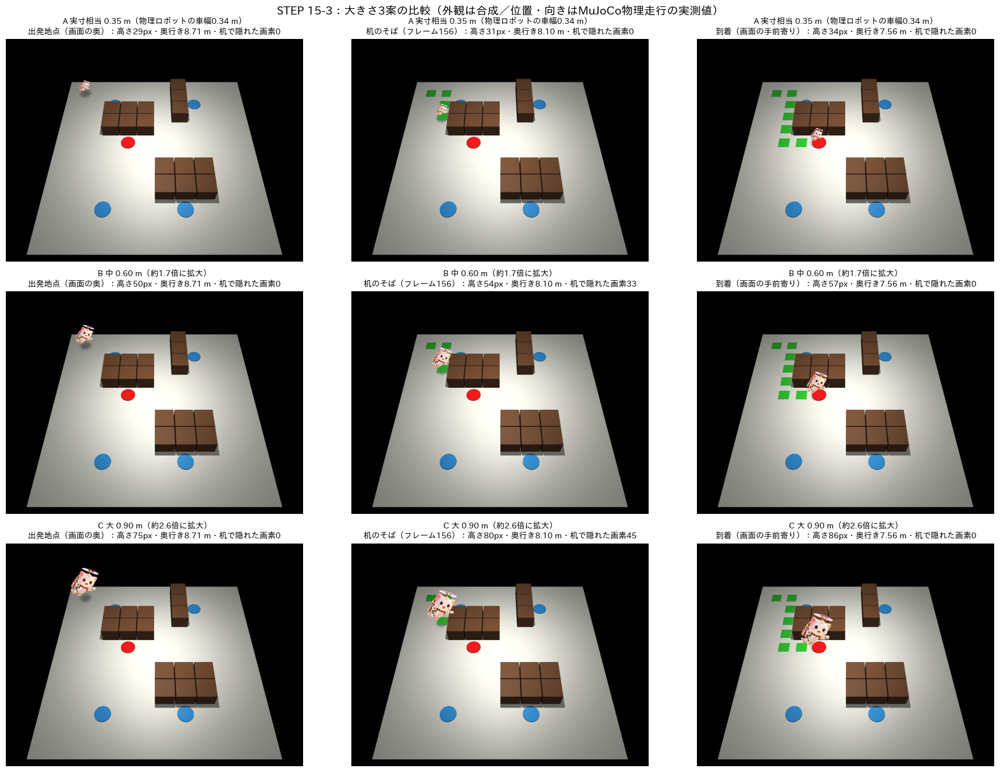

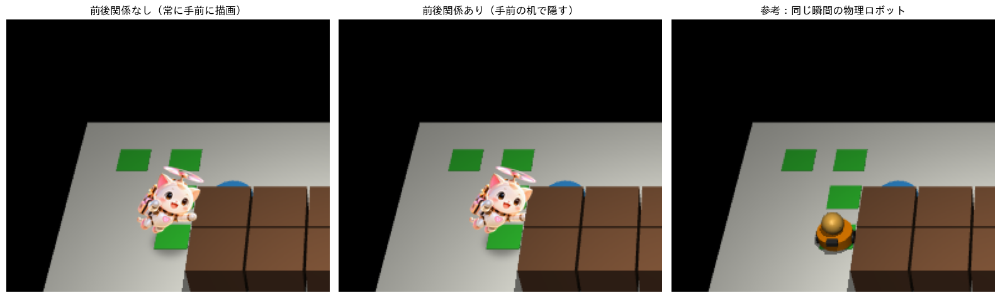

【STEP 15-3：画面座標の計算と見た目の比較】
カメラ位置: [ 2.25  -6.552  6.144]／視線方向: [ 0.     0.574 -0.819]
前後関係が最も強く出る場面: フレーム156（中サイズで机に隠れる画素 33）

【大きさ3案の画面上の高さ（px）】
  A 実寸相当 0.35 m（物理ロボットの車幅0.34 m）: 出発地点（画面の奥） 29px／机のそば（フレーム156） 31px／到着（画面の手前寄り） 34px
  B 中 0.60 m（約1.7倍に拡大）: 出発地点（画面の奥） 50px／机のそば（フレーム156） 54px／到着（画面の手前寄り） 57px
  C 大 0.90 m（約2.6倍に拡大）: 出発地点（画面の奥） 75px／机のそば（フレーム156） 80px／到着（画面の手前寄り） 86px

【確認結果】
  ✅ PASS  目的地マーカー：計算位置と映像の誤差 0.34 px（1.5 px以内）
  ✅ PASS  走行中のロボット追従：計算位置と映像上の重心の誤差 平均 3.09 px・最大 4.04 px（60フレーム、最大6 px以内）
  ✅ PASS  深度画像の単位確認：机の上面で計算値との差 0.001 m（0.01 m以内）
  ✅ PASS  机の部品を識別（15個、STEP 14-1の机のマス数 15）
  ✅ PASS  遠近感：出発地点（奥）より到着地点（手前）の方が大きく表示される
  ✅ PASS  前後関係：到着地点（机より手前の席）では、どの大きさでも机に隠れない
結果: 6 / 6 PASS

保存（新規フォルダ内のみ）: chinaemon_chara/step15_3_size_compare.png, step15_3_occlusion_check.png


In [100]:
# STEP 15-3：カメラ設定から画面座標を計算し、知奈えもんの大きさ・遠近感・机との前後関係を静止画で比較

import os
import numpy as np
import mujoco
from PIL import Image, ImageDraw, ImageFilter
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib   # STEP 9-6Aで導入済み
except ImportError:
    pass

# ---------------------------------------------------------------
# 0. 前提の確認（STEP 15-1・15-2を実行済みであること）
# ---------------------------------------------------------------
_need = ["normal_sprite", "rp_model", "rp_data", "rp_renderer", "rp_qpos", "rp_trail_count",
         "rp_render_from_record", "rp_hide_robot", "nav_frames", "ai_target_position",
         "grid_to_world", "CHARA_DIR"]
_missing = [n for n in _need if n not in globals()]
if _missing:
    raise RuntimeError(f"STEP 15-1・15-2を先に実行してください。不足: {_missing}")

VIEW_W, VIEW_H = 800, 600          # STEP 14-4の映像サイズ
_n = len(rp_qpos)

# ---------------------------------------------------------------
# 1. カメラ設定の取得（STEP 14-1の office_camera を、MuJoCoが実際に描画に使った値で取得）
#    MuJoCoは左右2眼分のカメラ情報を持つため、2眼の中央を使う（片目だと約3.5px横にずれる）
# ---------------------------------------------------------------
rp_render_from_record(0)
_c0, _c1 = rp_renderer.scene.camera[0], rp_renderer.scene.camera[1]
chara_cam = {
    "pos": (np.array(_c0.pos) + np.array(_c1.pos)) / 2,
    "forward": np.array(_c0.forward),
    "up": np.array(_c0.up),
    "near": float(_c0.frustum_near),
    "top": float(_c0.frustum_top),
    "bottom": float(_c0.frustum_bottom),
}
chara_cam["right"] = np.cross(chara_cam["forward"], chara_cam["up"])

def chara_project(p):
    """3D座標[m] → 画面座標(u, v)[px] と カメラからの奥行き[m]"""
    c = chara_cam
    d = np.asarray(p, dtype=float) - c["pos"]
    xc, yc, zc = d @ c["right"], d @ c["up"], d @ c["forward"]
    half_w = (c["top"] - c["bottom"]) / 2 * VIEW_W / VIEW_H
    u = (xc / zc * c["near"] + half_w) / (2 * half_w) * VIEW_W
    v = (c["top"] - yc / zc * c["near"]) / (c["top"] - c["bottom"]) * VIEW_H
    return u, v, zc

# ---------------------------------------------------------------
# 2. 計算した画面座標の精度確認
#    ① 赤い目的地マーカーの中心：計算位置と、映像上の赤い画素の重心を比較
#    ② 物理ロボット：60フレームについて、計算位置と、映像上のロボット領域の重心を比較
#       （①は精密な検証、②は走行中ずっと追従できているかの確認。色の検出は検証にのみ使用）
# ---------------------------------------------------------------
_tx, _ty = grid_to_world(ai_target_position)
_img0 = rp_render_from_record(0, rp_hide_robot)
_red = (_img0[..., 0] > 180) & (_img0[..., 1] < 70) & (_img0[..., 2] < 70)
_ry, _rx = np.nonzero(_red)
_mu, _mv, _ = chara_project([_tx, _ty, 0.02])               # マーカー上面の中心
marker_err = float(np.hypot(_rx.mean() + 0.5 - _mu, _ry.mean() + 0.5 - _mv))

def robot_center_world(k):
    """記録した姿勢での、物理ロボット（胴体＋頭）の見た目の中心付近"""
    q = rp_qpos[k]
    return np.array([q[0], q[1], q[2] + 0.08])

_track_err = []
for _k in range(0, _n, 6):
    _vis = rp_render_from_record(_k).astype(np.int16)
    _hid = rp_render_from_record(_k, rp_hide_robot).astype(np.int16)
    _m = np.abs(_vis - _hid).sum(axis=2) > 30
    _ys, _xs = np.nonzero(_m)
    _u, _v, _ = chara_project(robot_center_world(_k))
    _track_err.append(float(np.hypot(_xs.mean() + 0.5 - _u, _ys.mean() + 0.5 - _v)))

# ---------------------------------------------------------------
# 3. 机との前後関係：深度画像と部品ID画像で「キャラクターより手前にある机」を判定
# ---------------------------------------------------------------
_desk_ids = {g for g in range(rp_model.ngeom)
             if rp_model.geom_type[g] == mujoco.mjtGeom.mjGEOM_BOX
             and rp_model.geom_size[g][2] > 0.1
             and not rp_model.geom(g).name.startswith("nav_trail")}
_FLOOR_ID = 0

def render_layers(k):
    """合成の下地（ロボット非表示）・深度[m]・部品IDを、同じフレームについて取得"""
    base = rp_render_from_record(k, rp_hide_robot)
    rp_renderer.enable_depth_rendering()
    depth = rp_renderer.render().copy()
    rp_renderer.disable_depth_rendering()
    rp_renderer.enable_segmentation_rendering()
    seg = rp_renderer.render()[..., 0].copy()
    rp_renderer.disable_segmentation_rendering()
    return base, depth, seg

# 深度画像の単位確認：机の上面中心で、計算した奥行きと深度画像の値を比較
_b, _d, _s = render_layers(0)
_g = sorted(_desk_ids)[0]
_pu, _pv, _pz = chara_project(rp_data.geom_xpos[_g] + np.array([0, 0, rp_model.geom_size[_g][2]]))
depth_err = float(abs(_d[int(_pv), int(_pu)] - _pz))

# ---------------------------------------------------------------
# 4. 合成関数（STEP 15-4でも使用）
#    ・キャラクターはカメラに正対した板として、ロボットの位置に配置（大きさは奥行きに応じて変化）
#    ・床に影（床の画素にだけ描く）
#    ・机がキャラクターより手前にある画素は、キャラクターを描かない（前後関係）
# ---------------------------------------------------------------
CHARA_FLOAT = 0.10        # 床からキャラクター下端までの高さ[m]（少し浮いて飛んでいる表現）
SHADOW_RADIUS = 0.17      # 影の半径[m]（物理ロボットの最大半径 0.17 m に合わせる）

_Z_SAMPLES = np.linspace(-0.5, 4.0, 451)

def chara_row_depth(x, y):
    """ロボット位置(x, y)の垂直線について、画面の各行に映る点の奥行き[m]（行数ぶんの配列）"""
    uvz = np.array([chara_project([x, y, z]) for z in _Z_SAMPLES])
    v, z = uvz[:, 1], uvz[:, 2]
    order = np.argsort(v)
    return np.interp(np.arange(VIEW_H) + 0.5, v[order], z[order])

def composite_chara(k, height_m, sprite=None, occlusion=True, bob_m=0.0, flip=False):
    sprite = normal_sprite if sprite is None else sprite
    base, depth, seg = render_layers(k)
    q = rp_qpos[k]
    x, y = q[0], q[1]
    out = Image.fromarray(base).convert("RGBA")

    # 影：床面上の円を画面に投影した楕円（床の画素にだけ描く）
    ang = np.linspace(0, 2 * np.pi, 48, endpoint=False)
    poly = [chara_project([x + SHADOW_RADIUS * np.cos(a), y + SHADOW_RADIUS * np.sin(a), 0.002])[:2] for a in ang]
    sh = Image.new("L", (VIEW_W, VIEW_H), 0)
    ImageDraw.Draw(sh).polygon(poly, fill=90)
    sh = np.array(sh.filter(ImageFilter.GaussianBlur(3))) * (seg == _FLOOR_ID)
    shadow = Image.new("RGBA", (VIEW_W, VIEW_H), (0, 0, 0, 0))
    shadow.putalpha(Image.fromarray(sh.astype(np.uint8)))
    out.alpha_composite(shadow)

    # キャラクター：下端中央を (x, y, 浮き高さ) に置き、カメラの上方向に height_m の大きさ
    bottom = np.array([x, y, CHARA_FLOAT + bob_m])
    bu, bv, bz = chara_project(bottom)
    tu, tv, _ = chara_project(bottom + chara_cam["up"] * height_m)
    h_px = max(2, int(round(bv - tv)))
    w_px = max(2, int(round(sprite.width * h_px / sprite.height)))
    spr = sprite.transpose(Image.FLIP_LEFT_RIGHT) if flip else sprite
    spr = spr.resize((w_px, h_px), Image.LANCZOS)
    left, top = int(round(bu - w_px / 2)), int(round(bv - h_px))
    layer = Image.new("RGBA", (VIEW_W, VIEW_H), (0, 0, 0, 0))
    layer.alpha_composite(spr, (max(left, 0), max(top, 0)),
                          (max(-left, 0), max(-top, 0)))
    occluded = 0
    if occlusion:
        # キャラクターは「ロボットの位置に立つ垂直な物体」として奥行きを計算する。
        # 画面の各行について、ロボット位置の垂直線上でその行に映る点の奥行きを求め、
        # それより手前にある机の画素だけでキャラクターを隠す
        #（カメラは斜め上から見下ろしているため、板全体を同じ奥行きとすると、手前にいるのに
        #  奥の机の天板で隠れてしまう。これを防ぐ）
        a = np.array(layer)
        in_front = np.isin(seg, list(_desk_ids)) & (depth < chara_row_depth(x, y)[:, None] - 0.02)
        occluded = int(((a[..., 3] > 0) & in_front).sum())
        a[..., 3] = np.where(in_front, 0, a[..., 3])
        layer = Image.fromarray(a)
    out.alpha_composite(layer)
    return np.array(out.convert("RGB")), {"h_px": h_px, "w_px": w_px, "depth": bz, "occluded_px": occluded}

# ---------------------------------------------------------------
# 5. 大きさ3案 × 代表3場面 の比較静止画
# ---------------------------------------------------------------
SIZE_OPTIONS = [
    (0.35, "A 実寸相当 0.35 m（物理ロボットの車幅0.34 m）"),
    (0.60, "B 中 0.60 m（約1.7倍に拡大）"),
    (0.90, "C 大 0.90 m（約2.6倍に拡大）"),
]
# 机の手前・奥で前後関係が最も強く出る場面を自動で探す（中サイズで、隠れる画素が最大のフレーム）
_occ = [(composite_chara(k, 0.60)[1]["occluded_px"], k) for k in range(0, _n, 6)]
_k_occ = max(_occ)[1]
SCENES = [(0, "出発地点（画面の奥）"), (_k_occ, f"机のそば（フレーム{_k_occ}）"), (_n - 1, "到着（画面の手前寄り）")]

_fig, _axes = plt.subplots(len(SIZE_OPTIONS), len(SCENES), figsize=(18, 13.5))
size_info = {}
for _r, (_hm, _label) in enumerate(SIZE_OPTIONS):
    for _c, (_k, _sname) in enumerate(SCENES):
        _img, _info = composite_chara(_k, _hm)
        size_info[(_hm, _k)] = _info
        _axes[_r, _c].imshow(_img)
        _axes[_r, _c].set_title(f"{_label}\n{_sname}：高さ{_info['h_px']}px・奥行き{_info['depth']:.2f} m・机で隠れた画素{_info['occluded_px']}",
                                fontsize=10)
        _axes[_r, _c].axis("off")
plt.suptitle("STEP 15-3：大きさ3案の比較（外観は合成／位置・向きはMuJoCo物理走行の実測値）", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(CHARA_DIR, "step15_3_size_compare.png"), dpi=90)
plt.show()

# 前後関係の効果：同じ場面で「前後関係あり／なし」を拡大比較（中サイズ）
_img_on, _ = composite_chara(_k_occ, 0.60, occlusion=True)
_img_off, _ = composite_chara(_k_occ, 0.60, occlusion=False)
_u, _v, _ = chara_project(robot_center_world(_k_occ))
_x0, _y0 = int(np.clip(_u - 130, 0, VIEW_W - 260)), int(np.clip(_v - 170, 0, VIEW_H - 220))
_fig2, _axes2 = plt.subplots(1, 3, figsize=(16, 5))
_axes2[0].imshow(_img_off[_y0:_y0 + 220, _x0:_x0 + 260]); _axes2[0].set_title("前後関係なし（常に手前に描画）")
_axes2[1].imshow(_img_on[_y0:_y0 + 220, _x0:_x0 + 260]); _axes2[1].set_title("前後関係あり（手前の机で隠す）")
_vis = rp_render_from_record(_k_occ)
_axes2[2].imshow(_vis[_y0:_y0 + 220, _x0:_x0 + 260]); _axes2[2].set_title("参考：同じ瞬間の物理ロボット")
for _ax in _axes2:
    _ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(CHARA_DIR, "step15_3_occlusion_check.png"), dpi=100)
plt.show()

# ---------------------------------------------------------------
# 6. 判定
# ---------------------------------------------------------------
checks_15_3 = [
    (f"目的地マーカー：計算位置と映像の誤差 {marker_err:.2f} px（1.5 px以内）", marker_err <= 1.5),
    (f"走行中のロボット追従：計算位置と映像上の重心の誤差 平均 {np.mean(_track_err):.2f} px・最大 {np.max(_track_err):.2f} px"
     f"（{len(_track_err)}フレーム、最大6 px以内）", np.max(_track_err) <= 6.0),
    (f"深度画像の単位確認：机の上面で計算値との差 {depth_err:.3f} m（0.01 m以内）", depth_err <= 0.01),
    (f"机の部品を識別（{len(_desk_ids)}個、STEP 14-1の机のマス数 {int(support_office.sum())}）",
     len(_desk_ids) == int(support_office.sum())),
    ("遠近感：出発地点（奥）より到着地点（手前）の方が大きく表示される",
     size_info[(0.60, _n - 1)]["h_px"] > size_info[(0.60, 0)]["h_px"]),
    ("前後関係：到着地点（机より手前の席）では、どの大きさでも机に隠れない",
     all(size_info[(hm, _n - 1)]["occluded_px"] == 0 for hm, _ in SIZE_OPTIONS)),
]
print("【STEP 15-3：画面座標の計算と見た目の比較】")
print(f"カメラ位置: {np.round(chara_cam['pos'], 3)}／視線方向: {np.round(chara_cam['forward'], 3)}")
print(f"前後関係が最も強く出る場面: フレーム{_k_occ}（中サイズで机に隠れる画素 {max(_occ)[0]}）")
print("\n【大きさ3案の画面上の高さ（px）】")
for _hm, _label in SIZE_OPTIONS:
    print(f"  {_label}: " + "／".join(f"{sn} {size_info[(_hm, kk)]['h_px']}px" for kk, sn in SCENES))
print("\n【確認結果】")
for _name, _ok in checks_15_3:
    print(f"  {'✅ PASS' if _ok else '❌ FAIL'}  {_name}")
print(f"結果: {sum(_ok for _, _ok in checks_15_3)} / {len(checks_15_3)} PASS")
print(f"\n保存（新規フォルダ内のみ）: {CHARA_DIR}/step15_3_size_compare.png, step15_3_occlusion_check.png")

保存: chinaemon_chara/proto_fixedcam_C_10s.mp4（240フレーム、10.0秒）
保存: chinaemon_chara/proto_followcam_A_10s.mp4（240フレーム、10.0秒）


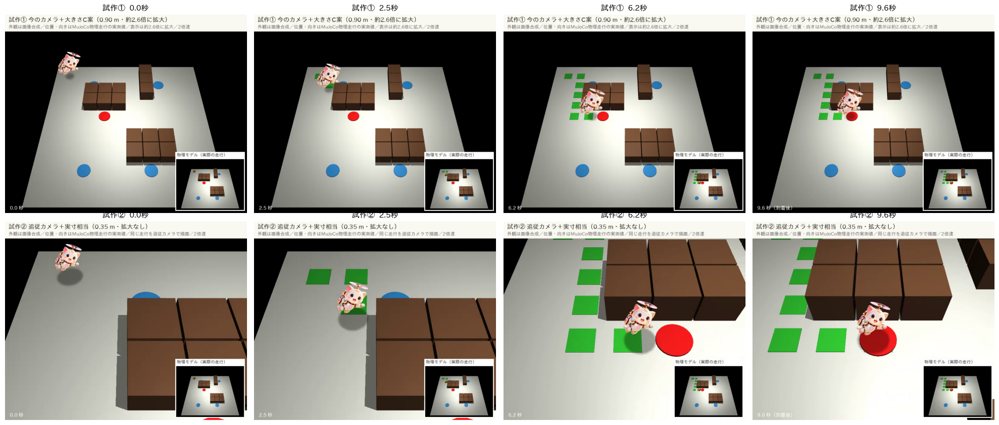


【確認結果】
  ✅ PASS  試作① 長さ 240フレーム＝10.0秒（10秒）
  ✅ PASS  試作① 1フレームあたりの移動量 最大 3.8 px（瞬間移動なし：15 px以内）
  ✅ PASS  試作① キャラクターの高さ 75〜86 px
  ✅ PASS  試作① 全フレームでキャラクターが画面内に描かれている（最小 100%）
  ✅ PASS  試作① 左右の向きの切り替え 0回（ちらつきなし：4回以内）
  ✅ PASS  試作② 長さ 240フレーム＝10.0秒（10秒）
  ✅ PASS  試作② 1フレームあたりの移動量 最大 12.8 px（瞬間移動なし：15 px以内）
  ✅ PASS  試作② キャラクターの高さ 88〜118 px
  ✅ PASS  試作② 全フレームでキャラクターが画面内に描かれている（最小 100%）
  ✅ PASS  試作② 左右の向きの切り替え 0回（ちらつきなし：4回以内）
  ✅ PASS  STEP 14-4の映像（nav_frames）は変更なし
  ✅ PASS  作業フォルダ直下の既存ファイル（既存動画を含む）は変更なし
  ✅ PASS  STEP 14-1の office_camera は変更なし（追従カメラは別に作成）
結果: 13 / 13 PASS

試作① 今のカメラ＋大きさC案（0.90 m・約2.6倍に拡大）



試作② 追従カメラ＋実寸相当（0.35 m・拡大なし）


In [101]:
# STEP 15-4：10秒の試作映像を2本作成（①今のカメラ＋大きさC案 ②追従カメラ＋実寸相当）※成功演出は含めない

import os
import hashlib
import numpy as np
import mujoco
import mediapy as media
from PIL import Image, ImageDraw, ImageFilter, ImageFont
import matplotlib.pyplot as plt
from IPython.display import Video, display
try:
    import japanize_matplotlib   # STEP 9-6Aで導入済み
except ImportError:
    japanize_matplotlib = None

# ---------------------------------------------------------------
# 0. 前提の確認（STEP 15-1〜15-3を実行済みであること）
# ---------------------------------------------------------------
_need = ["normal_sprite", "rp_model", "rp_data", "rp_renderer", "rp_qpos", "rp_trail_count",
         "rp_hide_robot", "nav_frames", "office_camera", "CHARA_DIR", "_desk_ids",
         "CHARA_FLOAT", "SHADOW_RADIUS", "ai_safe_route"]
_missing = [n for n in _need if n not in globals()]
if _missing:
    raise RuntimeError(f"STEP 15-1〜15-3を先に実行してください。不足: {_missing}")

_nav_hash_before = hashlib.md5(np.stack(nav_frames).tobytes()).hexdigest()
_office_cam_before = (tuple(office_camera.lookat), office_camera.distance, office_camera.elevation, office_camera.azimuth)
_files_before = {f: os.path.getmtime(f) for f in os.listdir(".") if os.path.isfile(f)}

VIEW_W, VIEW_H = 800, 600
PROTO_FPS = 24
_n = len(rp_qpos)

# 10秒の構成：走行を2倍速で7.5秒（180フレーム）＋到着後の静止2.5秒（60フレーム）
DRIVE_IDX = list(range(0, _n, 2))[:180]
PROTO_IDX = DRIVE_IDX + [_n - 1] * (240 - len(DRIVE_IDX))

# ---------------------------------------------------------------
# 1. カメラごとの描画・座標計算（STEP 15-3の方法を、任意のカメラで使えるようにしたもの）
# ---------------------------------------------------------------
_trail_ids = [rp_model.geom(f"nav_trail_{i}").id for i in range(len(ai_safe_route))]

def proto_set_state(k):
    """記録した姿勢と緑タイルの状態を再現（物理計算はしない）"""
    for j, gid in enumerate(_trail_ids):
        rp_model.geom_rgba[gid][3] = 1.0 if j < rp_trail_count[k] else 0.0
    rp_data.qpos[:] = rp_qpos[k]
    rp_data.qvel[:] = 0
    mujoco.mj_forward(rp_model, rp_data)

def proto_layers(cam):
    """ロボット非表示の下地・深度・部品IDと、そのとき実際に使われたカメラ値"""
    rp_renderer.update_scene(rp_data, camera=cam, scene_option=rp_hide_robot)
    c0, c1 = rp_renderer.scene.camera[0], rp_renderer.scene.camera[1]
    cp = {"pos": (np.array(c0.pos) + np.array(c1.pos)) / 2, "forward": np.array(c0.forward),
          "up": np.array(c0.up), "near": float(c0.frustum_near),
          "top": float(c0.frustum_top), "bottom": float(c0.frustum_bottom)}
    cp["right"] = np.cross(cp["forward"], cp["up"])
    base = rp_renderer.render().copy()
    rp_renderer.enable_depth_rendering()
    depth = rp_renderer.render().copy()
    rp_renderer.disable_depth_rendering()
    rp_renderer.enable_segmentation_rendering()
    seg = rp_renderer.render()[..., 0].copy()
    rp_renderer.disable_segmentation_rendering()
    return base, depth, seg, cp

def proto_project(p, cp):
    d = np.asarray(p, dtype=float) - cp["pos"]
    xc, yc, zc = d @ cp["right"], d @ cp["up"], d @ cp["forward"]
    half_w = (cp["top"] - cp["bottom"]) / 2 * VIEW_W / VIEW_H
    u = (xc / zc * cp["near"] + half_w) / (2 * half_w) * VIEW_W
    v = (cp["top"] - yc / zc * cp["near"]) / (cp["top"] - cp["bottom"]) * VIEW_H
    return u, v, zc

_ZS = np.linspace(-0.5, 4.0, 451)

def proto_row_depth(x, y, cp):
    uvz = np.array([proto_project([x, y, z], cp) for z in _ZS])
    order = np.argsort(uvz[:, 1])
    return np.interp(np.arange(VIEW_H) + 0.5, uvz[order, 1], uvz[order, 2])

def proto_composite(k, cam, height_m, bob_m=0.0, flip=False):
    """STEP 15-3の composite_chara と同じ合成（影・前後関係つき）を、指定カメラで行う"""
    proto_set_state(k)
    base, depth, seg, cp = proto_layers(cam)
    x, y = rp_qpos[k][0], rp_qpos[k][1]
    out = Image.fromarray(base).convert("RGBA")
    # 影（床・緑タイル・席マーカーなど床面の画素に描く。机と背景には描かない）
    #  ※STEP 15-3では床の画素だけに描いていたため、緑タイルの上で影が欠けていた。ここで改善
    ang = np.linspace(0, 2 * np.pi, 48, endpoint=False)
    poly = [proto_project([x + SHADOW_RADIUS * np.cos(a), y + SHADOW_RADIUS * np.sin(a), 0.002], cp)[:2] for a in ang]
    sh = Image.new("L", (VIEW_W, VIEW_H), 0)
    ImageDraw.Draw(sh).polygon(poly, fill=90)
    floor_like = (seg >= 0) & ~np.isin(seg, list(_desk_ids))
    sh = np.array(sh.filter(ImageFilter.GaussianBlur(3))) * floor_like
    shadow = Image.new("RGBA", (VIEW_W, VIEW_H), (0, 0, 0, 0))
    shadow.putalpha(Image.fromarray(sh.astype(np.uint8)))
    out.alpha_composite(shadow)
    # キャラクター
    bottom = np.array([x, y, CHARA_FLOAT + bob_m])
    bu, bv, bz = proto_project(bottom, cp)
    _, tv, _ = proto_project(bottom + cp["up"] * height_m, cp)
    h_px = max(2, int(round(bv - tv)))
    w_px = max(2, int(round(normal_sprite.width * h_px / normal_sprite.height)))
    spr = normal_sprite.transpose(Image.FLIP_LEFT_RIGHT) if flip else normal_sprite
    spr = spr.resize((w_px, h_px), Image.LANCZOS)
    left, top = int(round(bu - w_px / 2)), int(round(bv - h_px))
    layer = Image.new("RGBA", (VIEW_W, VIEW_H), (0, 0, 0, 0))
    if left < VIEW_W and top < VIEW_H and left + w_px > 0 and top + h_px > 0:
        layer.alpha_composite(spr, (max(left, 0), max(top, 0)), (max(-left, 0), max(-top, 0)))
    a = np.array(layer)
    drawn_before = int((a[..., 3] > 0).sum())
    sprite_px = int((np.array(spr)[..., 3] > 0).sum())   # キャラクター自体の画素数（透明部分を除く）
    in_front = np.isin(seg, list(_desk_ids)) & (depth < proto_row_depth(x, y, cp)[:, None] - 0.02)
    a[..., 3] = np.where(in_front, 0, a[..., 3])
    out.alpha_composite(Image.fromarray(a))
    visible = drawn_before / max(1, sprite_px)         # 画面の外にはみ出さず描けた割合
    return np.array(out.convert("RGB")), {"u": bu, "v": bv, "h_px": h_px, "visible": visible}

# ---------------------------------------------------------------
# 2. 試作の設定
# ---------------------------------------------------------------
follow_camera = mujoco.MjvCamera()             # 追従カメラ（STEP 14-1の office_camera は変更しない）
follow_camera.distance = 2.2
follow_camera.elevation = office_camera.elevation
follow_camera.azimuth = office_camera.azimuth
FOLLOW_SMOOTH = 0.12                           # 追従の滑らかさ（小さいほどゆっくり追う）
# 床の外（黒い背景）が大きく映らないよう、注視点を床の内側に制限
FOLLOW_X = (0.75, 3.75)
FOLLOW_Y = (-3.9, -1.0)

PROTOS = [
    {"name": "proto_fixedcam_C", "title": "試作① 今のカメラ＋大きさC案（0.90 m・約2.6倍に拡大）",
     "camera": office_camera, "height": 0.90, "follow": False,
     "note": "外観は画像合成／位置・向きはMuJoCo物理走行の実測値／表示は約2.6倍に拡大／2倍速"},
    {"name": "proto_followcam_A", "title": "試作② 追従カメラ＋実寸相当（0.35 m・拡大なし）",
     "camera": follow_camera, "height": 0.35, "follow": True,
     "note": "外観は画像合成／位置・向きはMuJoCo物理走行の実測値／同じ走行を追従カメラで描画／2倍速"},
]
BOB_AMP, BOB_PERIOD = 0.015, 1.0                # 浮遊感の上下動（振幅[m]・周期[s]）

def _font(size):
    if japanize_matplotlib is not None:
        path = os.path.join(os.path.dirname(japanize_matplotlib.__file__), "fonts", "ipaexg.ttf")
        if os.path.exists(path):
            return ImageFont.truetype(path, size)
    return ImageFont.load_default()

BAND = 56
INSET_W, INSET_H = 224, 168

def proto_frame(view, k, cfg, j):
    """上部に注記、右下に物理モデルの小窓（STEP 14-4の元映像）をつけた1フレーム"""
    img = Image.new("RGB", (VIEW_W, VIEW_H + BAND), (250, 248, 242))
    img.paste(Image.fromarray(view), (0, BAND))
    d = ImageDraw.Draw(img)
    d.text((12, 6), cfg["title"], font=_font(20), fill=(40, 40, 40))
    d.text((12, 32), cfg["note"], font=_font(15), fill=(110, 110, 110))
    inset = Image.fromarray(nav_frames[k]).resize((INSET_W, INSET_H), Image.LANCZOS)
    x0, y0 = VIEW_W - INSET_W - 10, BAND + VIEW_H - INSET_H - 10
    d.rectangle([x0 - 3, y0 - 24, x0 + INSET_W + 2, y0 + INSET_H + 2], fill=(255, 255, 255))
    d.text((x0 + 2, y0 - 22), "物理モデル（実際の走行）", font=_font(14), fill=(60, 60, 60))
    img.paste(inset, (x0, y0))
    t = j / PROTO_FPS
    d.text((12, BAND + VIEW_H - 26), f"{t:4.1f} 秒" + ("（到着後）" if j >= len(DRIVE_IDX) else ""),
           font=_font(16), fill=(255, 255, 255))
    return np.asarray(img)

# ---------------------------------------------------------------
# 3. 書き出し（新規フォルダ内に保存。既存の動画は変更しない）
# ---------------------------------------------------------------
def proto_write(cfg):
    """1本分の試作映像を書き出し、フレームごとの記録を返す（変数を関数内に閉じ込め、既存の変数と衝突させない）"""
    path = os.path.join(CHARA_DIR, cfg["name"] + "_10s.mp4")
    log = {"u": [], "v": [], "h_px": [], "visible": [], "flip": []}
    look = np.array([rp_qpos[0][0], rp_qpos[0][1], 0.2])
    facing_left, prev_u = False, None
    with media.VideoWriter(path, shape=(VIEW_H + BAND, VIEW_W), fps=PROTO_FPS) as writer:
        for j, k in enumerate(PROTO_IDX):
            if cfg["follow"]:
                target = np.array([np.clip(rp_qpos[k][0], *FOLLOW_X), np.clip(rp_qpos[k][1], *FOLLOW_Y), 0.2])
                look = look + FOLLOW_SMOOTH * (target - look) if j else target
                follow_camera.lookat[:] = look
            bob = BOB_AMP * np.sin(2 * np.pi * j / PROTO_FPS / BOB_PERIOD)
            view, info = proto_composite(k, cfg["camera"], cfg["height"], bob_m=bob, flip=facing_left)
            # 進行方向（画面上の左右）に合わせて、次のフレームから向きを反転。小さな揺れでは切り替えない
            #（追従カメラでは画面上の位置がカメラの動きでも変わるため、地面上の移動方向で判定する）
            if prev_u is not None and j < len(DRIVE_IDX):
                du = (rp_qpos[k][0] - prev_u) * 100 if cfg["follow"] else info["u"] - prev_u
                if du < -1.5:
                    facing_left = True
                elif du > 1.5:
                    facing_left = False
            prev_u = rp_qpos[k][0] if cfg["follow"] else info["u"]
            for key in ("u", "v", "h_px", "visible"):
                log[key].append(info[key])
            log["flip"].append(facing_left)
            writer.add_image(proto_frame(view, k, cfg, j))
    print(f"保存: {path}（{len(PROTO_IDX)}フレーム、{len(PROTO_IDX) / PROTO_FPS:.1f}秒）")
    return log

proto_logs = {_cfg["name"]: proto_write(_cfg) for _cfg in PROTOS}

# ---------------------------------------------------------------
# 4. 確認用の静止画（2本 × 4時点）
# ---------------------------------------------------------------
_times = [0, 60, 150, 230]
_fig, _axes = plt.subplots(2, 4, figsize=(20, 8.5))
for _r, _cfg in enumerate(PROTOS):
    _frames = media.read_video(os.path.join(CHARA_DIR, _cfg["name"] + "_10s.mp4"))
    for _c, _j in enumerate(_times):
        _axes[_r, _c].imshow(_frames[_j]); _axes[_r, _c].axis("off")
        _axes[_r, _c].set_title(f"{_cfg['title'][:3]}  {_j / PROTO_FPS:.1f}秒", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(CHARA_DIR, "step15_4_proto_sheet.png"), dpi=80)
plt.show()

# ---------------------------------------------------------------
# 5. 判定
# ---------------------------------------------------------------
checks_15_4 = []
for _cfg in PROTOS:
    _lg = proto_logs[_cfg["name"]]
    _nm = _cfg["title"][:3]
    _jumps = np.hypot(np.diff(_lg["u"]), np.diff(_lg["v"]))
    _flips = int(np.sum(np.diff(np.array(_lg["flip"], dtype=int)) != 0))
    checks_15_4 += [
        (f"{_nm} 長さ {len(_lg['u'])}フレーム＝{len(_lg['u']) / PROTO_FPS:.1f}秒（10秒）", len(_lg["u"]) == 240),
        (f"{_nm} 1フレームあたりの移動量 最大 {_jumps.max():.1f} px（瞬間移動なし：15 px以内）", _jumps.max() <= 15),
        (f"{_nm} キャラクターの高さ {min(_lg['h_px'])}〜{max(_lg['h_px'])} px", min(_lg["h_px"]) >= 20),
        (f"{_nm} 全フレームでキャラクターが画面内に描かれている（最小 {min(_lg['visible']) * 100:.0f}%）",
         min(_lg["visible"]) >= 0.9),
        (f"{_nm} 左右の向きの切り替え {_flips}回（ちらつきなし：4回以内）", _flips <= 4),
    ]
_files_after = {f: os.path.getmtime(f) for f in os.listdir(".") if os.path.isfile(f)}
checks_15_4 += [
    ("STEP 14-4の映像（nav_frames）は変更なし",
     hashlib.md5(np.stack(nav_frames).tobytes()).hexdigest() == _nav_hash_before),
    ("作業フォルダ直下の既存ファイル（既存動画を含む）は変更なし",
     all(_files_after.get(f) == t for f, t in _files_before.items())),
    ("STEP 14-1の office_camera は変更なし（追従カメラは別に作成）",
     (tuple(office_camera.lookat), office_camera.distance, office_camera.elevation, office_camera.azimuth)
     == _office_cam_before),
]
print("\n【確認結果】")
for _name, _ok in checks_15_4:
    print(f"  {'✅ PASS' if _ok else '❌ FAIL'}  {_name}")
print(f"結果: {sum(_ok for _, _ok in checks_15_4)} / {len(checks_15_4)} PASS")

for _cfg in PROTOS:
    print("\n" + _cfg["title"])
    display(Video(os.path.join(CHARA_DIR, _cfg["name"] + "_10s.mp4"), embed=True, width=720))

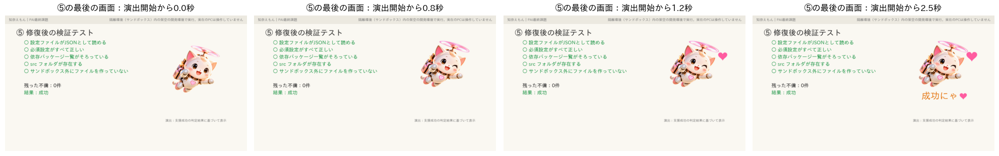

【STEP 15-5：提出動画用の成功判定】
  ○ 動画の⑤で表示する結果が、STEP 14-12の最新の結果と同一（古い結果を使わない）
  ○ STEP 14-12の時点で物理到着を確認済み
  ○ いまの実測値でも物理到着の条件を満たす（STEP 14-7の判定を再計算）
  ○ 本人の判断が「承認」
  ○ 隔離環境で作業を実行済み
  ○ 作業結果が「成功」
  ○ 残った不備が0件
  ○ 修復後の検証テストがすべて合格
  ○ 支援対象がAI選定対象と一致
→ 成功演出を表示する: True

【確認結果】
  ✅ PASS  T1 承認拒否 → 演出を表示しない（満たさない条件: 本人の判断が「承認」）
  ✅ PASS  T2 未到着（STEP 14-12の時点） → 演出を表示しない（満たさない条件: STEP 14-12の時点で物理到着を確認済み）
  ✅ PASS  T3 未到着（いまの実測値で再判定するとNG） → 演出を表示しない（満たさない条件: いまの実測値でも物理到着の条件を満たす（STEP 14-7の判定を再計算））
  ✅ PASS  T4 支援失敗（修復が不完全） → 演出を表示しない（満たさない条件: 作業結果が「成功」）
  ✅ PASS  T5 支援失敗（検証テストに不合格） → 演出を表示しない（満たさない条件: 修復後の検証テストがすべて合格）
  ✅ PASS  T6 未実施（ボタン操作なし） → 演出を表示しない（満たさない条件: 動画の⑤で表示する結果が、STEP 14-12の最新の結果と同一（古い結果を使わない））
  ✅ PASS  T7 代行対象外の困りごと（提案のみ） → 演出を表示しない（満たさない条件: 隔離環境で作業を実行済み）
  ✅ PASS  T8 支援対象がAI選定対象と不一致 → 演出を表示しない（満たさない条件: 支援対象がAI選定対象と一致）
  ✅ PASS  T9 古い結果を表示しようとしている（14-12やり直し後、14-13未再実行） → 演出を表示しない（満たさない条件: 動画の⑤で表示する結果が、STEP 14-12の最新の結果と同一（古い結果を使わない））
  ✅ PASS  判定がFalseのとき、⑤の映像はSTEP 14-13と画素単位で同一（演出を一切描かない）

In [102]:
# STEP 15-5：支援成功の判定（提出動画用）と成功演出の部品、誤発火しないことの自動テスト（動画はまだ作らない）

import os
import copy
import json
import numpy as np
from datetime import datetime
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib   # STEP 9-6Aで導入済み
except ImportError:
    pass

# ---------------------------------------------------------------
# 0. 前提の確認（STEP 14-13・15-1〜15-4を実行済みであること）
# ---------------------------------------------------------------
_need = ["dialog_state", "setup_log", "check_physics_arrival", "ai_target_name", "scene_setup",
         "canvas", "F", "FW", "FH", "FFPS", "SAFE_BOTTOM", "C_ORANGE", "C_GRAY",
         "normal_sprite", "wink_sprite", "CHARA_DIR"]
_missing = [n for n in _need if n not in globals()]
if _missing:
    raise RuntimeError(f"STEP 14-13とSTEP 15-1〜15-4を先に実行してください。不足: {_missing}")

_dialog_before = copy.deepcopy(dialog_state)    # 本番の状態を変えていないことを最後に確認

# ---------------------------------------------------------------
# 1. 動画用の成功判定（STEP 14-12の結果を読むだけ。2D用の ai_flow_state は使わない）
#    shown_log：提出動画の⑤で表示する結果（STEP 14-13の setup_log）
#    arrived_now：STEP 14-7の到着判定を、いまの実測値で再計算した結果
# ---------------------------------------------------------------
def judge_video_success(state, shown_log, arrived_now):
    res = state.get("result")
    conds = [
        ("動画の⑤で表示する結果が、STEP 14-12の最新の結果と同一（古い結果を使わない）",
         res is not None and res is shown_log),
        ("STEP 14-12の時点で物理到着を確認済み", state.get("physics_arrived") is True),
        ("いまの実測値でも物理到着の条件を満たす（STEP 14-7の判定を再計算）", arrived_now is True),
        ("本人の判断が「承認」", state.get("decision") == "承認"),
        ("隔離環境で作業を実行済み", isinstance(res, dict) and res.get("executed") is True),
        ("作業結果が「成功」", isinstance(res, dict) and res.get("status") == "成功"),
        ("残った不備が0件", isinstance(res, dict) and res.get("remaining_issues") == []),
        ("修復後の検証テストがすべて合格",
         isinstance(res, dict) and bool(res.get("tests")) and all(res["tests"].values())),
        ("支援対象がAI選定対象と一致", state.get("target") == ai_target_name),
    ]
    return all(ok for _, ok in conds), conds

# ---------------------------------------------------------------
# 2. 成功演出の部品（PNG 2枚で「通常顔→ウィンク」、ハートは図形で描く）
#    ※ 動画用フォント（IPAexゴシック）には絵文字の💖が無いため、文字は「成功にゃ」、ハートは図形
# ---------------------------------------------------------------
EFFECT_SEC = 3.0                       # 演出の長さ（⑤の最後の画面の終盤3秒）
EFFECT_BOX = (800, 110, 1220, SAFE_BOTTOM - 10)   # 演出を描く領域（右側の空き領域・下部140pxは使わない）
HEART_PINK = (255, 92, 160)

def draw_heart(layer, cx, cy, size, fill=HEART_PINK):
    """ハート形（媒介変数表示の曲線）を、4倍の解像度で描いてから縮小し、縁を滑らかにして重ねる"""
    size = max(4, int(size))
    big = Image.new("RGBA", (size * 4, size * 4), (0, 0, 0, 0))
    t = np.linspace(0, 2 * np.pi, 120)
    x = 16 * np.sin(t) ** 3
    y = 13 * np.cos(t) - 5 * np.cos(2 * t) - 2 * np.cos(3 * t) - np.cos(4 * t)
    s = size * 4 / 34
    ImageDraw.Draw(big).polygon(list(zip(size * 2 + x * s, size * 2 - y * s)), fill=fill)
    small = big.resize((size, size), Image.LANCZOS)
    layer.alpha_composite(small, (int(cx - size / 2), int(cy - size / 2)))

def _sprite_at(sprite, height):
    return sprite.resize((round(sprite.width * height / sprite.height), height), Image.LANCZOS)

_SPR_H = 250
_spr_normal = _sprite_at(normal_sprite, _SPR_H)
_spr_wink = _sprite_at(wink_sprite, _SPR_H)

def effect_overlay(t):
    """演出開始から t 秒後の重ね絵（透明背景のRGBA、動画1フレーム分の大きさ）"""
    layer = Image.new("RGBA", (FW, FH), (0, 0, 0, 0))
    d = ImageDraw.Draw(layer)
    x0, y0, x1, y1 = EFFECT_BOX
    cx = (x0 + x1) // 2
    # ① 0〜0.6秒：通常顔が下から少し浮き上がって登場 ② 0.6秒〜：ウィンク
    rise = int(30 * max(0.0, 1 - t / 0.6))
    spr = _spr_normal if t < 0.6 else _spr_wink
    layer.alpha_composite(spr, (cx - spr.width // 2, y0 + 20 + rise))
    # ③ 1.0秒〜：ウィンクした目の右横にハートがふくらむ（プロペラに重ならない位置）
    if t >= 1.0:
        grow = min(1.0, (t - 1.0) / 0.35)
        size = int(60 * (0.4 + 0.6 * grow) * (1 + 0.15 * np.sin(grow * np.pi)))
        draw_heart(layer, cx + 150, y0 + 105, size)
    # ④ 1.4秒〜：「成功にゃ」＋ハート
    if t >= 1.4:
        d.text((cx - 20, y0 + 20 + _SPR_H + 45), "成功にゃ", font=F(48), fill=C_ORANGE, anchor="mm")
        draw_heart(layer, cx + 105, y0 + 20 + _SPR_H + 47, 40)
    # 演出であることの注記（常に表示）
    d.text((cx, y1 - 12), "演出：支援成功の判定結果に基づいて表示", font=F(17), fill=C_GRAY, anchor="mm")
    return layer

def scene_setup_with_effect(eligible):
    """STEP 14-13の scene_setup をそのまま使い、成功判定がTrueのときだけ最後の3秒に演出を重ねる"""
    def scene(sec):
        frames = list(scene_setup(sec))
        n_eff = int(round(EFFECT_SEC * FFPS))
        start = len(frames) - n_eff
        for i, fr in enumerate(frames):
            if eligible and i >= start:
                img = Image.fromarray(fr).convert("RGBA")
                img.alpha_composite(effect_overlay((i - start) / FFPS))
                yield np.asarray(img.convert("RGB"))
            else:
                yield fr
    scene.__name__ = "scene_setup"          # 下部140pxの自動確認（STEP 14-13）で同じ扱いにする
    return scene

# ---------------------------------------------------------------
# 3. 本番の判定（今回の実行結果）
# ---------------------------------------------------------------
_arrived_now, _ = check_physics_arrival()
video_success, video_success_conds = judge_video_success(dialog_state, setup_log, _arrived_now)

# ---------------------------------------------------------------
# 4. 誤発火テスト（本番の状態はコピーして使い、変更しない）
# ---------------------------------------------------------------
def _case(**changes):
    st = copy.deepcopy(dialog_state)
    res = copy.deepcopy(dialog_state.get("result"))
    for k, v in changes.items():
        if k.startswith("res_"):
            if res is None:
                res = {}
            res[k[4:]] = v
        else:
            st[k] = v
    st["result"] = res
    return st, res

_cases = []
_st, _res = _case(decision="拒否", res_executed=False, res_status="拒否のため実行しない")
_cases.append(("T1 承認拒否", _st, _res, True))
_st, _res = _case(physics_arrived=False, res_executed=False, res_status="未実行（物理到着または承認なし）")
_cases.append(("T2 未到着（STEP 14-12の時点）", _st, _res, True))
_st, _res = _case()
_cases.append(("T3 未到着（いまの実測値で再判定するとNG）", _st, _res, False))
_st, _res = _case(res_status="失敗", res_remaining_issues=["requirements.txt がない"])
_cases.append(("T4 支援失敗（修復が不完全）", _st, _res, True))
_st, _res = _case(res_tests={"設定ファイルがJSONとして読める": True, "必須設定がすべて正しい": False})
_cases.append(("T5 支援失敗（検証テストに不合格）", _st, _res, True))
_st = copy.deepcopy(dialog_state); _st.update({"answer": None, "decision": None, "result": None})
_cases.append(("T6 未実施（ボタン操作なし）", _st, None, True))
_st, _res = _case(answer="テストが失敗する", res_executed=False, res_status="代行対象外（提案のみ）")
_cases.append(("T7 代行対象外の困りごと（提案のみ）", _st, _res, True))
_st, _res = _case(target="別の担当者")
_cases.append(("T8 支援対象がAI選定対象と不一致", _st, _res, True))

test_rows_15_5 = []
for name, st, res, arrived in _cases:
    ok, conds = judge_video_success(st, res, arrived)
    failed = [c for c, v in conds if not v]
    test_rows_15_5.append((name, ok, failed))
# T9：内容は同じでも、STEP 14-12をやり直した後の新しい結果（＝別の結果）なら発火しない
_newer = copy.deepcopy(setup_log)
_st = copy.deepcopy(dialog_state); _st["result"] = _newer
_ok9, _c9 = judge_video_success(_st, setup_log, True)
test_rows_15_5.append(("T9 古い結果を表示しようとしている（14-12やり直し後、14-13未再実行）",
                       _ok9, [c for c, v in _c9 if not v]))

# 演出の重ね合わせ自体のテスト：判定がFalseなら、⑤の映像は STEP 14-13 と画素単位で同一
_orig = list(scene_setup(15))
_no_eff = list(scene_setup_with_effect(False)(15))
_with_eff = list(scene_setup_with_effect(True)(15))
_n_eff = int(round(EFFECT_SEC * FFPS))
_same_when_false = len(_orig) == len(_no_eff) and all(np.array_equal(a, b) for a, b in zip(_orig, _no_eff))
_changed = [i for i, (a, b) in enumerate(zip(_orig, _with_eff)) if not np.array_equal(a, b)]
_only_last = bool(_changed) and min(_changed) >= len(_orig) - _n_eff
_diff_rows = np.nonzero(np.any(np.stack([np.any(a != b, axis=2) for a, b in zip(_orig[-_n_eff:], _with_eff[-_n_eff:])]), axis=0))
_inside_box = (_diff_rows[1].min() >= EFFECT_BOX[0] and _diff_rows[1].max() <= EFFECT_BOX[2]
               and _diff_rows[0].min() >= EFFECT_BOX[1] and _diff_rows[0].max() < SAFE_BOTTOM)

# ---------------------------------------------------------------
# 5. 演出の見た目の確認（本番の判定がTrueのときだけ演出つき）
# ---------------------------------------------------------------
_shots = [0.0, 0.8, 1.2, 2.5]
_fig, _axes = plt.subplots(1, len(_shots), figsize=(20, 3.6))
_last = Image.fromarray(_orig[-1]).convert("RGBA")
for _ax, _t in zip(_axes, _shots):
    _im = _last.copy()
    if video_success:
        _im.alpha_composite(effect_overlay(_t))
    _ax.imshow(_im.convert("RGB")); _ax.axis("off")
    _ax.set_title(f"⑤の最後の画面：演出開始から{_t:.1f}秒" + ("" if video_success else "（判定Falseのため演出なし）"))
plt.tight_layout()
plt.savefig(os.path.join(CHARA_DIR, "step15_5_effect_preview.png"), dpi=80)
plt.show()

# 判定結果の記録（後から根拠を確認できるように）
_record = {"判定日時": datetime.now().isoformat(timespec="seconds"),
           "判定の対象": "STEP 14-12 dialog_state（提出動画用）",
           "成功演出を表示する": bool(video_success),
           "条件": {c: bool(v) for c, v in video_success_conds}}
with open(os.path.join(CHARA_DIR, "step15_5_success_judgement.json"), "w", encoding="utf-8") as fh:
    json.dump(_record, fh, ensure_ascii=False, indent=2)

# ---------------------------------------------------------------
# 6. 判定結果の表示
# ---------------------------------------------------------------
print("【STEP 15-5：提出動画用の成功判定】")
for c, v in video_success_conds:
    print(f"  {'○' if v else '×'} {c}")
print(f"→ 成功演出を表示する: {video_success}")

checks_15_5 = [(f"{name} → 演出を表示しない（満たさない条件: {failed[0] if failed else 'なし'}）", ok is False)
               for name, ok, failed in test_rows_15_5]
checks_15_5 += [
    ("判定がFalseのとき、⑤の映像はSTEP 14-13と画素単位で同一（演出を一切描かない）", _same_when_false),
    (f"判定がTrueのとき、変わるのは⑤の最後の{EFFECT_SEC:.0f}秒だけ", _only_last),
    ("演出は右側の決めた領域の中だけに描かれ、下部140px（再生バー・字幕の領域）を使わない", _inside_box),
    ("テストの前後で本番の状態（dialog_state）は変更なし", dialog_state == _dialog_before),
]
print("\n【確認結果】")
for _name, _ok in checks_15_5:
    print(f"  {'✅ PASS' if _ok else '❌ FAIL'}  {_name}")
print(f"結果: {sum(_ok for _, _ok in checks_15_5)} / {len(checks_15_5)} PASS")
print(f"\n保存（新規フォルダ内のみ）: {CHARA_DIR}/step15_5_effect_preview.png, step15_5_success_judgement.json")

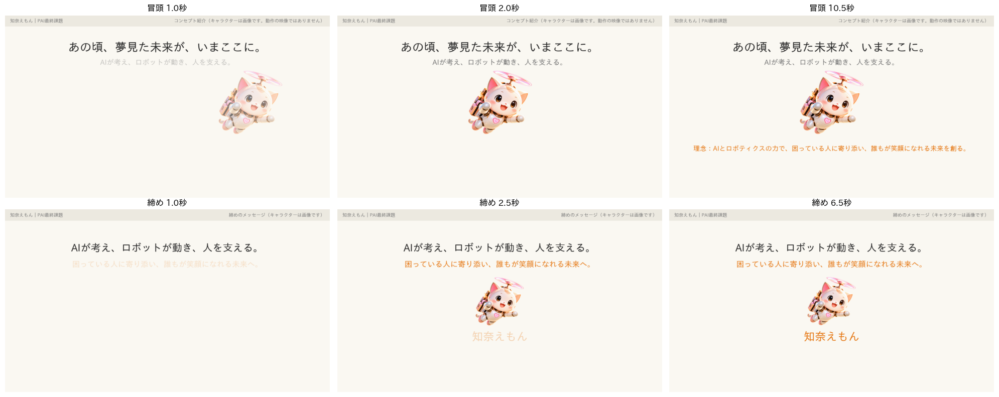

【STEP 15-6：冒頭と締めのシーン】
  冒頭 11秒：あの頃、夢見た未来が、いまここに。／AIが考え、ロボットが動き、人を支える。／理念
  締め 7秒：AIが考え、ロボットが動き、人を支える。／知奈えもん

【確認結果】
  ✅ PASS  冒頭 264フレーム＝11.0秒
  ✅ PASS  締め 168フレーム＝7.0秒
  ✅ PASS  冒頭：下部140px（再生バー・字幕の領域）に文字・画像なし（STEP 14-13と同じ確認方法）
  ✅ PASS  締め：下部140pxに文字・画像なし
  ✅ PASS  冒頭のナレーション 72文字＝6.5文字/秒（7.0以内）
  ✅ PASS  締めのナレーション 44文字＝6.3文字/秒（7.0以内）
結果: 6 / 6 PASS

保存（新規フォルダ内のみ）: chinaemon_chara/step15_6_opening_closing.png


In [103]:
# STEP 15-6：提出動画v2の冒頭（コンセプト・理念・キャラクター登場）と締めのシーンを作成し、静止画で確認（動画はまだ作らない）

import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib   # STEP 9-6Aで導入済み
except ImportError:
    pass

# ---------------------------------------------------------------
# 0. 前提の確認（STEP 14-13・15-1を実行済みであること）
# ---------------------------------------------------------------
_need = ["canvas", "F", "FW", "FH", "FFPS", "SAFE_BOTTOM", "C_ORANGE", "C_INK", "C_GRAY",
         "bottom_band_has_text", "normal_sprite", "CHARA_DIR"]
_missing = [n for n in _need if n not in globals()]
if _missing:
    raise RuntimeError(f"STEP 14-13とSTEP 15-1を先に実行してください。不足: {_missing}")

# PPTX（知奈えもん研究開発構想）と同じ言葉・理念
CONCEPT_CATCH = "あの頃、夢見た未来が、いまここに。"
CONCEPT_SUB = "AIが考え、ロボットが動き、人を支える。"
PHILOSOPHY = "AIとロボティクスの力で、困っている人に寄り添い、誰もが笑顔になれる未来を創る。"
NOTE_CONCEPT = "コンセプト紹介（キャラクターは画像です。動作の映像ではありません）"

def _ease(t):
    t = min(max(t, 0.0), 1.0)
    return 1 - (1 - t) ** 3

def _fade_text(img, xy, text, size, color, alpha, anchor="mm"):
    """文字をフェードインさせて描く（alpha: 0〜1）"""
    if alpha <= 0:
        return
    layer = Image.new("RGBA", img.size, (0, 0, 0, 0))
    from PIL import ImageDraw
    ImageDraw.Draw(layer).text(xy, text, font=F(size), fill=color + (int(255 * min(alpha, 1.0)),), anchor=anchor)
    img.alpha_composite(layer)

_OPEN_H = 250
_open_sprite = normal_sprite.resize((round(normal_sprite.width * _OPEN_H / normal_sprite.height), _OPEN_H),
                                    Image.LANCZOS)

def scene_opening(sec):
    """冒頭：キャッチコピー → 知奈えもん登場 → 理念"""
    n = int(round(sec * FFPS))
    for i in range(n):
        t = i / FFPS
        base, _ = canvas(NOTE_CONCEPT)
        img = base.convert("RGBA")
        _fade_text(img, (FW // 2, 125), CONCEPT_CATCH, 46, C_INK, t / 1.0)
        _fade_text(img, (FW // 2, 185), CONCEPT_SUB, 28, C_GRAY, (t - 0.6) / 1.0)
        # 知奈えもんが右から飛んできて中央に止まる（0.8〜2.2秒）
        p = _ease((t - 0.8) / 1.4)
        if p > 0:
            x = int(FW // 2 - _open_sprite.width // 2 + (1 - p) * 520)
            y = int(225 + 6 * np.sin(2 * np.pi * t / 1.2))       # 浮遊感（小さな上下動）
            spr = _open_sprite.copy()
            spr.putalpha(Image.fromarray((np.array(spr)[..., 3] * min(1.0, p * 1.5)).astype(np.uint8)))
            img.alpha_composite(spr, (x, y))
        _fade_text(img, (FW // 2, 525), "理念：" + PHILOSOPHY, 26, C_ORANGE, (t - 2.6) / 1.0)
        yield np.asarray(img.convert("RGB"))

_CLOSE_H = 190
_close_sprite = normal_sprite.resize((round(normal_sprite.width * _CLOSE_H / normal_sprite.height), _CLOSE_H),
                                     Image.LANCZOS)

def scene_closing(sec):
    """締め：理念をもう一度示し、知奈えもんで終える"""
    n = int(round(sec * FFPS))
    for i in range(n):
        t = i / FFPS
        base, _ = canvas("締めのメッセージ（キャラクターは画像です）")
        img = base.convert("RGBA")
        _fade_text(img, (FW // 2, 150), CONCEPT_SUB, 40, C_INK, t / 1.0)
        _fade_text(img, (FW // 2, 215), "困っている人に寄り添い、誰もが笑顔になれる未来へ。", 30, C_ORANGE, (t - 0.8) / 1.0)
        p = _ease((t - 1.4) / 1.0)
        if p > 0:
            spr = _close_sprite.copy()
            spr.putalpha(Image.fromarray((np.array(spr)[..., 3] * p).astype(np.uint8)))
            img.alpha_composite(spr, (FW // 2 - spr.width // 2, int(265 + 6 * np.sin(2 * np.pi * t / 1.2))))
        _fade_text(img, (FW // 2, 500), "知奈えもん", 44, C_ORANGE, (t - 2.2) / 1.0)
        yield np.asarray(img.convert("RGB"))

# ナレーション（TTS原稿・字幕に使用。1秒あたり7文字以内に収まる長さにする）
OPENING_SEC, CLOSING_SEC = 11, 7
OPENING_TEXT = ("あの頃、夢見た未来が、いまここに。"
                "AIとロボティクスの力で、困っている人に寄り添い、誰もが笑顔になれる未来を創る。"
                "それが、知奈えもんの理念です。")
CLOSING_TEXT = "AIが考え、ロボットが動き、人を支える。困っている人のもとへ駆けつける未来を、ここから。"

# ---------------------------------------------------------------
# 1. 静止画で確認（各シーン3時点）
# ---------------------------------------------------------------
_open_frames = list(scene_opening(OPENING_SEC))
_close_frames = list(scene_closing(CLOSING_SEC))
_fig, _axes = plt.subplots(2, 3, figsize=(20, 8))
for _ax, _t in zip(_axes[0], [1.0, 2.0, OPENING_SEC - 0.5]):
    _ax.imshow(_open_frames[int(_t * FFPS)]); _ax.axis("off"); _ax.set_title(f"冒頭 {_t:.1f}秒")
for _ax, _t in zip(_axes[1], [1.0, 2.5, CLOSING_SEC - 0.5]):
    _ax.imshow(_close_frames[int(_t * FFPS)]); _ax.axis("off"); _ax.set_title(f"締め {_t:.1f}秒")
plt.tight_layout()
plt.savefig(os.path.join(CHARA_DIR, "step15_6_opening_closing.png"), dpi=80)
plt.show()

# ---------------------------------------------------------------
# 2. 判定
# ---------------------------------------------------------------
def _band_ok(frames, name):
    return not any(bottom_band_has_text(f, name) for f in frames[::FFPS])

checks_15_6 = [
    (f"冒頭 {len(_open_frames)}フレーム＝{len(_open_frames) / FFPS:.1f}秒", len(_open_frames) == OPENING_SEC * FFPS),
    (f"締め {len(_close_frames)}フレーム＝{len(_close_frames) / FFPS:.1f}秒", len(_close_frames) == CLOSING_SEC * FFPS),
    ("冒頭：下部140px（再生バー・字幕の領域）に文字・画像なし（STEP 14-13と同じ確認方法）",
     _band_ok(_open_frames, "scene_opening")),
    ("締め：下部140pxに文字・画像なし", _band_ok(_close_frames, "scene_closing")),
    (f"冒頭のナレーション {len(OPENING_TEXT)}文字＝{len(OPENING_TEXT) / OPENING_SEC:.1f}文字/秒（7.0以内）",
     len(OPENING_TEXT) / OPENING_SEC <= 7.0),
    (f"締めのナレーション {len(CLOSING_TEXT)}文字＝{len(CLOSING_TEXT) / CLOSING_SEC:.1f}文字/秒（7.0以内）",
     len(CLOSING_TEXT) / CLOSING_SEC <= 7.0),
]
print("【STEP 15-6：冒頭と締めのシーン】")
print(f"  冒頭 {OPENING_SEC}秒：{CONCEPT_CATCH}／{CONCEPT_SUB}／理念")
print(f"  締め {CLOSING_SEC}秒：{CONCEPT_SUB}／知奈えもん")
print("\n【確認結果】")
for _name, _ok in checks_15_6:
    print(f"  {'✅ PASS' if _ok else '❌ FAIL'}  {_name}")
print(f"結果: {sum(_ok for _, _ok in checks_15_6)} / {len(checks_15_6)} PASS")
print(f"\n保存（新規フォルダ内のみ）: {CHARA_DIR}/step15_6_opening_closing.png")

In [104]:
# STEP 15-7：提出動画v2の書き出し（冒頭・締めを追加、②走行は固定俯瞰カメラ＋C案の合成、⑤は判定Trueのときだけ成功演出）
#            STEP 14-13のシーン関数をそのまま再利用し、元の動画・字幕・原稿は変更しない

import os
import json
import hashlib
import numpy as np
import mediapy as media
from datetime import datetime
from PIL import Image, ImageDraw
from IPython.display import Video, display

# ---------------------------------------------------------------
# 0. 前提の確認（STEP 14-13・15-1〜15-6を実行済みであること）
# ---------------------------------------------------------------
_need = ["scenes", "scene_drive", "scene_dialog", "scene_setup", "bottom_band_has_text", "SIDE_PANEL_SCENES",
         "proto_composite", "office_camera", "judge_video_success", "scene_setup_with_effect",
         "scene_opening", "scene_closing", "OPENING_SEC", "CLOSING_SEC", "OPENING_TEXT", "CLOSING_TEXT",
         "dialog_state", "setup_log", "check_physics_arrival", "nav_frames", "rp_qpos", "CHARA_DIR",
         "FW", "FH", "FFPS", "F", "final_video_path"]
_missing = [n for n in _need if n not in globals()]
if _missing:
    raise RuntimeError(f"STEP 14-13とSTEP 15-1〜15-6を先に実行してください。不足: {_missing}")

_nav_frames_original = nav_frames                  # STEP 14-4の映像（このSTEPの最後に元へ戻したことを確認）
_nav_hash_before = hashlib.md5(np.stack(nav_frames).tobytes()).hexdigest()
_files_before = {f: os.path.getmtime(f) for f in os.listdir(".") if os.path.isfile(f)}

CHARA_HEIGHT_V2 = 0.90                             # 採用：試作①（固定俯瞰カメラ＋C案、約2.6倍に拡大）
V2_VIDEO = os.path.join(CHARA_DIR, "chinaemon_final_demo_v2.mp4")
V2_SRT = os.path.join(CHARA_DIR, "chinaemon_subtitles_v2.srt")
V2_TTS = os.path.join(CHARA_DIR, "chinaemon_tts_script_v2.txt")
V2_LOG = os.path.join(CHARA_DIR, "step15_7_build_log.json")

# ---------------------------------------------------------------
# 1. 成功判定（書き出しの直前に、もう一度STEP 14-12の結果から判定する）
# ---------------------------------------------------------------
_arrived_now, _ = check_physics_arrival()
v2_success, v2_conds = judge_video_success(dialog_state, setup_log, _arrived_now)

# ---------------------------------------------------------------
# 2. ②走行シーン用の映像：STEP 14-4と同じ瞬間に、知奈えもんを合成（試作①と同じ方法）
#    映像の中に「合成であること」の注記と、物理モデルの小窓（STEP 14-4の元映像）を入れる
# ---------------------------------------------------------------
_used = sorted(set(range(0, len(_nav_frames_original), 2)) | {len(_nav_frames_original) - 1})
_INSET_W, _INSET_H = 200, 150

def _label_view(view, k):
    img = Image.fromarray(view)
    d = ImageDraw.Draw(img)
    d.rectangle([0, 0, 800, 30], fill=(250, 248, 242))
    d.text((8, 5), "外観：知奈えもんの画像を合成（表示は約2.6倍）／位置・向き：MuJoCo物理走行の実測値",
           font=F(16), fill=(90, 90, 90))
    inset = Image.fromarray(_nav_frames_original[k]).resize((_INSET_W, _INSET_H), Image.LANCZOS)
    x0, y0 = 800 - _INSET_W - 8, 600 - _INSET_H - 8
    d.rectangle([x0 - 3, y0 - 24, x0 + _INSET_W + 2, y0 + _INSET_H + 2], fill=(255, 255, 255))
    d.text((x0 + 2, y0 - 22), "物理モデル（実際の走行）", font=F(14), fill=(60, 60, 60))
    img.paste(inset, (x0, y0))
    return np.asarray(img)

chara_nav_frames = [None] * len(_nav_frames_original)
for _j, _k in enumerate(_used):
    _bob = 0.015 * np.sin(2 * np.pi * (_j / FFPS))   # 浮遊感（試作①と同じ振幅・周期）
    _view, _ = proto_composite(_k, office_camera, CHARA_HEIGHT_V2, bob_m=_bob)
    chara_nav_frames[_k] = _label_view(_view, _k)

def _with_chara_frames(scene_fn):
    """STEP 14-13のシーン関数を、nav_frames だけ合成映像に差し替えて実行（終了後に必ず元へ戻す）"""
    def scene(sec):
        global nav_frames
        nav_frames = chara_nav_frames
        try:
            yield from scene_fn(sec)
        finally:
            nav_frames = _nav_frames_original
    scene.__name__ = scene_fn.__name__     # 下部140pxの確認で、元のシーンと同じ扱いにする
    return scene

# ---------------------------------------------------------------
# 3. シーン構成（STEP 14-13の scenes を土台に、必要な箇所だけ差し替え）
# ---------------------------------------------------------------
DRIVE_TEXT_V2 = ("MuJoCoの物理シミュレーションで、差動二輪ロボットが机を避けて走ります。"
                 "外観には知奈えもんの画像を重ねています。映像は2倍速です。"
                 "到着は、目標との誤差と衝突の有無を実測して判定します。")
SETUP_EXTRA = "検証にすべて合格したときだけ、知奈えもんがウィンクで知らせます。" if v2_success else ""

scenes_v2 = [(scene_opening, OPENING_SEC, OPENING_TEXT)]
for _fn, _sec, _text in scenes:
    if _fn is scene_drive:
        scenes_v2.append((_with_chara_frames(scene_drive), _sec, DRIVE_TEXT_V2))
    elif _fn is scene_dialog:
        scenes_v2.append((_with_chara_frames(scene_dialog), _sec, _text))
    elif _fn is scene_setup:
        scenes_v2.append((scene_setup_with_effect(v2_success), _sec, _text + SETUP_EXTRA))
    else:
        scenes_v2.append((_fn, _sec, _text))
scenes_v2.append((scene_closing, CLOSING_SEC, CLOSING_TEXT))

# ---------------------------------------------------------------
# 4. 書き出し（STEP 14-13と同じ方法・同じ確認。保存先は新規フォルダ、ファイル名は _v2）
# ---------------------------------------------------------------
v2_scene_times, v2_band_violations, _n_written = [], {}, 0
with media.VideoWriter(V2_VIDEO, shape=(FH, FW), fps=FFPS) as _writer:
    for _fn, _sec, _ in scenes_v2:
        _start = _n_written
        for _k, _frame in enumerate(_fn(_sec)):
            if _k % FFPS == 0 and bottom_band_has_text(_frame, _fn.__name__):
                v2_band_violations[_fn.__name__] = v2_band_violations.get(_fn.__name__, 0) + 1
            _writer.add_image(_frame)
            _n_written += 1
        v2_scene_times.append((_start / FFPS, _n_written / FFPS))

def _ts(sec):
    ms = int(round(sec * 1000))
    h, ms = divmod(ms, 3600000); m, ms = divmod(ms, 60000); s, ms = divmod(ms, 1000)
    return f"{h:02d}:{m:02d}:{s:02d},{ms:03d}"

_srt, _tts, _idx, _speed = [], [], 1, []
for _i, ((_fn, _sec, _text), (_st, _en)) in enumerate(zip(scenes_v2, v2_scene_times), start=1):
    _speed.append(len(_text) / (_en - _st))
    _tts.append(f"[シーン{_i}] {_ts(_st)[:8]}〜{_ts(_en)[:8]}\n{_text}\n")
    _sents = [s + "。" for s in _text.split("。") if s]
    _total = sum(len(s) for s in _sents)
    _t = _st + 0.2
    for _s in _sents:
        _dur = (_en - _st - 0.4) * len(_s) / _total
        _srt.append(f"{_idx}\n{_ts(_t)} --> {_ts(_t + _dur - 0.1)}\n{_s}\n")
        _idx += 1
        _t += _dur
with open(V2_SRT, "w", encoding="utf-8") as _fh:
    _fh.write("\n".join(_srt))
with open(V2_TTS, "w", encoding="utf-8") as _fh:
    _fh.write("知奈えもん 提出動画v2 TTS原稿（各シーンの時間内に収まるよう読み上げ速度を調整してください）\n\n")
    _fh.write("\n".join(_tts))

_log = {"作成日時": datetime.now().isoformat(timespec="seconds"),
        "動画": V2_VIDEO, "長さ[秒]": _n_written / FFPS,
        "走行シーン": "固定俯瞰カメラ＋大きさC案（0.90 m・約2.6倍）の画像合成。位置・向きはMuJoCo物理走行の実測値",
        "成功演出を表示": bool(v2_success),
        "成功判定の条件": {c: bool(v) for c, v in v2_conds},
        "シーン": [{"名前": fn.__name__, "開始": st, "終了": en} for (fn, _, _), (st, en) in zip(scenes_v2, v2_scene_times)]}
with open(V2_LOG, "w", encoding="utf-8") as _fh:
    json.dump(_log, _fh, ensure_ascii=False, indent=2)

# ---------------------------------------------------------------
# 5. 判定
# ---------------------------------------------------------------
_expected = sum(sec for _, sec, _ in scenes_v2)
_files_after = {f: os.path.getmtime(f) for f in os.listdir(".") if os.path.isfile(f)}
checks_15_7 = [
    (f"長さ {_n_written / FFPS:.1f}秒（冒頭{OPENING_SEC}秒＋既存{sum(s for _, s, _ in scenes)}秒＋締め{CLOSING_SEC}秒＝{_expected}秒）",
     _n_written == _expected * FFPS),
    ("課題の条件（1〜3分）に収まる", 60 <= _n_written / FFPS <= 180),
    (f"下部140pxの確認：全シーンOK（STEP 14-13と同じ方法）{'' if not v2_band_violations else v2_band_violations}",
     not v2_band_violations),
    (f"ナレーションの速さ：全シーン7.0文字/秒以内（最大 {max(_speed):.1f}）", max(_speed) <= 7.0),
    (f"成功演出の有無が、書き出し直前の成功判定と一致（判定: {v2_success}）",
     _log["成功演出を表示"] == bool(v2_success)),
    ("STEP 14-4の映像（nav_frames）は元に戻っている（同じもの・内容も変更なし）",
     nav_frames is _nav_frames_original
     and hashlib.md5(np.stack(nav_frames).tobytes()).hexdigest() == _nav_hash_before),
    (f"既存の提出動画（{final_video_path}）などの既存ファイルは変更なし",
     all(_files_after.get(f) == t for f, t in _files_before.items())),
]
print("【STEP 15-7：提出動画v2】")
for (_fn, _sec, _text), (_st, _en) in zip(scenes_v2, v2_scene_times):
    print(f"  {_st:6.1f}〜{_en:6.1f}秒  {_fn.__name__:<15s} {len(_text) / (_en - _st):.1f}文字/秒")
print(f"成功演出: {'表示する（判定の全条件を満たす）' if v2_success else '表示しない'}")
print("\n【確認結果】")
for _name, _ok in checks_15_7:
    print(f"  {'✅ PASS' if _ok else '❌ FAIL'}  {_name}")
print(f"結果: {sum(_ok for _, _ok in checks_15_7)} / {len(checks_15_7)} PASS")
print(f"\n保存（新規フォルダ内のみ）: {V2_VIDEO}\n  {V2_TTS}\n  {V2_SRT}\n  {V2_LOG}")
display(Video(V2_VIDEO, embed=True, width=960))

【STEP 15-7：提出動画v2】
     0.0〜  11.0秒  scene_opening   6.5文字/秒
    11.0〜  19.0秒  scene_title     6.5文字/秒
    19.0〜  34.0秒  scene_problem   6.5文字/秒
    34.0〜  44.0秒  scene_flow      6.5文字/秒
    44.0〜  54.0秒  scene_ai        6.5文字/秒
    54.0〜  69.0秒  scene_drive     6.3文字/秒
    69.0〜  84.0秒  scene_dialog    3.9文字/秒
    84.0〜  99.0秒  scene_setup     6.6文字/秒
    99.0〜 109.0秒  scene_safety    6.8文字/秒
   109.0〜 124.0秒  scene_eval      6.3文字/秒
   124.0〜 136.0秒  scene_report    4.8文字/秒
   136.0〜 146.0秒  scene_future    4.8文字/秒
   146.0〜 153.0秒  scene_closing   6.3文字/秒
成功演出: 表示する（判定の全条件を満たす）

【確認結果】
  ✅ PASS  長さ 153.0秒（冒頭11秒＋既存135秒＋締め7秒＝153秒）
  ✅ PASS  課題の条件（1〜3分）に収まる
  ✅ PASS  下部140pxの確認：全シーンOK（STEP 14-13と同じ方法）
  ✅ PASS  ナレーションの速さ：全シーン7.0文字/秒以内（最大 6.8）
  ✅ PASS  成功演出の有無が、書き出し直前の成功判定と一致（判定: True）
  ✅ PASS  STEP 14-4の映像（nav_frames）は元に戻っている（同じもの・内容も変更なし）
  ✅ PASS  既存の提出動画（chinaemon_final_demo.mp4）などの既存ファイルは変更なし
結果: 7 / 7 PASS

保存（新規フォルダ内のみ）: chinaemon_chara/chinaemon_final_demo_v2.mp4
  chinaemon_c

In [105]:
# STEP 15-8：回帰テスト（既存のテストが変わらず合格すること＋STEP 15の確認結果をまとめて表示）

import copy
import io
import contextlib
import numpy as np
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------------
# 0. 前提の確認
# ---------------------------------------------------------------
_need = ["ai_flow_state", "ai_target_position", "ai_target_name", "staff_positions", "ai_safe_route",
         "support_office", "start_position", "ai_pm_report", "reject_test_result", "not_arrived_test_result",
         "test_cases", "simulate_physics_flow", "support_allowed", "execute_safe_support",
         "physics_flow_state", "checks_14_11", "test_rows", "dialog_state", "setup_log",
         "check_physics_arrival", "judge_video_success", "test_rows_15_5",
         "checks_15_1", "checks_15_2", "checks_15_3", "checks_15_4", "checks_15_5", "checks_15_6", "checks_15_7"]
_missing = [n for n in _need if n not in globals()]
if _missing:
    raise RuntimeError(f"STEP 12-4〜15-7を先に実行してください。不足: {_missing}")

_flow_before = copy.deepcopy(physics_flow_state)
_dialog_before = copy.deepcopy(dialog_state)

# ---------------------------------------------------------------
# 1. STEP 13-3の8項目を、いまの状態で同じ式のまま再計算
# ---------------------------------------------------------------
_c13 = {
    "AI選定対象と移動先の一致": ai_target_position == staff_positions[ai_target_name],
    "安全経路が障害物を通過しない": ai_safe_route is not None and all(support_office[r, c] == 0 for r, c in ai_safe_route),
    "安全経路の始点と終点が正しい": (ai_safe_route is not None and ai_safe_route[0] == start_position
                                    and ai_safe_route[-1] == ai_target_position),
    "移動が隣接マス単位である": ai_safe_route is not None and all(
        abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(ai_safe_route, ai_safe_route[1:])),
    "承認後の模擬支援完了": bool(ai_flow_state["arrived"] and ai_flow_state["approved"]
                                and ai_flow_state["support_completed"]),
    "PM報告の対象者一致": ai_pm_report["AI選定対象"] == ai_target_name,
    "拒否時の支援禁止": reject_test_result.get("executed", reject_test_result.get("excuted")) is False,
    "未到着時の支援禁止": not_arrived_test_result.get("executed", not_arrived_test_result.get("excuted")) is False,
}

# ---------------------------------------------------------------
# 2. STEP 14-8の自動テスト7件を、同じ関数でもう一度実行（本番の状態は変更しない）
# ---------------------------------------------------------------
_r148 = []
for _name, _r, _e, _c, _dec, _exp in test_cases:
    _out = simulate_physics_flow(_r, _e, _c, _dec)
    _r148.append(_out["支援実行"] == _exp)
with contextlib.redirect_stdout(io.StringIO()):
    _r6 = execute_safe_support(False, True, ai_target_name)
    _r7 = execute_safe_support(True, False, ai_target_name)
_r148.append(support_allowed({"physics_arrived": False, "approved": True}) is False and _r6["executed"] is False)
_r148.append(support_allowed({"physics_arrived": True, "approved": False}) is False and _r7["executed"] is False)

# ---------------------------------------------------------------
# 3. 成功演出の判定を、いまの状態でもう一度実行
# ---------------------------------------------------------------
_ok_now, _ = judge_video_success(dialog_state, setup_log, check_physics_arrival()[0])

# ---------------------------------------------------------------
# 4. まとめ
# ---------------------------------------------------------------
def _row(name, results, note=""):
    results = list(results)
    return {"テスト": name, "PASS": sum(bool(x) for x in results), "件数": len(results),
            "判定": "PASS" if results and all(results) else "FAIL", "備考": note}

_rows = [
    _row("STEP 13-3 統合動作確認（8項目・再計算）", _c13.values(),
         "" if _c13["承認後の模擬支援完了"] else "12-4のボタン操作（到着確認→承認→PC支援）が必要"),
    _row("STEP 14-8 物理到着・承認・模擬支援の安全制御（再実行）", _r148),
    _row("STEP 14-11 隔離環境での実行制御（実行済みの結果）", [ok for _, ok in checks_14_11]),
    _row("STEP 14-12 困りごと対話の分岐（実行済みの結果）", [e == x for _, _, e, x in test_rows]),
    _row("STEP 15-5 成功演出の誤発火テスト（拒否・未到着・失敗など9件）", [ok is False for _, ok, _ in test_rows_15_5]),
    _row("STEP 15-1 素材の確認", [ok for _, ok in checks_15_1]),
    _row("STEP 15-2 物理走行の再生と照合", [ok for _, ok in checks_15_2]),
    _row("STEP 15-3 画面座標・大きさ・前後関係", [ok for _, ok in checks_15_3]),
    _row("STEP 15-4 10秒試作", [ok for _, ok in checks_15_4]),
    _row("STEP 15-5 成功判定と演出の部品", [ok for _, ok in checks_15_5]),
    _row("STEP 15-6 冒頭・締めのシーン", [ok for _, ok in checks_15_6]),
    _row("STEP 15-7 提出動画v2", [ok for _, ok in checks_15_7]),
    _row("回帰テストの前後で本番の状態は変更なし（14-7・14-12）",
         [physics_flow_state == _flow_before, dialog_state == _dialog_before]),
]
regression_15_8 = pd.DataFrame(_rows)
print("【STEP 15-8：回帰テスト】")
display(regression_15_8)
for _r in _rows:
    print(f"  {'✅' if _r['判定'] == 'PASS' else '❌'} {_r['テスト']}: {_r['PASS']}/{_r['件数']} {_r['備考']}")
print(f"\nSTEP 13-3：PASS {sum(_c13.values())}項目 / FAIL {len(_c13) - sum(_c13.values())}項目")
print(f"いまの状態での成功演出の判定: {_ok_now}（STEP 15-7の書き出し時: {v2_success if 'v2_success' in globals() else '未実行'}）")
print(f"総合判定: {'すべてPASS' if all(r['判定'] == 'PASS' for r in _rows) else '要確認あり'}")

【STEP 15-8：回帰テスト】


,テスト,PASS,件数,判定,備考
0,STEP 13-3 統合動作確認（8項目・再計算）,8,8,PASS,
1,STEP 14-8 物理到着・承認・模擬支援の安全制御（再実行）,7,7,PASS,
2,STEP 14-11 隔離環境での実行制御（実行済みの結果）,5,5,PASS,
3,STEP 14-12 困りごと対話の分岐（実行済みの結果）,9,9,PASS,
4,STEP 15-5 成功演出の誤発火テスト（拒否・未到着・失敗など9件）,9,9,PASS,
5,STEP 15-1 素材の確認,10,10,PASS,
6,STEP 15-2 物理走行の再生と照合,11,11,PASS,
7,STEP 15-3 画面座標・大きさ・前後関係,6,6,PASS,
8,STEP 15-4 10秒試作,13,13,PASS,
9,STEP 15-5 成功判定と演出の部品,13,13,PASS,


  ✅ STEP 13-3 統合動作確認（8項目・再計算）: 8/8 
  ✅ STEP 14-8 物理到着・承認・模擬支援の安全制御（再実行）: 7/7 
  ✅ STEP 14-11 隔離環境での実行制御（実行済みの結果）: 5/5 
  ✅ STEP 14-12 困りごと対話の分岐（実行済みの結果）: 9/9 
  ✅ STEP 15-5 成功演出の誤発火テスト（拒否・未到着・失敗など9件）: 9/9 
  ✅ STEP 15-1 素材の確認: 10/10 
  ✅ STEP 15-2 物理走行の再生と照合: 11/11 
  ✅ STEP 15-3 画面座標・大きさ・前後関係: 6/6 
  ✅ STEP 15-4 10秒試作: 13/13 
  ✅ STEP 15-5 成功判定と演出の部品: 13/13 
  ✅ STEP 15-6 冒頭・締めのシーン: 6/6 
  ✅ STEP 15-7 提出動画v2: 7/7 
  ✅ 回帰テストの前後で本番の状態は変更なし（14-7・14-12）: 2/2 

STEP 13-3：PASS 8項目 / FAIL 0項目
いまの状態での成功演出の判定: True（STEP 15-7の書き出し時: True）
総合判定: すべてPASS


In [107]:
# STEP 15-9：成果物（動画・画像・ログ・CSV・JSON・字幕など）をすべてzipにまとめてダウンロード

import os
import zipfile
from datetime import datetime
from google.colab import files

ROOT = "/content"
EXCLUDE_DIRS = {"sample_data", ".config"}           # Colabが自動で用意するフォルダは除外
zip_name = f"chinaemon_all_outputs_{datetime.now().strftime('%Y%m%d_%H%M%S')}.zip"
zip_path = os.path.join(ROOT, zip_name)

included, total = [], 0
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for cur, dirs, fnames in os.walk(ROOT):
        dirs[:] = sorted(d for d in dirs if d not in EXCLUDE_DIRS)
        for fn in sorted(fnames):
            path = os.path.join(cur, fn)
            if path == zip_path or (fn.startswith("chinaemon_all_outputs_") and fn.endswith(".zip")):
                continue                                  # 作成中のzipと、過去にまとめたzipは入れない
            rel = os.path.relpath(path, ROOT)
            zf.write(path, rel)
            size = os.path.getsize(path)
            included.append((rel, size))
            total += size

print(f"【まとめたファイル：{len(included)}件、合計 {total / 1024 / 1024:.1f} MB】")
for rel, size in included:
    print(f"  {size / 1024:10.1f} KB  {rel}")
print(f"\nzip: {zip_path}（{os.path.getsize(zip_path) / 1024 / 1024:.1f} MB）")

files.download(zip_path)

【まとめたファイル：48件、合計 10.6 MB】
        26.2 KB  chinaemon_3d_navigation.mp4
        17.5 KB  chinaemon_diffdrive_test.mp4
       114.1 KB  chinaemon_eval_layouts.png
         4.3 KB  chinaemon_eval_results.csv
       793.1 KB  chinaemon_final_demo.mp4
       243.6 KB  chinaemon_integrated_demo.mp4
        62.2 KB  chinaemon_physics_navigation.mp4
         1.4 KB  chinaemon_stress_test.csv
        77.7 KB  chinaemon_stress_test.png
         2.8 KB  chinaemon_subtitles.srt
         0.2 KB  chinaemon_support_history.csv
         2.6 KB  chinaemon_tts_script.txt
      1238.9 KB  chinaemon_chara/chara_normal.png
      1258.5 KB  chinaemon_chara/chara_wink.png
      1048.3 KB  chinaemon_chara/chinaemon_final_demo_v2.mp4
         3.6 KB  chinaemon_chara/chinaemon_subtitles_v2.srt
         3.2 KB  chinaemon_chara/chinaemon_tts_script_v2.txt
        79.2 KB  chinaemon_chara/proto_fixedcam_C_10s.mp4
       226.7 KB  chinaemon_chara/proto_followcam_A_10s.mp4
      1041.7 KB  chinaemon_chara/step15_1_a

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>